# Fixed-Split Four-Model Training
This notebook creates one reproducible train/test split from the 808 dataset, saves five fixed folds inside the training set, and then reuses those exact splits for KRR, SVM, RF, and XGBoost training.

In [8]:
from collections import Counter
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from xgboost import XGBRegressor
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.kernel_ridge import KernelRidge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.svm import SVR

## 1. Create Fixed Train/Test and Fold Splits
This cell saves one fixed external test set and five fixed validation folds from the training set. All later models use these exact CSV files so comparisons stay fair.

In [23]:
data_path = "../data/808_alpha_shift_dataset.csv"
split_output_dir = Path("../four-model/full-dataset-with-floor-cap/data-split")
split_output_dir.mkdir(parents=True, exist_ok=True)
features = [
    "Min_HeavyDist_Ang",
    "cos_theta",
    "cos_4phi",
    "cos_4psi",
    "FeFe_Dist_Ang",
]
target = "Coupling_eV"
alpha_shift = 1e-8
random_state = 42
test_size = 0.2
n_splits = 5

split_df = pd.read_csv(data_path).reset_index().rename(columns={"index": "source_row_id"})
split_df = split_df.dropna(subset=features + [target]).copy()
split_df["log10_Coupling"] = np.log10(split_df[target] + alpha_shift)
split_df["stratify_bin"] = pd.qcut(split_df["log10_Coupling"], q=10, duplicates="drop")

train_df, test_df = train_test_split(
    split_df,
    test_size=test_size,
    stratify=split_df["stratify_bin"],
    random_state=random_state,
)

train_df = train_df.copy()
test_df = test_df.copy()
train_df["dataset_split"] = "train"
test_df["dataset_split"] = "test"

full_path = split_output_dir / "full_clean_dataset.csv"
train_path = split_output_dir / "train_fixed.csv"
test_path = split_output_dir / "test_fixed.csv"
fold_map_path = split_output_dir / "fold_assignments.csv"
summary_path = split_output_dir / "split_summary.csv"

split_df.sort_values("source_row_id").to_csv(full_path, index=False)
train_df.sort_values("source_row_id").to_csv(train_path, index=False)
test_df.sort_values("source_row_id").to_csv(test_path, index=False)

train_bins = train_df["stratify_bin"].cat.codes.to_numpy()
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
fold_assignment_rows = []
summary_rows = [
    {"file": full_path.name, "rows": len(split_df), "description": "All cleaned rows"},
    {"file": train_path.name, "rows": len(train_df), "description": "Fixed training set"},
    {"file": test_path.name, "rows": len(test_df), "description": "Fixed test set"},
]

for fold_id, (fold_train_idx, fold_val_idx) in enumerate(skf.split(train_df[features].values, train_bins), start=1):
    fold_train_df = train_df.iloc[fold_train_idx].copy()
    fold_val_df = train_df.iloc[fold_val_idx].copy()

    fold_train_df["fold_id"] = fold_id
    fold_train_df["fold_role"] = "cv_train"
    fold_val_df["fold_id"] = fold_id
    fold_val_df["fold_role"] = "cv_val"

    fold_train_path = split_output_dir / f"fold_{fold_id}_train.csv"
    fold_val_path = split_output_dir / f"fold_{fold_id}_val.csv"

    fold_train_df.sort_values("source_row_id").to_csv(fold_train_path, index=False)
    fold_val_df.sort_values("source_row_id").to_csv(fold_val_path, index=False)

    summary_rows.extend([
        {"file": fold_train_path.name, "rows": len(fold_train_df), "description": f"Fold {fold_id} training subset"},
        {"file": fold_val_path.name, "rows": len(fold_val_df), "description": f"Fold {fold_id} validation subset"},
    ])

    fold_assignment_rows.extend(
        {"source_row_id": row_id, "fold_id": fold_id, "fold_role": "cv_train"}
        for row_id in fold_train_df["source_row_id"].tolist()
    )

    fold_assignment_rows.extend(
        {"source_row_id": row_id, "fold_id": fold_id, "fold_role": "cv_val"}
        for row_id in fold_val_df["source_row_id"].tolist()
    )

#pd.DataFrame(summary_rows).to_csv(summary_path, index=False)
#pd.DataFrame(fold_assignment_rows).sort_values(["fold_id", "fold_role", "source_row_id"]).to_csv(fold_map_path, index=False)

print("Saved fixed split files:")
print(f"- {full_path}")
print(f"- {train_path}")
print(f"- {test_path}")
print(f"- {fold_map_path}")
print(f"- {summary_path}")
print()
print(f"Total cleaned rows: {len(split_df)}")
print(f"Train rows: {len(train_df)}")
print(f"Test rows:  {len(test_df)}")

Saved fixed split files:
- ../four-model/full-dataset-with-floor-cap/data-split/full_clean_dataset.csv
- ../four-model/full-dataset-with-floor-cap/data-split/train_fixed.csv
- ../four-model/full-dataset-with-floor-cap/data-split/test_fixed.csv
- ../four-model/full-dataset-with-floor-cap/data-split/fold_assignments.csv
- ../four-model/full-dataset-with-floor-cap/data-split/split_summary.csv

Total cleaned rows: 808
Train rows: 646
Test rows:  162


## 2. Train KRR, SVM, RF, and XGBoost on the Fixed Splits
This cell loads the saved split CSV files, rebuilds the exact fold indices from `source_row_id`, runs model selection on the fixed training set, evaluates each fold on the same validation and test data, and saves all metrics and final models.

In [14]:
split_input_dir = Path("../four-model/full-dataset-with-floor-cap/data-split")
model_output_dir = Path("../four-model/full-dataset-with-floor-cap/model-results-fixed-split")
#model_output_dir = Path("../four-model/full-dataset-with-floor-cap/retrain-with-new-parameters")
model_output_dir.mkdir(parents=True, exist_ok=True)

# Save final best model PKLs here for later MD prediction workflows.
model_pkl_dir = model_output_dir / "model"
model_pkl_dir.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(split_input_dir / "train_fixed.csv")
test_df = pd.read_csv(split_input_dir / "test_fixed.csv")

# Use log-space coupling consistently for the fixed split and model training.
# Keep the raw eV target only if you need to convert predictions back later.
raw_target = "Coupling_eV"
target = "log10_Coupling"

X_train = train_df[features].values
y_train = train_df[target].values
X_test = test_df[features].values
y_test = test_df[target].values

row_to_position = {int(row_id): idx for idx, row_id in enumerate(train_df["source_row_id"].tolist())}
cv_splits = []

for fold_id in range(1, n_splits + 1):
    fold_train_df = pd.read_csv(split_input_dir / f"fold_{fold_id}_train.csv")
    fold_val_df = pd.read_csv(split_input_dir / f"fold_{fold_id}_val.csv")

    fold_train_idx = np.array([row_to_position[int(row_id)] for row_id in fold_train_df["source_row_id"]], dtype=int)
    fold_val_idx = np.array([row_to_position[int(row_id)] for row_id in fold_val_df["source_row_id"]], dtype=int)
    cv_splits.append((fold_train_idx, fold_val_idx))

#the parameters used first ml training
model_specs = {

    "KRR": (
        TransformedTargetRegressor(
            regressor=Pipeline([
                ("scaler", StandardScaler()),
                ("model", KernelRidge())
            ]),
            transformer=StandardScaler()
        ),
        {
            # Logarithmic grid for L2 penalty (alpha) and RBF kernel parameter (gamma)
            "regressor__model__alpha": np.logspace(-6, 2, 9),  # 1e-6 to 100
            "regressor__model__gamma": np.logspace(-5, 1, 7),  # 1e-5 to 10
            "regressor__model__kernel": ["rbf"]
        }
    ),

    "SVM": (
        TransformedTargetRegressor(
            regressor=Pipeline([
                ("scaler", StandardScaler()),
                ("model", SVR())
            ]),
            transformer=StandardScaler()
        ),

        {
            # Essential for SVR to operate on standardized target scale
            "regressor__model__C": np.logspace(-1, 3, 5),      # 0.1, 1, 10, 100, 1000
            "regressor__model__epsilon": [1e-4, 1e-3, 1e-2, 0.05],
            "regressor__model__gamma": ["scale", "auto"] + list(np.logspace(-3, 0, 4)),
            "regressor__model__kernel": ["rbf"]
        }
    ),
    "RF": (
        TransformedTargetRegressor(
            regressor=RandomForestRegressor(random_state=random_state),
            transformer=StandardScaler()
        ),
        {
            "regressor__n_estimators": [200, 500, 800],
            "regressor__max_depth": [None, 10, 20],
            "regressor__min_samples_split": [2, 4],
            "regressor__min_samples_leaf": [1, 2]
        }
    ),
    "XGB": (
        TransformedTargetRegressor(
            regressor=XGBRegressor(
                random_state=random_state, 
                verbosity=0, 
                objective="reg:squarederror"
            ),
            transformer=StandardScaler()
        ),
        {
            "regressor__n_estimators": [200, 500, 800],
            "regressor__max_depth": [3, 4, 6],
            "regressor__learning_rate": [0.01, 0.05, 0.1],
            "regressor__subsample": [0.8, 1.0],
            "regressor__colsample_bytree": [0.8, 1.0]
        }
    )
}

all_model_summary = []

for model_name, (model, param_grid) in model_specs.items():
    print(f"\n========== Tuning {model_name} ==========")
    grid = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        cv=cv_splits,
        scoring="neg_mean_absolute_error",
        n_jobs=-1,
    )

    grid.fit(X_train, y_train)
    best_model = grid.best_estimator_
    print("Best parameters:", grid.best_params_)
    print("Best CV MAE:", -grid.best_score_)

    fold_results = []
    for fold_number, (fold_train_idx, fold_val_idx) in enumerate(cv_splits, start=1):
        fold_model = clone(best_model)
        fold_model.fit(X_train[fold_train_idx], y_train[fold_train_idx])
        y_pred_train = fold_model.predict(X_train[fold_train_idx])
        y_pred_val = fold_model.predict(X_train[fold_val_idx])
        y_pred_test = fold_model.predict(X_test)
        fold_results.append({
            "Model": model_name,
            "Fold": fold_number,
            "Train_MAE": mean_absolute_error(y_train[fold_train_idx], y_pred_train),
            "Train_R2": r2_score(y_train[fold_train_idx], y_pred_train),
            "Val_MAE": mean_absolute_error(y_train[fold_val_idx], y_pred_val),
            "Val_R2": r2_score(y_train[fold_val_idx], y_pred_val),
            "Test_MAE": mean_absolute_error(y_test, y_pred_test),
            "Test_R2": r2_score(y_test, y_pred_test),
            "Best_Params": str(grid.best_params_),

        })

    results_df = pd.DataFrame(fold_results)
    results_path = model_output_dir / f"{model_name}_fixed_split_results.csv"
    summary_path = model_output_dir / f"{model_name}_fixed_split_summary.csv"
    model_path = model_pkl_dir / f"{model_name}_fixed_split_model.pkl"

    results_df.to_csv(results_path, index=False)

    summary_df = pd.DataFrame({
        "Metric": ["Train_MAE", "Train_R2", "Val_MAE", "Val_R2", "Test_MAE", "Test_R2"],
        "Mean": [
            results_df["Train_MAE"].mean(),
            results_df["Train_R2"].mean(),
            results_df["Val_MAE"].mean(),
            results_df["Val_R2"].mean(),
            results_df["Test_MAE"].mean(),
            results_df["Test_R2"].mean(),
        ],
        "Std": [
            results_df["Train_MAE"].std(),
            results_df["Train_R2"].std(),
            results_df["Val_MAE"].std(),
            results_df["Val_R2"].std(),
            results_df["Test_MAE"].std(),
            results_df["Test_R2"].std(),
        ],

    })

    summary_df.to_csv(summary_path, index=False)

    best_model.fit(X_train, y_train)
    save_dict = {
        "best_model": best_model,
        "features": features,
        "alpha_shift": alpha_shift,
        "target_name": target,
    }
    joblib.dump(save_dict, model_path)

    print(results_df.to_string(index=False))
    print()
    print(summary_df.to_string(index=False))
    print(f"Saved fold results to: {results_path}")
    print(f"Saved summary to:      {summary_path}")
    print(f"Saved model to:        {model_path}")

    all_model_summary.append({
        "Model": model_name,
        "Best_Params": str(grid.best_params_),
        "CV_MAE": -grid.best_score_,
        "Train_MAE_mean": results_df["Train_MAE"].mean(),
        "Train_MAE_std": results_df["Train_MAE"].std(),
        "Train_R2_mean": results_df["Train_R2"].mean(),
        "Train_R2_std": results_df["Train_R2"].std(),
        "Val_MAE_mean": results_df["Val_MAE"].mean(),
        "Val_MAE_std": results_df["Val_MAE"].std(),
        "Val_R2_mean": results_df["Val_R2"].mean(),
        "Val_R2_std": results_df["Val_R2"].std(),
        "Test_MAE_mean": results_df["Test_MAE"].mean(),
        "Test_MAE_std": results_df["Test_MAE"].std(),
        "Test_R2_mean": results_df["Test_R2"].mean(),
        "Test_R2_std": results_df["Test_R2"].std(),

    })

all_model_summary_df = pd.DataFrame(all_model_summary)
all_model_summary_path = model_output_dir / "ALL_MODELS_FIXED_SPLIT_LOG_SUMMARY.csv"
all_model_summary_df.to_csv(all_model_summary_path, index=False)

print("\nSaved combined model summary to:")
print(all_model_summary_path)
print("Saved model PKLs to:")
print(model_pkl_dir)


========== Tuning KRR ==========
Best parameters: {'regressor__model__alpha': np.float64(0.01), 'regressor__model__gamma': np.float64(0.1), 'regressor__model__kernel': 'rbf'}
Best CV MAE: 0.4805210263673129
Model  Fold  Train_MAE  Train_R2  Val_MAE   Val_R2  Test_MAE  Test_R2                                                                                                                  Best_Params
  KRR     1   0.370146  0.753812 0.494422 0.538920  0.436548 0.623567 {'regressor__model__alpha': np.float64(0.01), 'regressor__model__gamma': np.float64(0.1), 'regressor__model__kernel': 'rbf'}
  KRR     2   0.373893  0.756598 0.459205 0.643873  0.446092 0.634201 {'regressor__model__alpha': np.float64(0.01), 'regressor__model__gamma': np.float64(0.1), 'regressor__model__kernel': 'rbf'}
  KRR     3   0.365302  0.758043 0.489735 0.598535  0.451890 0.623952 {'regressor__model__alpha': np.float64(0.01), 'regressor__model__gamma': np.float64(0.1), 'regressor__model__kernel': 'rbf'}
  KRR     4 

# Parity plot for each model

# with new alpha to save log and linera scale J =log10(J+α),α=2.5×10-5, IF log10(J+α) << α, make log10(α)

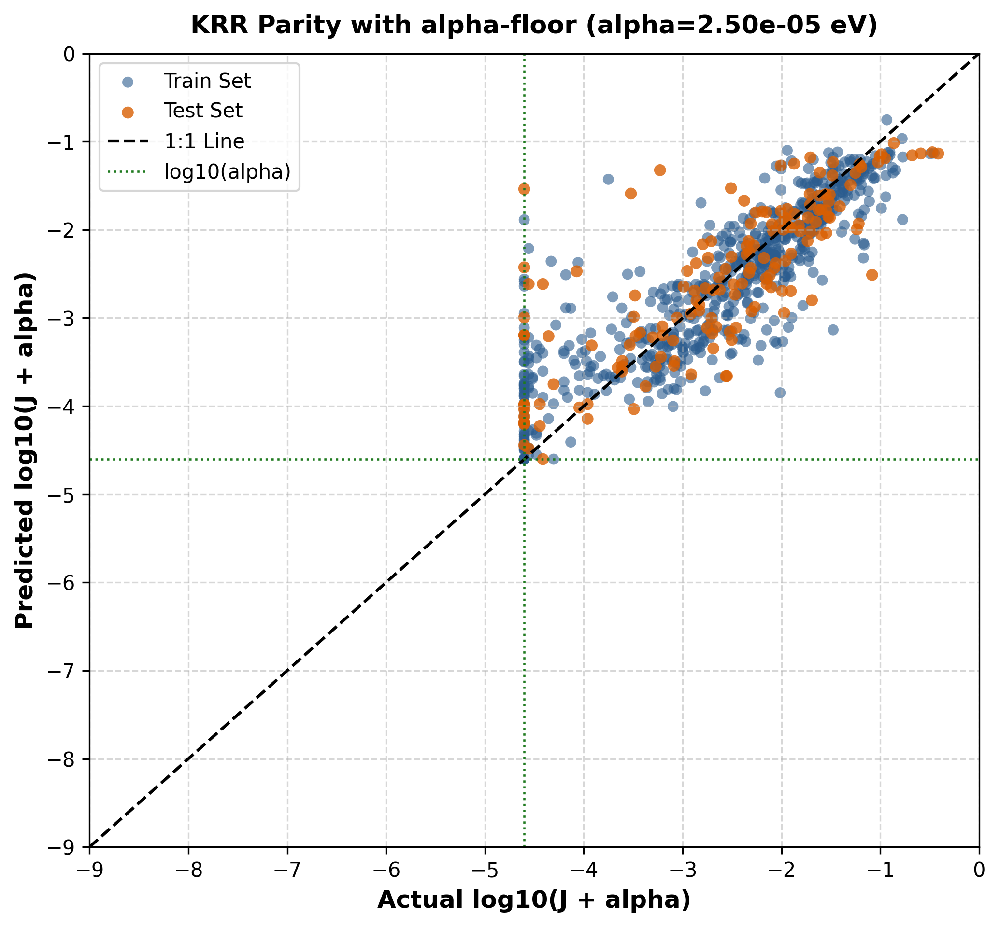

Saved train predictions: ../four-model/full-dataset-with-floor-cap/model-results-fixed-split/prediction-csv-log-linear/KRR_train_predictions_log_linear.csv
Saved test predictions:  ../four-model/full-dataset-with-floor-cap/model-results-fixed-split/prediction-csv-log-linear/KRR_test_predictions_log_linear.csv
Saved parity plot:       ../four-model/full-dataset-with-floor-cap/model-results-fixed-split/parity-plots-log10-space-alpha-floor/KRR_parity_log10_alpha_floor_fixed_axis.png
Floored predictions at log10(alpha): train=7, test=1


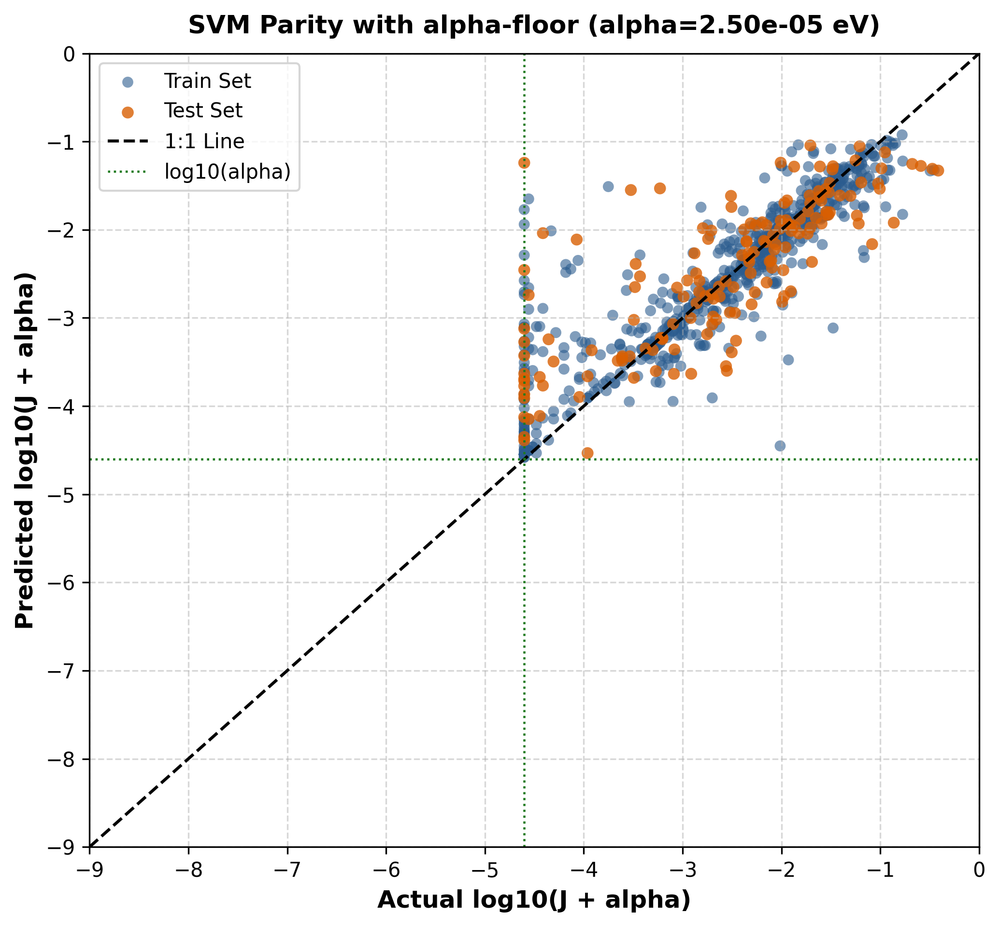

Saved train predictions: ../four-model/full-dataset-with-floor-cap/model-results-fixed-split/prediction-csv-log-linear/SVM_train_predictions_log_linear.csv
Saved test predictions:  ../four-model/full-dataset-with-floor-cap/model-results-fixed-split/prediction-csv-log-linear/SVM_test_predictions_log_linear.csv
Saved parity plot:       ../four-model/full-dataset-with-floor-cap/model-results-fixed-split/parity-plots-log10-space-alpha-floor/SVM_parity_log10_alpha_floor_fixed_axis.png
Floored predictions at log10(alpha): train=0, test=0


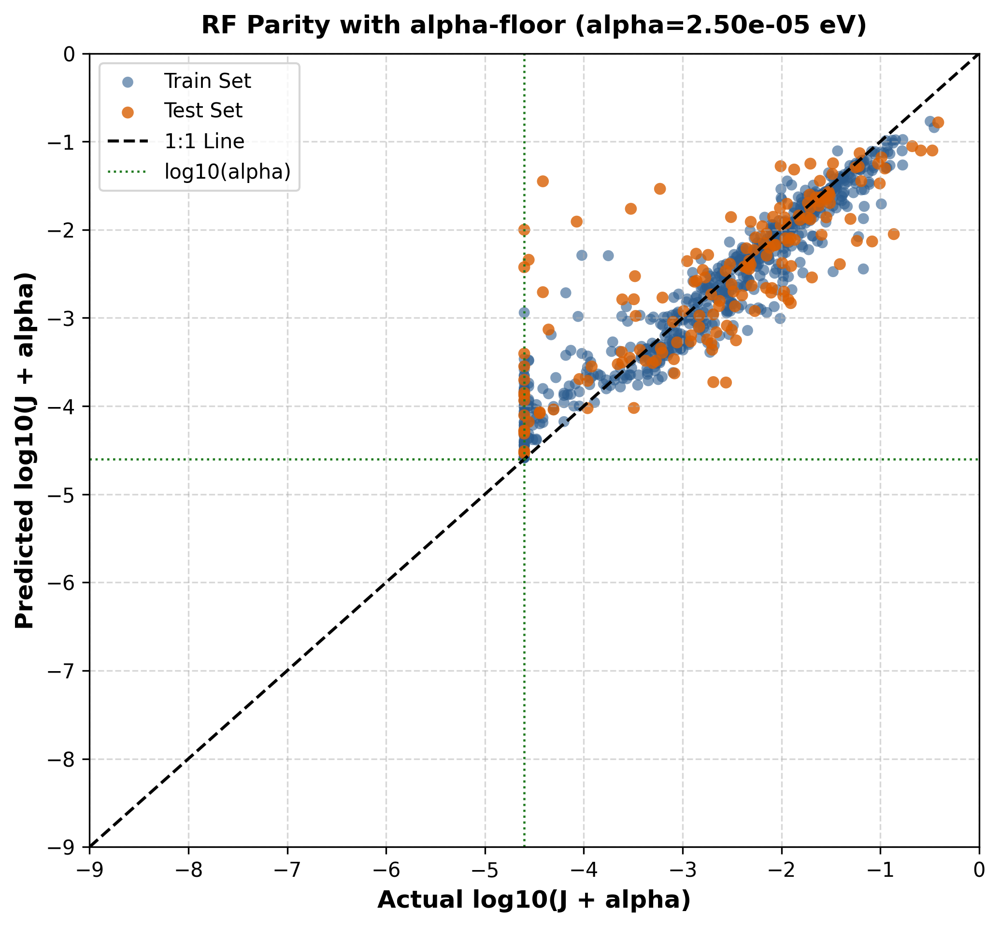

Saved train predictions: ../four-model/full-dataset-with-floor-cap/model-results-fixed-split/prediction-csv-log-linear/RF_train_predictions_log_linear.csv
Saved test predictions:  ../four-model/full-dataset-with-floor-cap/model-results-fixed-split/prediction-csv-log-linear/RF_test_predictions_log_linear.csv
Saved parity plot:       ../four-model/full-dataset-with-floor-cap/model-results-fixed-split/parity-plots-log10-space-alpha-floor/RF_parity_log10_alpha_floor_fixed_axis.png
Floored predictions at log10(alpha): train=0, test=0


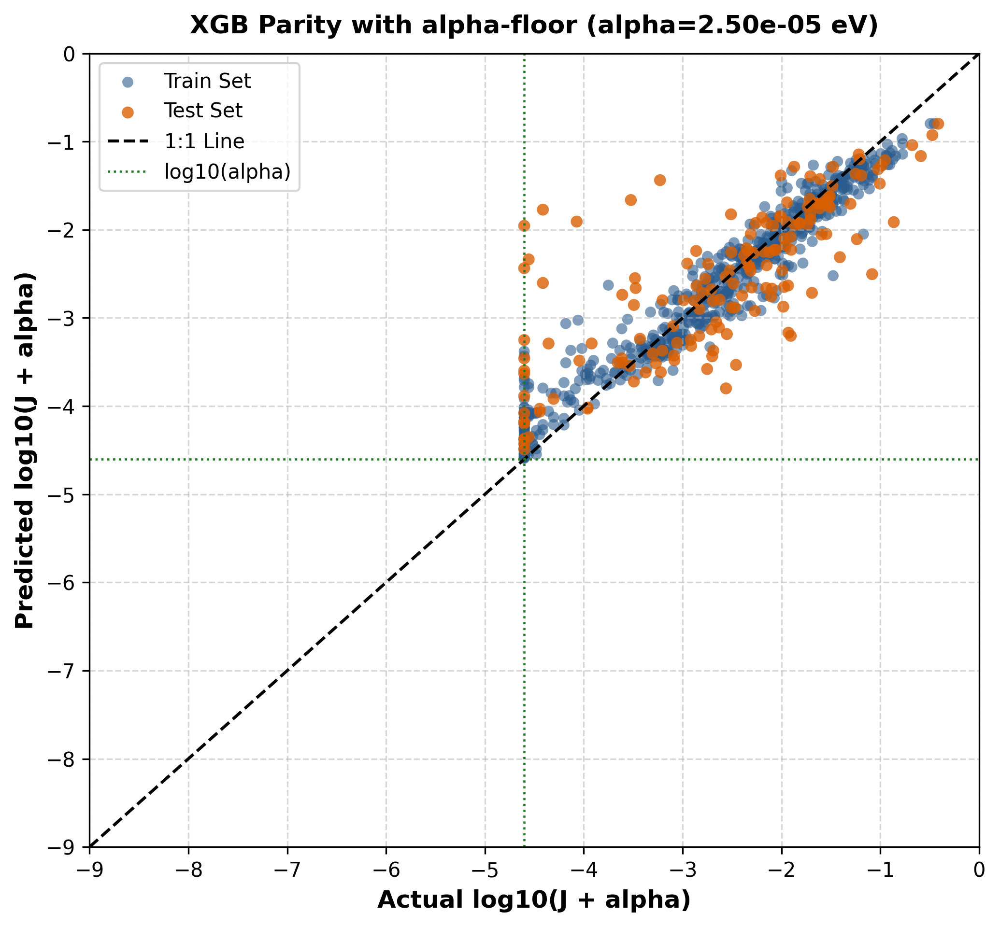

Saved train predictions: ../four-model/full-dataset-with-floor-cap/model-results-fixed-split/prediction-csv-log-linear/XGB_train_predictions_log_linear.csv
Saved test predictions:  ../four-model/full-dataset-with-floor-cap/model-results-fixed-split/prediction-csv-log-linear/XGB_test_predictions_log_linear.csv
Saved parity plot:       ../four-model/full-dataset-with-floor-cap/model-results-fixed-split/parity-plots-log10-space-alpha-floor/XGB_parity_log10_alpha_floor_fixed_axis.png
Floored predictions at log10(alpha): train=0, test=0

Saved combined log/eV/meV summary:
../four-model/full-dataset-with-floor-cap/model-results-fixed-split/ALL_MODELS_PREDICTION_SUMMARY_LOG_LINEAR.csv
Saved parity summary:
../four-model/full-dataset-with-floor-cap/model-results-fixed-split/parity-plots-log10-space-alpha-floor/parity_plot_log10_alpha_floor_summary.csv


,Model,Alpha_Shift_eV,Log10_Alpha,N_train,N_test,N_pred_floor_train,N_pred_floor_test,Train_MAE_log10,Train_R2_log10,Test_MAE_log10,...,Test_RMSE_eV,Test_R2_eV,Train_MAE_meV,Train_RMSE_meV,Train_R2_meV,Test_MAE_meV,Test_RMSE_meV,Test_R2_meV,Train_CSV,Test_CSV
0,KRR,0.000025,-4.60206,646,162,7,1,0.378362,0.748998,0.433902,...,0.039577,0.391353,8.305101,22.481860,0.472626,12.792263,39.577458,0.391353,../four-model/full-dataset-with-floor-cap/mode...,../four-model/full-dataset-with-floor-cap/mode...
1,SVM,0.000025,-4.60206,646,162,0,0,0.286804,0.773823,0.459676,...,0.044628,0.226108,6.820254,22.104069,0.490202,14.494585,44.627757,0.226108,../four-model/full-dataset-with-floor-cap/mode...,../four-model/full-dataset-with-floor-cap/mode...
2,RF,0.000025,-4.60206,646,162,0,0,0.228086,0.898466,0.440894,...,0.036076,0.494284,5.093286,15.839083,0.738234,12.182667,36.076005,0.494284,../four-model/full-dataset-with-floor-cap/mode...,../four-model/full-dataset-with-floor-cap/mode...
3,XGB,0.000025,-4.60206,646,162,0,0,0.195519,0.935374,0.456749,...,0.034797,0.529495,5.420126,15.653136,0.744344,12.038726,34.797439,0.529495,../four-model/full-dataset-with-floor-cap/mode...,../four-model/full-dataset-with-floor-cap/mode...


In [26]:
# =====================================================================
# 10. Prediction export with alpha-floor in log-space + parity plots
# Target: log10(J + alpha), alpha = 2.5e-5 eV
# Rule: if J << alpha, enforce log10(J + alpha) ~= log10(alpha)
# =====================================================================

from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

split_input_dir = Path("../four-model/full-dataset-with-floor-cap/data-split")
model_output_dir = Path("../four-model/full-dataset-with-floor-cap/model-results-fixed-split")
prediction_csv_dir = model_output_dir / "prediction-csv-log-linear"
prediction_csv_dir.mkdir(parents=True, exist_ok=True)

parity_dir = model_output_dir / "parity-plots-log10-space-alpha-floor"
parity_dir.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(split_input_dir / "train_fixed.csv")
test_df = pd.read_csv(split_input_dir / "test_fixed.csv")

#alpha_local = 1e-8
alpha_local = 2.5e-5
log_alpha = float(np.log10(alpha_local))
target_name = "log10_Coupling"
default_features = [
    "Min_HeavyDist_Ang",
    "cos_theta",
    "cos_4phi",
    "cos_4psi",
    "FeFe_Dist_Ang",
]

# Fixed log-axis range for all models (edit these for alpha_shift comparisons).
axis_start_log = -9.0
axis_end_log = 0.0
axis_low_log = min(axis_start_log, axis_end_log)
axis_high_log = max(axis_start_log, axis_end_log)

model_names = ["KRR", "SVM", "RF", "XGB"]
summary_rows = []
parity_rows = []

for model_name in model_names:
    model_path = model_output_dir / "model" / f"{model_name}_fixed_split_model.pkl"
    if not model_path.exists():
        print(f"Skipping {model_name}: model file not found at {model_path}")
        continue

    loaded_obj = joblib.load(model_path)
    if isinstance(loaded_obj, dict):
        model = loaded_obj.get("best_model", loaded_obj)
        model_features = loaded_obj.get("features", globals().get("features", default_features))
    else:
        model = loaded_obj
        model_features = globals().get("features", default_features)

    for df_name, df in [("train", train_df), ("test", test_df)]:
        if target_name not in df.columns:
            if "Coupling_eV" in df.columns:
                df[target_name] = np.log10(df["Coupling_eV"] + alpha_local)
            else:
                raise ValueError(f"{target_name} not found in {df_name}_df and Coupling_eV is unavailable.")

    missing_train = [c for c in model_features if c not in train_df.columns]
    missing_test = [c for c in model_features if c not in test_df.columns]
    if missing_train or missing_test:
        raise ValueError(
            f"Missing feature columns for {model_name}. train missing={missing_train}, test missing={missing_test}"
        )

    train_use = train_df.dropna(subset=model_features + [target_name]).copy()
    test_use = test_df.dropna(subset=model_features + [target_name]).copy()

    X_train_local = train_use[model_features].to_numpy()
    X_test_local = test_use[model_features].to_numpy()

    y_train_log_raw = train_use[target_name].to_numpy(dtype=float)
    y_test_log_raw = test_use[target_name].to_numpy(dtype=float)
    y_pred_train_log_raw = model.predict(X_train_local).astype(float)
    y_pred_test_log_raw = model.predict(X_test_local).astype(float)

    y_train_log = np.maximum(y_train_log_raw, log_alpha)
    y_test_log = np.maximum(y_test_log_raw, log_alpha)
    y_pred_train_log = np.maximum(y_pred_train_log_raw, log_alpha)
    y_pred_test_log = np.maximum(y_pred_test_log_raw, log_alpha)

    y_train_shifted = 10.0 ** y_train_log
    y_test_shifted = 10.0 ** y_test_log
    y_pred_train_shifted = 10.0 ** y_pred_train_log
    y_pred_test_shifted = 10.0 ** y_pred_test_log

    y_train_eV = np.maximum(y_train_shifted, 0.0)
    y_test_eV = np.maximum(y_test_shifted, 0.0)
    y_pred_train_eV = np.maximum(y_pred_train_shifted, 0.0)
    y_pred_test_eV = np.maximum(y_pred_test_shifted, 0.0)

    y_train_meV = y_train_eV * 1000.0
    y_test_meV = y_test_eV * 1000.0
    y_pred_train_meV = y_pred_train_eV * 1000.0
    y_pred_test_meV = y_pred_test_eV * 1000.0

    keep_id_cols = [c for c in ["source_row_id", "dataset_split", "stratify_bin"] if c in train_use.columns]

    train_export = train_use[keep_id_cols].copy()
    train_export["actual_log10"] = y_train_log
    train_export["pred_log10"] = y_pred_train_log
    train_export["actual_eV"] = y_train_eV
    train_export["pred_eV"] = y_pred_train_eV
    train_export["actual_meV"] = y_train_meV
    train_export["pred_meV"] = y_pred_train_meV
    train_export["abs_err_log10"] = np.abs(y_train_log - y_pred_train_log)
    train_export["abs_err_eV"] = np.abs(y_train_eV - y_pred_train_eV)
    train_export["abs_err_meV"] = np.abs(y_train_meV - y_pred_train_meV)

    test_export = test_use[[c for c in keep_id_cols if c in test_use.columns]].copy()
    test_export["actual_log10"] = y_test_log
    test_export["pred_log10"] = y_pred_test_log
    test_export["actual_eV"] = y_test_eV
    test_export["pred_eV"] = y_pred_test_eV
    test_export["actual_meV"] = y_test_meV
    test_export["pred_meV"] = y_pred_test_meV
    test_export["abs_err_log10"] = np.abs(y_test_log - y_pred_test_log)
    test_export["abs_err_eV"] = np.abs(y_test_eV - y_pred_test_eV)
    test_export["abs_err_meV"] = np.abs(y_test_meV - y_pred_test_meV)

    train_out = prediction_csv_dir / f"{model_name}_train_predictions_log_linear.csv"
    test_out = prediction_csv_dir / f"{model_name}_test_predictions_log_linear.csv"
    train_export.to_csv(train_out, index=False)
    test_export.to_csv(test_out, index=False)

    n_floor_train = int(np.sum(y_pred_train_log_raw < log_alpha))
    n_floor_test = int(np.sum(y_pred_test_log_raw < log_alpha))

    plt.figure(figsize=(7, 6.5), dpi=300)
    plt.scatter(y_train_log, y_pred_train_log, alpha=0.6, color="#2b5c8f", label="Train Set", edgecolors="none", s=30)
    plt.scatter(y_test_log, y_pred_test_log, alpha=0.8, color="#d95f02", label="Test Set", edgecolors="none", s=35)
    plt.plot([axis_low_log, axis_high_log], [axis_low_log, axis_high_log], "k--", linewidth=1.5, label="1:1 Line")
    plt.xlim(axis_start_log, axis_end_log)
    plt.ylim(axis_start_log, axis_end_log)
    plt.axvline(log_alpha, color="#1f7a1f", linestyle=":", linewidth=1.1, label="log10(alpha)")
    plt.axhline(log_alpha, color="#1f7a1f", linestyle=":", linewidth=1.1)
    plt.xlabel("Actual log10(J + alpha)", fontsize=12, fontweight="bold")
    plt.ylabel("Predicted log10(J + alpha)", fontsize=12, fontweight="bold")
    plt.title(f"{model_name} Parity with alpha-floor (alpha={alpha_local:.2e} eV)", fontsize=12.5, fontweight="bold", pad=10)
    plt.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="#cccccc")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    parity_plot_path = parity_dir / f"{model_name}_parity_log10_alpha_floor_fixed_axis.png"
    plt.savefig(parity_plot_path, dpi=300)
    plt.show()

    summary_rows.append({
        "Model": model_name,
        "Alpha_Shift_eV": alpha_local,
        "Log10_Alpha": log_alpha,
        "N_train": len(train_export),
        "N_test": len(test_export),
        "N_pred_floor_train": n_floor_train,
        "N_pred_floor_test": n_floor_test,
        "Train_MAE_log10": mean_absolute_error(y_train_log, y_pred_train_log),
        "Train_R2_log10": r2_score(y_train_log, y_pred_train_log),
        "Test_MAE_log10": mean_absolute_error(y_test_log, y_pred_test_log),
        "Test_R2_log10": r2_score(y_test_log, y_pred_test_log),
        "Train_MAE_eV": mean_absolute_error(y_train_eV, y_pred_train_eV),
        "Train_RMSE_eV": np.sqrt(mean_squared_error(y_train_eV, y_pred_train_eV)),
        "Train_R2_eV": r2_score(y_train_eV, y_pred_train_eV),
        "Test_MAE_eV": mean_absolute_error(y_test_eV, y_pred_test_eV),
        "Test_RMSE_eV": np.sqrt(mean_squared_error(y_test_eV, y_pred_test_eV)),
        "Test_R2_eV": r2_score(y_test_eV, y_pred_test_eV),
        "Train_MAE_meV": mean_absolute_error(y_train_meV, y_pred_train_meV),
        "Train_RMSE_meV": np.sqrt(mean_squared_error(y_train_meV, y_pred_train_meV)),
        "Train_R2_meV": r2_score(y_train_meV, y_pred_train_meV),
        "Test_MAE_meV": mean_absolute_error(y_test_meV, y_pred_test_meV),
        "Test_RMSE_meV": np.sqrt(mean_squared_error(y_test_meV, y_pred_test_meV)),
        "Test_R2_meV": r2_score(y_test_meV, y_pred_test_meV),
        "Train_CSV": str(train_out),
        "Test_CSV": str(test_out),
    })

    parity_rows.append({
        "Model": model_name,
        "Alpha_Shift_eV": alpha_local,
        "Log10_Alpha": log_alpha,
        "Axis_Start_Log10": axis_start_log,
        "Axis_End_Log10": axis_end_log,
        "N_pred_floor_train": n_floor_train,
        "N_pred_floor_test": n_floor_test,
        "Train_MAE_log10": mean_absolute_error(y_train_log, y_pred_train_log),
        "Train_R2_log10": r2_score(y_train_log, y_pred_train_log),
        "Test_MAE_log10": mean_absolute_error(y_test_log, y_pred_test_log),
        "Test_R2_log10": r2_score(y_test_log, y_pred_test_log),
        "Parity_Plot_Path": str(parity_plot_path),
    })

    print(f"Saved train predictions: {train_out}")
    print(f"Saved test predictions:  {test_out}")
    print(f"Saved parity plot:       {parity_plot_path}")
    print(f"Floored predictions at log10(alpha): train={n_floor_train}, test={n_floor_test}")

summary_df = pd.DataFrame(summary_rows)
summary_out = model_output_dir / "ALL_MODELS_PREDICTION_SUMMARY_LOG_LINEAR.csv"
summary_df.to_csv(summary_out, index=False)

parity_summary_df = pd.DataFrame(parity_rows)
parity_summary_out = parity_dir / "parity_plot_log10_alpha_floor_summary.csv"
parity_summary_df.to_csv(parity_summary_out, index=False)

print()
print("Saved combined log/eV/meV summary:")
print(summary_out)
print("Saved parity summary:")
print(parity_summary_out)
summary_df


In [ ]:
# This helper cell is intentionally disabled.
# Use Cell 9, which now generates fixed-axis parity plots for all four models.
print("Cell 10 disabled: run Cell 9 for all-model fixed-axis parity plots.")


# Parity plot in log scale with alpha 

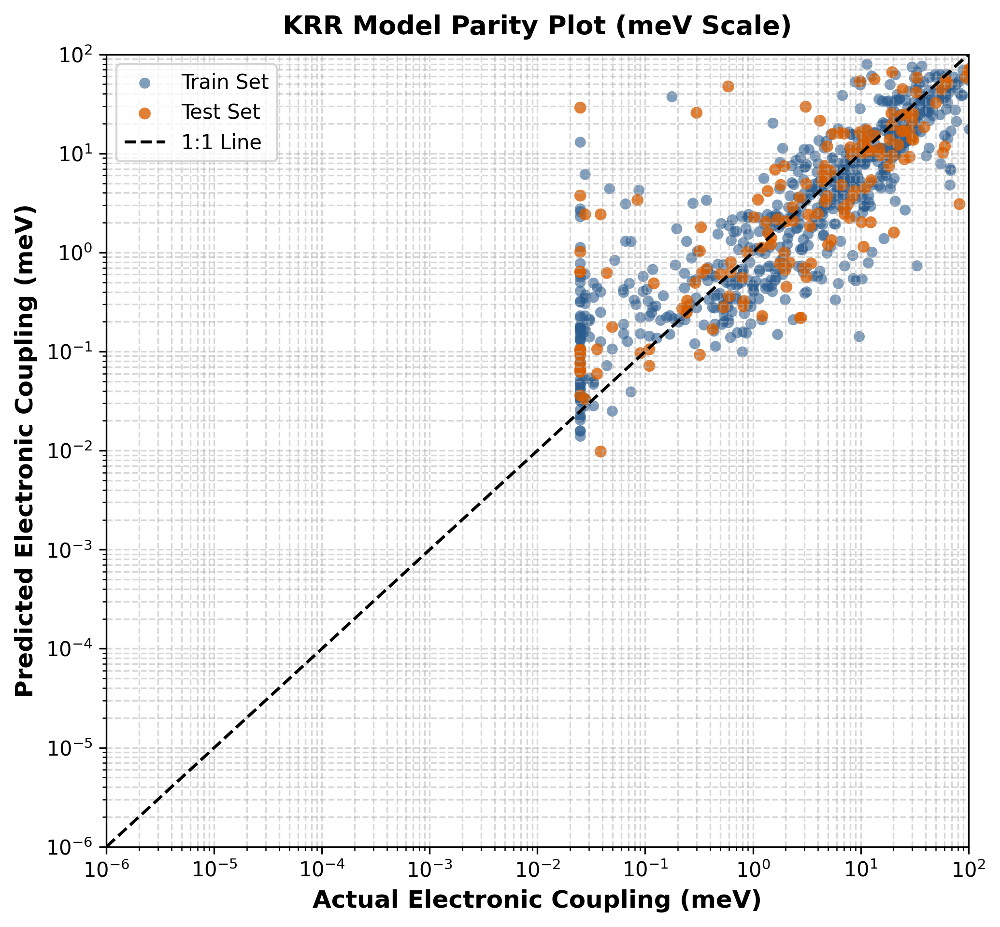

Saved parity plot for KRR: ../four-model/full-dataset-with-floor-cap/model-results-fixed-split/parity-plots-mev/KRR_fixed_split_parity_meV.png


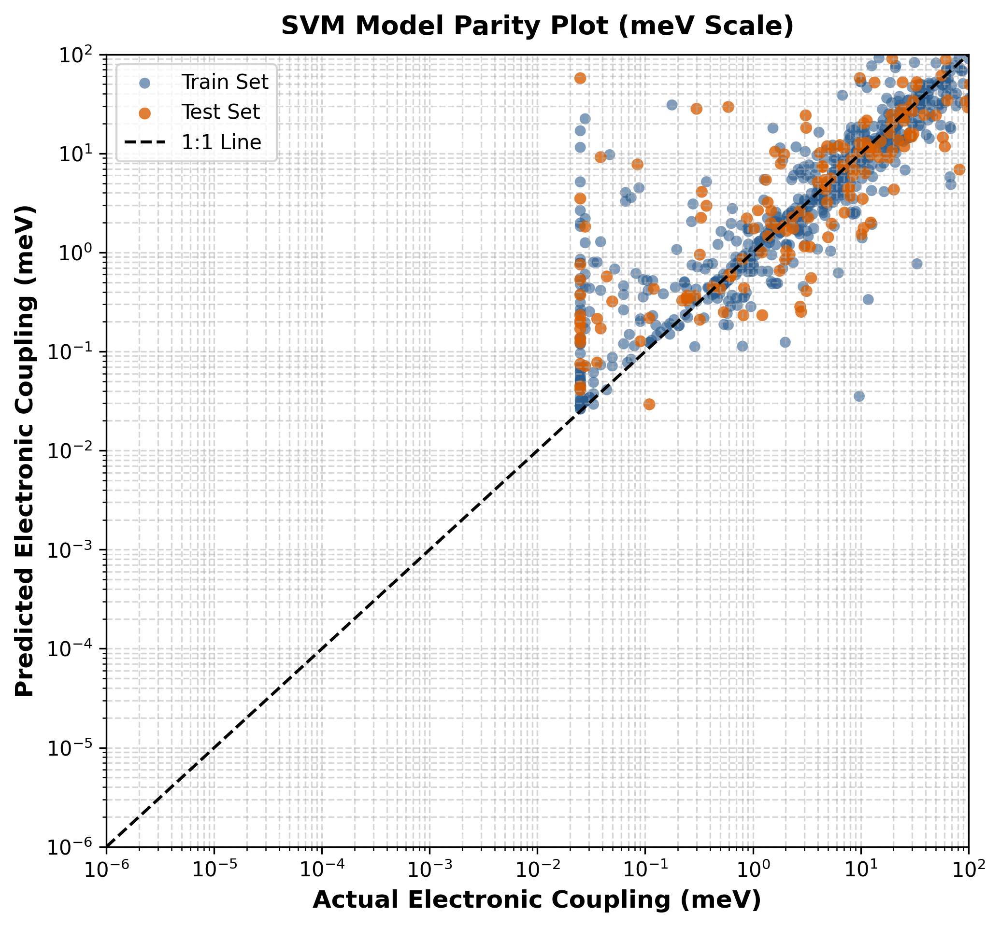

Saved parity plot for SVM: ../four-model/full-dataset-with-floor-cap/model-results-fixed-split/parity-plots-mev/SVM_fixed_split_parity_meV.png


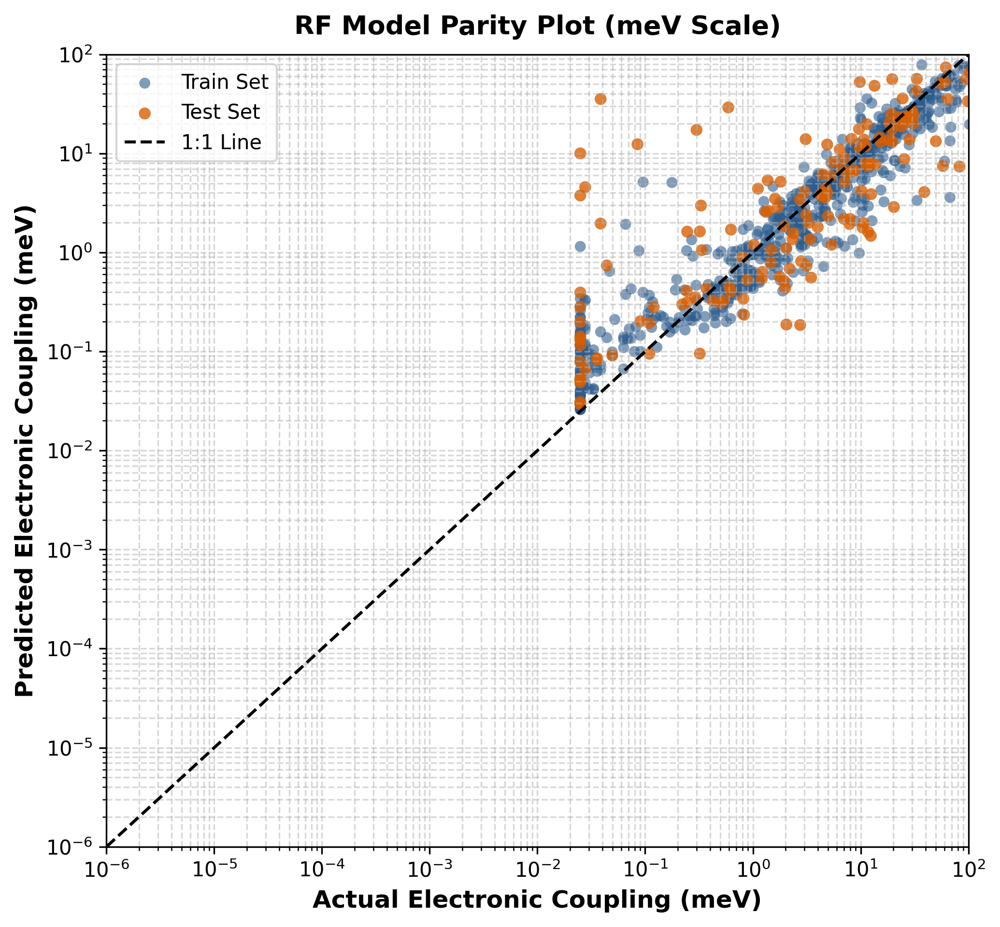

Saved parity plot for RF: ../four-model/full-dataset-with-floor-cap/model-results-fixed-split/parity-plots-mev/RF_fixed_split_parity_meV.png


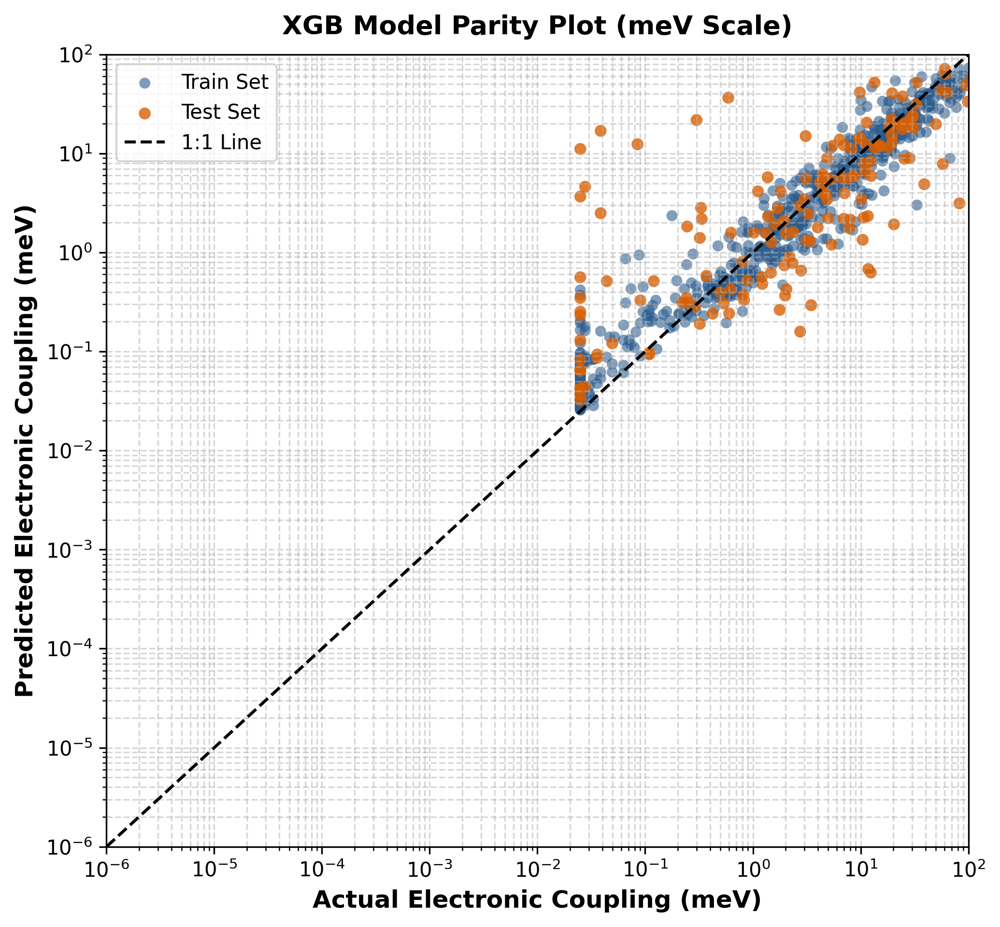

Saved parity plot for XGB: ../four-model/full-dataset-with-floor-cap/model-results-fixed-split/parity-plots-mev/XGB_fixed_split_parity_meV.png
Saved parity plot file list: ../four-model/full-dataset-with-floor-cap/model-results-fixed-split/parity-plots-mev/parity_plot_files.csv


In [18]:
# =====================================================================
# 6. Generate & Save Parity Plots (Physical meV Scale) for All 4 Models
# =====================================================================

import matplotlib.pyplot as plt

parity_output_dir = model_output_dir / "parity-plots-mev"
parity_output_dir.mkdir(parents=True, exist_ok=True)

# Use the saved best models from cell 6.
model_names = ["KRR", "SVM", "RF", "XGB"]

# Fixed axis range shared by all four models (edit these two values when needed).
axis_start_meV = 1e-6
axis_end_meV = 1e2
axis_low_meV = min(axis_start_meV, axis_end_meV)
axis_high_meV = max(axis_start_meV, axis_end_meV)
if axis_low_meV <= 0:
    raise ValueError("For log-scale parity plots, axis limits must be > 0.")

plot_summary_rows = []

for model_name in model_names:
    model_path = model_output_dir / "model" / f"{model_name}_fixed_split_model.pkl"
    if not model_path.exists():
        print(f"Skipping {model_name}: model file not found at {model_path}")
        continue

    loaded_obj = joblib.load(model_path)
    model = loaded_obj["best_model"] if isinstance(loaded_obj, dict) and "best_model" in loaded_obj else loaded_obj

    y_pred_train_log = model.predict(X_train)
    y_pred_test_log = model.predict(X_test)

    y_train_meV_act = (10 ** y_train) * 1000.0
    y_train_meV_pred = (10 ** y_pred_train_log) * 1000.0
    y_test_meV_act = (10 ** y_test) * 1000.0
    y_test_meV_pred = (10 ** y_pred_test_log) * 1000.0

    # Log-scale axes require strictly positive values.
    min_meV = 1e-6
    y_train_meV_act = np.clip(y_train_meV_act, min_meV, None)
    y_train_meV_pred = np.clip(y_train_meV_pred, min_meV, None)
    y_test_meV_act = np.clip(y_test_meV_act, min_meV, None)
    y_test_meV_pred = np.clip(y_test_meV_pred, min_meV, None)

    plt.figure(figsize=(7, 6.5), dpi=300)

    plt.scatter(
        y_train_meV_act,
        y_train_meV_pred,
        alpha=0.6,
        color="#2b5c8f",
        label="Train Set",
        edgecolors="none",
        s=30,
    )
    plt.scatter(
        y_test_meV_act,
        y_test_meV_pred,
        alpha=0.8,
        color="#d95f02",
        label="Test Set",
        edgecolors="none",
        s=35,
    )

    plt.plot([axis_low_meV, axis_high_meV], [axis_low_meV, axis_high_meV], "k--", linewidth=1.5, label="1:1 Line")

    plt.xscale("log")
    plt.yscale("log")
    plt.xlim(axis_low_meV, axis_high_meV)
    plt.ylim(axis_low_meV, axis_high_meV)

    plt.xlabel("Actual Electronic Coupling (meV)", fontsize=12, fontweight="bold")
    plt.ylabel("Predicted Electronic Coupling (meV)", fontsize=12, fontweight="bold")
    plt.title(f"{model_name} Model Parity Plot (meV Scale)", fontsize=13, fontweight="bold", pad=10)
    plt.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="#cccccc")
    plt.grid(True, which="both", linestyle="--", alpha=0.5)
    plt.tight_layout()

    parity_plot_path = parity_output_dir / f"{model_name}_fixed_split_parity_meV.png"
    plt.savefig(parity_plot_path, dpi=300)
    plt.show()

    print(f"Saved parity plot for {model_name}: {parity_plot_path}")

    plot_summary_rows.append({
        "Model": model_name,
        "Axis_Start_meV": axis_start_meV,
        "Axis_End_meV": axis_end_meV,
        "Parity_Plot_Path": str(parity_plot_path),
    })

if plot_summary_rows:
    parity_summary_path = parity_output_dir / "parity_plot_files.csv"
    pd.DataFrame(plot_summary_rows).to_csv(parity_summary_path, index=False)
    print(f"Saved parity plot file list: {parity_summary_path}")


# Parity plot comparison with two differnt alpha (10-9 and 2.5-5)

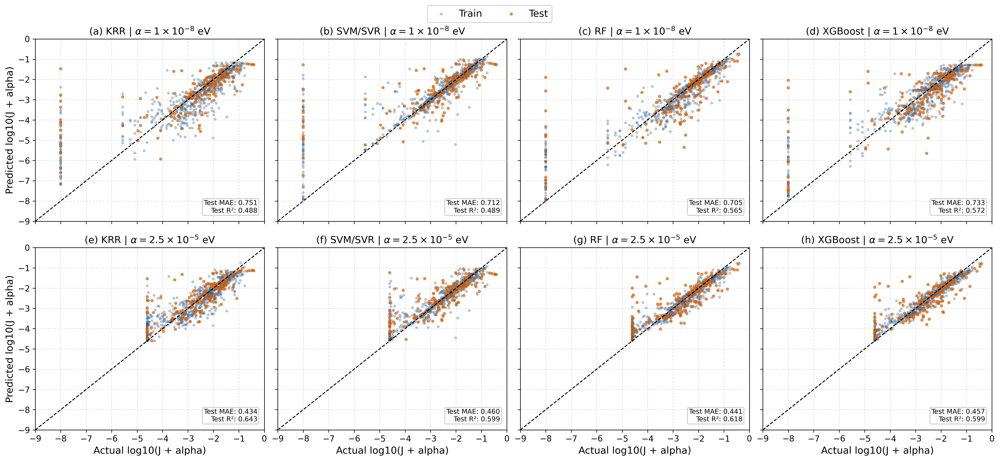

Saved 2x4 comparison plot: ../four-model/full-dataset-with-floor-cap/parity_2x4_alpha_comparison_shared_axes_pubstyle.png
Shared axis limits used: x,y = [-9.0, 0.0]
Panel metrics shown: True (mode=test)


In [ ]:
# =====================================================================
# 2x4 parity comparison across two alpha settings (publication style)
# Top row: alpha = 1e-8 eV, Bottom row: alpha = 2.5e-5 eV
# Shared axis limits are enforced for all panels.
# =====================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score

# -----------------------------
# User controls
# -----------------------------
axis_start_log = -9.0
axis_end_log = 0.0
show_panel_metrics = True        # Set False to hide MAE/R2 text boxes
metrics_on = "test"             # "test" or "both"

# Font and style controls (publication polish)
suptitle_fs = 20
panel_title_fs = 13
axis_label_fs = 13
tick_fs = 11
metric_fs = 9
legend_fs = 13

train_color = "#2b5c8f"
test_color = "#d95f02"

train_s = 14
test_s = 18

axis_low_log = min(axis_start_log, axis_end_log)
axis_high_log = max(axis_start_log, axis_end_log)

alpha_runs = [
    {
        #"label": "alpha = 1x10^{-8} eV",
        "label": r"$\alpha = 1 \times 10^{-8}$ eV",
        "root": Path("../four-model/full-dataset-with-floor-cap/redo-10-8-cutoff"),
    },
    {
        "label": r"$\alpha = 2.5 \times 10^{-5}$ eV",
        "root": Path("../four-model/full-dataset-with-floor-cap/redo-2.5-10-5-cutoff"),
    },
]

model_names = ["KRR", "SVM", "RF", "XGB"]
model_titles = {"KRR": "KRR", "SVM": "SVM", "RF": "RF", "XGB": "XGBoost"}
panel_tags = list("abcdefgh")

fig, axes = plt.subplots(2, 4, figsize=(19, 9), dpi=300, sharex=True, sharey=True)

for row_idx, run_info in enumerate(alpha_runs):
    pred_dir = run_info["root"] / "model-results-fixed-split" / "prediction-csv-log-linear"

    for col_idx, model_name in enumerate(model_names):
        ax = axes[row_idx, col_idx]
        panel_tag = panel_tags[row_idx * 4 + col_idx]

        train_csv = pred_dir / f"{model_name}_train_predictions_log_linear.csv"
        test_csv = pred_dir / f"{model_name}_test_predictions_log_linear.csv"

        if (not train_csv.exists()) or (not test_csv.exists()):
            ax.text(
                0.5,
                0.5,
                f"Missing CSV\n{model_name}",
                ha="center",
                va="center",
                transform=ax.transAxes,
                fontsize=11,
            )
            ax.set_xlim(axis_low_log, axis_high_log)
            ax.set_ylim(axis_low_log, axis_high_log)
            ax.grid(True, linestyle="--", alpha=0.35)
            ax.set_title(f"({panel_tag}) {model_titles[model_name]} | {run_info['label']}", fontsize=panel_title_fs)
            continue

        train_df = pd.read_csv(train_csv)
        test_df = pd.read_csv(test_csv)
        needed = {"actual_log10", "pred_log10"}

        if (not needed.issubset(train_df.columns)) or (not needed.issubset(test_df.columns)):
            ax.text(
                0.5,
                0.5,
                f"Missing columns\n{model_name}",
                ha="center",
                va="center",
                transform=ax.transAxes,
                fontsize=11,
            )
            ax.set_xlim(axis_low_log, axis_high_log)
            ax.set_ylim(axis_low_log, axis_high_log)
            ax.grid(True, linestyle="--", alpha=0.35)
            ax.set_title(f"({panel_tag}) {model_titles[model_name]} | {run_info['label']}", fontsize=panel_title_fs)
            continue

        x_train = train_df["actual_log10"].to_numpy(dtype=float)
        y_train_pred = train_df["pred_log10"].to_numpy(dtype=float)
        x_test = test_df["actual_log10"].to_numpy(dtype=float)
        y_test_pred = test_df["pred_log10"].to_numpy(dtype=float)

        ax.scatter(x_train, y_train_pred, s=train_s, alpha=0.35, color=train_color, edgecolors="none", label="Train")
        ax.scatter(x_test, y_test_pred, s=test_s, alpha=0.72, color=test_color, edgecolors="none", label="Test")
        ax.plot([axis_low_log, axis_high_log], [axis_low_log, axis_high_log], "k--", lw=1.2)

        ax.set_xlim(axis_low_log, axis_high_log)
        ax.set_ylim(axis_low_log, axis_high_log)
        ax.grid(True, linestyle="--", alpha=0.35)
        ax.set_title(f"({panel_tag}) {model_titles[model_name]} | {run_info['label']}", fontsize=panel_title_fs)
        ax.tick_params(axis="both", labelsize=tick_fs)

        if row_idx == 1:
            ax.set_xlabel("Actual log10(J + alpha)", fontsize=axis_label_fs)
        if col_idx == 0:
            ax.set_ylabel("Predicted log10(J + alpha)", fontsize=axis_label_fs)

        if show_panel_metrics:
            test_mae = mean_absolute_error(x_test, y_test_pred)
            test_r2 = r2_score(x_test, y_test_pred)

            if metrics_on == "both":
                train_mae = mean_absolute_error(x_train, y_train_pred)
                train_r2 = r2_score(x_train, y_train_pred)
                metric_text = (
                    f"Train MAE: {train_mae:.3f}\n"
                    f"Train R2: {train_r2:.3f}\n"
                    f"Test MAE:  {test_mae:.3f}\n"
                    f"Test R\u00b2:  {test_r2:.3f}"
                )
            else:
                metric_text = (
                    f"Test MAE: {test_mae:.3f}\n"
                    f"Test R\u00b2: {test_r2:.3f}"
                )

            ax.text(
                0.97,
                0.04,
                metric_text,
                transform=ax.transAxes,
                fontsize=metric_fs,
                va="top",
                ha="left",
                bbox={"facecolor": "white", "edgecolor": "#b3b3b3", "alpha": 0.75, "boxstyle": "round,pad=0.2"},
            )

# Clean legend placement above panels, below title zone.
handles, labels = axes[0, 0].get_legend_handles_labels()
if handles:
    fig.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.975),
        ncol=2,
        frameon=True,
        edgecolor="#bfbfbf",
        fontsize=legend_fs,
    )

#fig.suptitle("Parity Comparison Across Two alpha Settings (Shared Limits)", fontsize=suptitle_fs, fontweight="bold", y=0.995)
fig.suptitle("Correlation of log(J+alpha)", fontsize=suptitle_fs, fontweight="bold", y=0.995)
fig.tight_layout(rect=[0.02, 0.02, 1, 0.94])

out_dir = Path("../four-model/full-dataset-with-floor-cap")
out_dir.mkdir(parents=True, exist_ok=True)
out_png = out_dir / "parity_2x4_alpha_comparison_shared_axes_2.png"
fig.savefig(out_png, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved 2x4 comparison plot: {out_png}")
print(f"Shared axis limits used: x,y = [{axis_low_log}, {axis_high_log}]")
print(f"Panel metrics shown: {show_panel_metrics} (mode={metrics_on})")



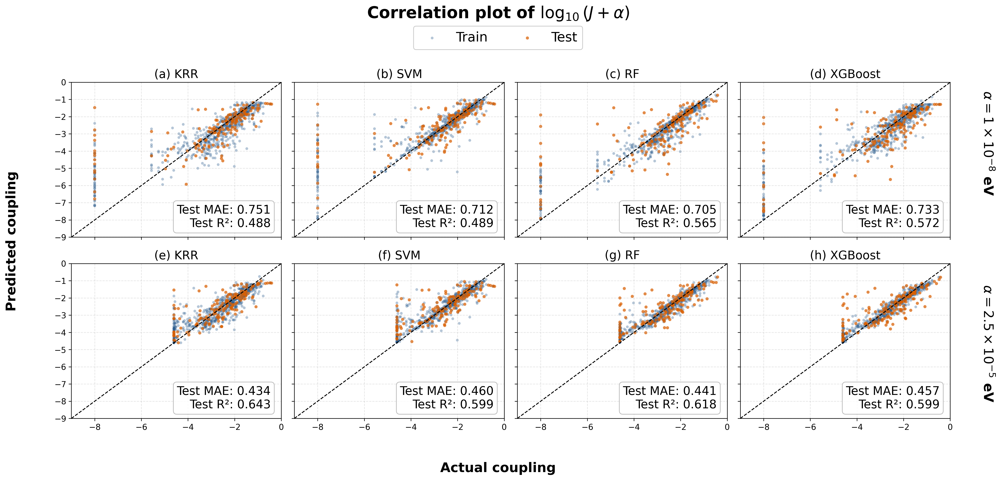

In [ ]:
# =====================================================================
# 2x4 parity comparison across two alpha settings (publication style)
# Top row: alpha = 1e-8 eV, Bottom row: alpha = 2.5e-5 eV
# Shared axis limits are enforced for all panels.
# =====================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score

# -----------------------------
# User controls
# -----------------------------
axis_start_log = -9.0
axis_end_log = 0.0
show_panel_metrics = True        # Set False to hide MAE/R2 text boxes
metrics_on = "test"             # "test" or "both"

# Font and style controls (publication polish)
suptitle_fs = 22
panel_title_fs = 16
axis_label_fs = 16
tick_fs = 11
metric_fs = 16                   # Increased font size for MAE / R2
legend_fs = 18                   # Increased legend font size
row_label_fs = 18                # Font size for row-level alpha labels

train_color = "#2b5c8f"
test_color = "#d95f02"

train_s = 14
test_s = 18

axis_low_log = min(axis_start_log, axis_end_log)
axis_high_log = max(axis_start_log, axis_end_log)

alpha_runs = [
    {
        "label": r"$\alpha = 1 \times 10^{-8}$ eV",
        "root": Path("../four-model/full-dataset-with-floor-cap/redo-10-8-cutoff"),
    },
    {
        "label": r"$\alpha = 2.5 \times 10^{-5}$ eV",
        "root": Path("../four-model/full-dataset-with-floor-cap/redo-2.5-10-5-cutoff"),
    },
]

model_names = ["KRR", "SVM", "RF", "XGB"]
model_titles = {"KRR": "KRR", "SVM": "SVM", "RF": "RF", "XGB": "XGBoost"}
panel_tags = list("abcdefgh")

fig, axes = plt.subplots(2, 4, figsize=(19, 9), dpi=300, sharex=True, sharey=True)

for row_idx, run_info in enumerate(alpha_runs):
    pred_dir = run_info["root"] / "model-results-fixed-split" / "prediction-csv-log-linear"

    for col_idx, model_name in enumerate(model_names):
        ax = axes[row_idx, col_idx]
        panel_tag = panel_tags[row_idx * 4 + col_idx]

        train_csv = pred_dir / f"{model_name}_train_predictions_log_linear.csv"
        test_csv = pred_dir / f"{model_name}_test_predictions_log_linear.csv"

        if (not train_csv.exists()) or (not test_csv.exists()):
            ax.text(
                0.5,
                0.5,
                f"Missing CSV\n{model_name}",
                ha="center",
                va="center",
                transform=ax.transAxes,
                fontsize=11,
            )
            ax.set_xlim(axis_low_log, axis_high_log)
            ax.set_ylim(axis_low_log, axis_high_log)
            ax.grid(True, linestyle="--", alpha=0.35)
            ax.set_title(f"({panel_tag}) {model_titles[model_name]}", fontsize=panel_title_fs)
            continue

        train_df = pd.read_csv(train_csv)
        test_df = pd.read_csv(test_csv)
        needed = {"actual_log10", "pred_log10"}

        if (not needed.issubset(train_df.columns)) or (not needed.issubset(test_df.columns)):
            ax.text(
                0.5,
                0.5,
                f"Missing columns\n{model_name}",
                ha="center",
                va="center",
                transform=ax.transAxes,
                fontsize=11,
            )
            ax.set_xlim(axis_low_log, axis_high_log)
            ax.set_ylim(axis_low_log, axis_high_log)
            ax.grid(True, linestyle="--", alpha=0.35)
            ax.set_title(f"({panel_tag}) {model_titles[model_name]}", fontsize=panel_title_fs)
            continue

        x_train = train_df["actual_log10"].to_numpy(dtype=float)
        y_train_pred = train_df["pred_log10"].to_numpy(dtype=float)
        x_test = test_df["actual_log10"].to_numpy(dtype=float)
        y_test_pred = test_df["pred_log10"].to_numpy(dtype=float)

        ax.scatter(x_train, y_train_pred, s=train_s, alpha=0.35, color=train_color, edgecolors="none", label="Train")
        ax.scatter(x_test, y_test_pred, s=test_s, alpha=0.72, color=test_color, edgecolors="none", label="Test")
        ax.plot([axis_low_log, axis_high_log], [axis_low_log, axis_high_log], "k--", lw=1.2)

        ax.set_xlim(axis_low_log, axis_high_log)
        ax.set_ylim(axis_low_log, axis_high_log)
        ax.grid(True, linestyle="--", alpha=0.35)
        ax.set_title(f"({panel_tag}) {model_titles[model_name]}", fontsize=panel_title_fs)
        ax.tick_params(axis="both", labelsize=tick_fs)

        # Updated axis labels
        # if row_idx == 1:
        #     ax.set_xlabel("Actual coupling", fontsize=axis_label_fs, fontweight="bold")
        # if col_idx == 0:
        #     ax.set_ylabel("Predicted coupling", fontsize=axis_label_fs, fontweight="bold")
        # Single centered axis labels for the entire figure
        fig.supxlabel("Actual coupling", fontsize=axis_label_fs + 2, fontweight="bold", y=0.01)
        fig.supylabel("Predicted coupling", fontsize=axis_label_fs + 2, fontweight="bold", x=0.01)

        if show_panel_metrics:
            test_mae = mean_absolute_error(x_test, y_test_pred)
            test_r2 = r2_score(x_test, y_test_pred)

            if metrics_on == "both":
                train_mae = mean_absolute_error(x_train, y_train_pred)
                train_r2 = r2_score(x_train, y_train_pred)
                metric_text = (
                    f"Train MAE: {train_mae:.3f}\n"
                    f"Train R2: {train_r2:.3f}\n"
                    f"Test MAE:  {test_mae:.3f}\n"
                    f"Test R\u00b2:  {test_r2:.3f}"
                )
            else:
                metric_text = (
                    f"Test MAE: {test_mae:.3f}\n"
                    f"Test R\u00b2: {test_r2:.3f}"
                )

            # Placed inside bottom-right with increased font size
            ax.text(
                0.95,
                0.05,
                metric_text,
                transform=ax.transAxes,
                fontsize=metric_fs,
                va="bottom",
                ha="right",
                bbox={"facecolor": "white", "edgecolor": "#b3b3b3", "alpha": 0.85, "boxstyle": "round,pad=0.3"},
            )
            # (Inside the loop: remove individual ax.set_xlabel and ax.set_ylabel)

    # Label for each row (alpha setting) on the far right margin
    row_center_y = axes[row_idx, 3].get_position().y0 + axes[row_idx, 3].get_position().height / 2
    fig.text(
        0.98,
        row_center_y,
        run_info["label"],
        va="center",
        ha="left",
        fontsize=row_label_fs,
        fontweight="bold",
        rotation=-90,
    )

# Clean legend placement above panels
handles, labels = axes[0, 0].get_legend_handles_labels()
if handles:
    fig.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.965),
        ncol=2,
        frameon=True,
        edgecolor="#bfbfbf",
        fontsize=legend_fs,
    )

# Global Figure Title
fig.suptitle(r"Correlation plot of $\log_{10}(J + \alpha)$", fontsize=suptitle_fs, fontweight="bold", y=0.995)

# Single Centered X and Y Axis Labels
fig.supxlabel("Actual coupling", fontsize=axis_label_fs + 2, fontweight="bold", y=0.01)
fig.supylabel("Predicted coupling", fontsize=axis_label_fs + 2, fontweight="bold", x=0.01)

# Adjust rect to leave padding for global supxlabel/supylabel
fig.tight_layout(rect=[0.03, 0.04, 0.96, 0.93])

out_dir = Path("../four-model/full-dataset-with-floor-cap")
out_dir.mkdir(parents=True, exist_ok=True)
out_png = out_dir / "parity_2x4_alpha_comparison_shared_axes_2.png"
fig.savefig(out_png, dpi=300, bbox_inches="tight")
plt.show()
    # Label for each row (alpha setting) on the far right margin
#     row_center_y = axes[row_idx, 3].get_position().y0 + axes[row_idx, 3].get_position().height / 2
#     fig.text(
#         0.98,
#         row_center_y,
#         run_info["label"],
#         va="center",
#         ha="left",
#         fontsize=row_label_fs,
#         fontweight="bold",
#         rotation=-90,
#     )

# # Legend placement above panels
# handles, labels = axes[0, 0].get_legend_handles_labels()
# if handles:
#     fig.legend(
#         handles,
#         labels,
#         loc="upper center",
#         bbox_to_anchor=(0.5, 0.965),
#         ncol=2,
#         frameon=True,
#         edgecolor="#bfbfbf",
#         fontsize=legend_fs,
#     )

# fig.suptitle(r"Correlation of $\log_{10}(J + \alpha)$", fontsize=suptitle_fs, fontweight="bold", y=0.995)
# fig.tight_layout(rect=[0.02, 0.02, 0.96, 0.93])

# out_dir = Path("../four-model/full-dataset-with-floor-cap")
# out_dir.mkdir(parents=True, exist_ok=True)
# out_png = out_dir / "parity_2x4_alpha_comparison_shared_axes_2.png"
# fig.savefig(out_png, dpi=300, bbox_inches="tight")
# plt.show()

# print(f"Saved 2x4 comparison plot: {out_png}")

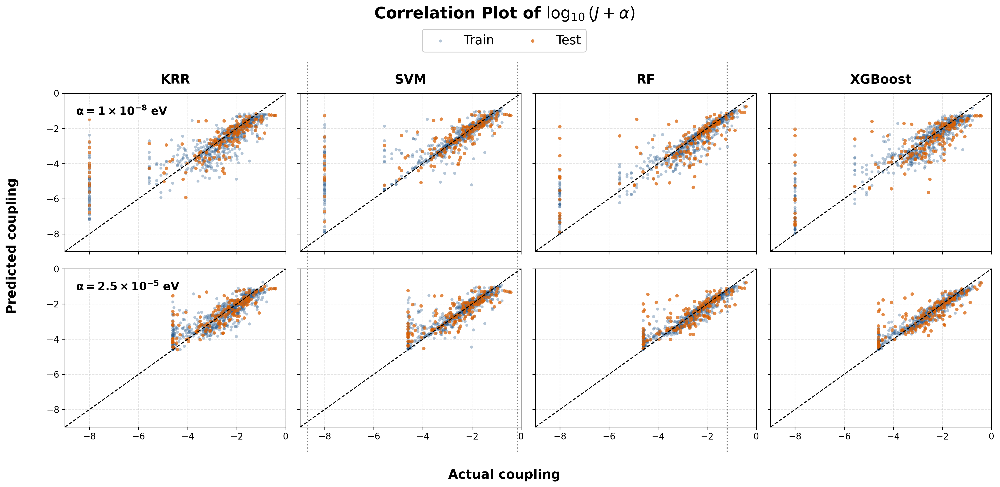

In [12]:
# =====================================================================
# 2x4 parity comparison across two alpha settings (publication style)
# Top row: alpha = 1e-8 eV, Bottom row: alpha = 2.5e-5 eV
# =====================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# User controls
# -----------------------------
axis_start_log = -9.0
axis_end_log = 0.0

# Font and style controls
suptitle_fs = 20
panel_title_fs = 16
axis_label_fs = 16
tick_fs = 11
legend_fs = 16
row_label_fs = 14

train_color = "#2b5c8f"
test_color = "#d95f02"

train_s = 14
test_s = 18

axis_low_log = min(axis_start_log, axis_end_log)
axis_high_log = max(axis_start_log, axis_end_log)

alpha_runs = [
    {
        "label": r"$\mathbf{\alpha = 1 \times 10^{-8}\ eV}$",
        "root": Path("../four-model/full-dataset-with-floor-cap/redo-10-8-cutoff"),
    },
    {
        "label": r"$\mathbf{\alpha = 2.5 \times 10^{-5}\ eV}$",
        "root": Path("../four-model/full-dataset-with-floor-cap/redo-2.5-10-5-cutoff"),
    },
]

model_names = ["KRR", "SVM", "RF", "XGB"]
model_titles = {"KRR": "KRR", "SVM": "SVM", "RF": "RF", "XGB": "XGBoost"}

fig, axes = plt.subplots(2, 4, figsize=(18, 8.5), dpi=300, sharex=True, sharey=True)

for row_idx, run_info in enumerate(alpha_runs):
    pred_dir = run_info["root"] / "model-results-fixed-split" / "prediction-csv-log-linear"

    for col_idx, model_name in enumerate(model_names):
        ax = axes[row_idx, col_idx]

        train_csv = pred_dir / f"{model_name}_train_predictions_log_linear.csv"
        test_csv = pred_dir / f"{model_name}_test_predictions_log_linear.csv"

        # Column titles only on top row
        if row_idx == 0:
            ax.set_title(model_titles[model_name], fontsize=panel_title_fs, fontweight="bold", pad=12)

        if (not train_csv.exists()) or (not test_csv.exists()):
            ax.text(
                0.5, 0.5, f"Missing CSV\n{model_name}",
                ha="center", va="center", transform=ax.transAxes, fontsize=11
            )
            ax.set_xlim(axis_low_log, axis_high_log)
            ax.set_ylim(axis_low_log, axis_high_log)
            ax.grid(True, linestyle="--", alpha=0.35)
            continue

        train_df = pd.read_csv(train_csv)
        test_df = pd.read_csv(test_csv)

        x_train = train_df["actual_log10"].to_numpy(dtype=float)
        y_train_pred = train_df["pred_log10"].to_numpy(dtype=float)
        x_test = test_df["actual_log10"].to_numpy(dtype=float)
        y_test_pred = test_df["pred_log10"].to_numpy(dtype=float)

        # Plot scatter data
        ax.scatter(x_train, y_train_pred, s=train_s, alpha=0.35, color=train_color, edgecolors="none", label="Train")
        ax.scatter(x_test, y_test_pred, s=test_s, alpha=0.72, color=test_color, edgecolors="none", label="Test")
        ax.plot([axis_low_log, axis_high_log], [axis_low_log, axis_high_log], "k--", lw=1.2)

        ax.set_xlim(axis_low_log, axis_high_log)
        ax.set_ylim(axis_low_log, axis_high_log)
        ax.grid(True, linestyle="--", alpha=0.35)
        ax.tick_params(axis="both", labelsize=tick_fs)

        # Add alpha label to top-left of each row (first column)
        if col_idx == 0:
            ax.text(
                0.05, 0.92, run_info["label"],
                transform=ax.transAxes,
                fontsize=row_label_fs,
                va="top", ha="left",
                bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8, "pad": 2}
            )

# Add dotted boundary lines outlining columns
for col_idx in range(len(model_names) - 1):
    # Calculate right edge coordinate of current column in figure space
    pos_left = axes[0, col_idx].get_position()
    pos_right = axes[0, col_idx + 1].get_position()
    mid_x = (pos_left.x1 + pos_right.x0) / 2.0
    
    # Draw vertical line separating columns across whole figure height
    fig.add_artist(
        plt.Line2D(
            [mid_x, mid_x], [0.08, 0.88],
            transform=fig.transFigure,
            color="#808080", linestyle=":", lw=1.5
        )
    )

# Clean legend placement
handles, labels = axes[0, 0].get_legend_handles_labels()
if handles:
    fig.legend(
        handles, labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.955),
        ncol=2,
        frameon=True,
        edgecolor="#bfbfbf",
        fontsize=legend_fs,
    )

# Global Figure Title
fig.suptitle(r"Correlation Plot of $\log_{10}(J + \alpha)$", fontsize=suptitle_fs, fontweight="bold", y=0.99)

# Single Centered X and Y Axis Labels
fig.supxlabel("Actual coupling", fontsize=axis_label_fs, fontweight="bold", y=0.02)
fig.supylabel("Predicted coupling", fontsize=axis_label_fs, fontweight="bold", x=0.02)

fig.tight_layout(rect=[0.03, 0.04, 0.98, 0.92])

out_dir = Path("../four-model/full-dataset-with-floor-cap")
out_dir.mkdir(parents=True, exist_ok=True)
out_png = out_dir / "parity_2x4_alpha_comparison_4.png"
fig.savefig(out_png, dpi=300, bbox_inches="tight")
plt.show()

In [40]:
# # =====================================================================
# # 6a. Publication parity plot in meV:
# # Main panel focuses on high coupling (1e-1 to 1e2 meV),
# # inset shows full coupling range from the same data.
# # =====================================================================

# from pathlib import Path
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# alpha_local = 2.5e-5

# prediction_csv_dir = Path("../four-model/full-dataset-with-floor-cap/model-results-fixed-split/prediction-csv-log-linear")
# plot_dir = Path("../four-model/full-dataset-with-floor-cap/model-results-fixed-split/parity-plots-mev-high-with-inset")
# plot_dir.mkdir(parents=True, exist_ok=True)

# model_names = ["KRR", "SVM", "RF", "XGB"]
# summary_rows = []

# for model_name in model_names:
#     train_csv = prediction_csv_dir / f"{model_name}_train_predictions_log_linear.csv"
#     test_csv = prediction_csv_dir / f"{model_name}_test_predictions_log_linear.csv"

#     if not train_csv.exists() or not test_csv.exists():
#         print(f"Skipping {model_name}: train/test prediction CSV not found.")
#         continue

#     train_df = pd.read_csv(train_csv)
#     test_df = pd.read_csv(test_csv)

#     required_cols = {"actual_log10", "pred_log10"}
#     if not required_cols.issubset(train_df.columns) or not required_cols.issubset(test_df.columns):
#         print(f"Skipping {model_name}: missing actual_log10/pred_log10 columns.")
#         continue

#     # Convert from log10(J+alpha) to physical J in meV.
#     train_actual_meV = np.maximum((10.0 ** train_df["actual_log10"].to_numpy()) - alpha_local, 0.0) * 1000.0
#     train_pred_meV = np.maximum((10.0 ** train_df["pred_log10"].to_numpy()) - alpha_local, 0.0) * 1000.0
#     test_actual_meV = np.maximum((10.0 ** test_df["actual_log10"].to_numpy()) - alpha_local, 0.0) * 1000.0
#     test_pred_meV = np.maximum((10.0 ** test_df["pred_log10"].to_numpy()) - alpha_local, 0.0) * 1000.0

#     # Positive floor for log-axes.
#     min_meV = 1e-3
#     train_actual_meV = np.clip(train_actual_meV, min_meV, None)
#     train_pred_meV = np.clip(train_pred_meV, min_meV, None)
#     test_actual_meV = np.clip(test_actual_meV, min_meV, None)
#     test_pred_meV = np.clip(test_pred_meV, min_meV, None)

#     # Main high-coupling window for manuscript focus.
#     high_low = 1e-1
#     high_high = 1e2

#     fig, ax = plt.subplots(figsize=(7.6, 6.8), dpi=300)

#     ax.scatter(train_actual_meV, train_pred_meV, alpha=0.45, color="#2b5c8f", edgecolors="none", s=22, label="Train")
#     ax.scatter(test_actual_meV, test_pred_meV, alpha=0.80, color="#d95f02", edgecolors="none", s=30, label="Test")

#     # 1:1 guide line for main window.
#     guide = np.array([high_low, high_high])
#     ax.plot(guide, guide, "k--", linewidth=1.4, label="1:1")

#     ax.set_xscale("log")
#     ax.set_yscale("log")
#     ax.set_xlim(high_low, high_high)
#     ax.set_ylim(high_low, high_high)

#     ax.set_xlabel("Actual Coupling (meV)", fontsize=12, fontweight="bold")
#     ax.set_ylabel("Predicted Coupling (meV)", fontsize=12, fontweight="bold")
#     ax.set_title(f"{model_name}: High-Coupling Parity (0.1-100 meV)", fontsize=12.5, fontweight="bold", pad=10)
#     ax.grid(True, which="both", linestyle="--", alpha=0.45)
#     ax.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="#cccccc")

#     # Inset: full-range parity from same dataset (small + large couplings).
#     all_actual = np.concatenate([train_actual_meV, test_actual_meV])
#     all_pred = np.concatenate([train_pred_meV, test_pred_meV])
#     full_min = float(min(all_actual.min(), all_pred.min()))
#     full_max = float(max(all_actual.max(), all_pred.max()))

#     axins = inset_axes(ax, width="42%", height="42%", loc="lower right", borderpad=1.2)
#     axins.scatter(train_actual_meV, train_pred_meV, alpha=0.35, color="#2b5c8f", edgecolors="none", s=9)
#     axins.scatter(test_actual_meV, test_pred_meV, alpha=0.70, color="#d95f02", edgecolors="none", s=12)
#     axins.plot([full_min, full_max], [full_min, full_max], "k--", linewidth=1.0)
#     axins.set_xscale("log")
#     axins.set_yscale("log")
#     axins.set_xlim(full_min, full_max)
#     axins.set_ylim(full_min, full_max)
#     axins.grid(True, which="both", linestyle=":", alpha=0.35)
#     axins.set_title("Full range", fontsize=8)

#     plt.tight_layout()

#     out_png = plot_dir / f"{model_name}_parity_meV_high_main_with_full_inset.png"
#     fig.savefig(out_png, dpi=300, bbox_inches="tight")
#     plt.show()

#     # Count test points inside manuscript focus window.
#     in_window = (
#         (test_actual_meV >= high_low)
#         & (test_actual_meV <= high_high)
#         & (test_pred_meV >= high_low)
#         & (test_pred_meV <= high_high)
#     )

#     summary_rows.append({
#         "Model": model_name,
#         "High_Window_meV": "1e-1 to 1e2",
#         "N_Train": int(len(train_df)),
#         "N_Test": int(len(test_df)),
#         "N_Test_Inside_High_Window": int(in_window.sum()),
#         "Pct_Test_Inside_High_Window": float(100.0 * in_window.sum() / len(test_df)) if len(test_df) else 0.0,
#         "Plot_Path": str(out_png),
#     })

#     print(f"Saved high-focus parity figure: {out_png}")

# if summary_rows:
#     summary_df = pd.DataFrame(summary_rows)
#     summary_csv = plot_dir / "high_focus_parity_plot_summary.csv"
#     summary_df.to_csv(summary_csv, index=False)
#     print("\nSaved summary:")
#     print(summary_csv)
#     display(summary_df)
# else:
#     print("No parity figures were generated. Check prediction CSV paths.")

# log space parity plot

In [13]:
# # =====================================================================
# # True log10-space parity plots for all 4 models
# # =====================================================================
# import matplotlib.pyplot as plt
# from sklearn.metrics import mean_absolute_error, r2_score
# log_parity_output_dir = model_output_dir / "parity-plots-log10-space"
# log_parity_output_dir.mkdir(parents=True, exist_ok=True)

# model_names = ["KRR", "SVM", "RF", "XGB"]
# log_plot_summary_rows = []

# for model_name in model_names:
#     model_path = model_output_dir / "model" / f"{model_name}_fixed_split_model.pkl"
#     if not model_path.exists():
#         print(f"Skipping {model_name}: model file not found at {model_path}")
#         continue

#     loaded_obj = joblib.load(model_path)
#     model = loaded_obj["best_model"] if isinstance(loaded_obj, dict) and "best_model" in loaded_obj else loaded_obj

#     y_pred_train_log = model.predict(X_train)
#     y_pred_test_log = model.predict(X_test)

#     train_mae_log = mean_absolute_error(y_train, y_pred_train_log)
#     test_mae_log = mean_absolute_error(y_test, y_pred_test_log)
#     train_r2_log = r2_score(y_train, y_pred_train_log)
#     test_r2_log = r2_score(y_test, y_pred_test_log)

#     plt.figure(figsize=(7, 6.5), dpi=300)

#     plt.scatter(
#         y_train,
#         y_pred_train_log,
#         alpha=0.6,
#         color="#2b5c8f",
#         label="Train Set",
#         edgecolors="none",
#         s=30,
#     )
#     plt.scatter(
#         y_test,
#         y_pred_test_log,
#         alpha=0.8,
#         color="#d95f02",
#         label="Test Set",
#         edgecolors="none",
#         s=35,
#     )

#     min_val = min(y_train.min(), y_pred_train_log.min(), y_test.min(), y_pred_test_log.min())
#     max_val = max(y_train.max(), y_pred_train_log.max(), y_test.max(), y_pred_test_log.max())
#     plt.plot([min_val, max_val], [min_val, max_val], "k--", linewidth=1.5, label="1:1 Line")

#     plt.xlabel("Actual log10(Coupling_eV + alpha_shift)", fontsize=12, fontweight="bold")
#     plt.ylabel("Predicted log10(Coupling_eV + alpha_shift)", fontsize=12, fontweight="bold")
#     plt.title(f"{model_name} True Log10-Space Parity Plot", fontsize=13, fontweight="bold", pad=10)
#     plt.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="#cccccc")
#     plt.grid(True, linestyle="--", alpha=0.5)
#     plt.tight_layout()

#     parity_plot_path = log_parity_output_dir / f"{model_name}_fixed_split_parity_log10.png"
#     plt.savefig(parity_plot_path, dpi=300)
#     plt.show()

#     print(f"Saved true log10-space parity plot for {model_name}: {parity_plot_path}")

#     log_plot_summary_rows.append({
#         "Model": model_name,
#         "Train_MAE_log10": train_mae_log,
#         "Train_R2_log10": train_r2_log,
#         "Test_MAE_log10": test_mae_log,
#         "Test_R2_log10": test_r2_log,
#         "Parity_Plot_Path": str(parity_plot_path),
#     })

# if log_plot_summary_rows:
#     log_parity_summary_path = log_parity_output_dir / "parity_plot_log10_files.csv"
#     pd.DataFrame(log_plot_summary_rows).to_csv(log_parity_summary_path, index=False)
#     print(f"Saved log10-space parity plot file list: {log_parity_summary_path}")

# To see if the predicted coupling are less than alpha or not?

In [41]:
# # =====================================================================
# # Floor diagnostics + publication-ready RF parity plot near alpha floor
# # =====================================================================

# from pathlib import Path
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt

# alpha_local = 2.5e-5
# log_alpha = float(np.log10(alpha_local))

# prediction_csv_dir = Path("../four-model/full-dataset-with-floor-cap/model-results-fixed-split/prediction-csv-log-linear")
# qc_out_dir = Path("../four-model/full-dataset-with-floor-cap/model-results-fixed-split/floor-diagnostics")
# qc_out_dir.mkdir(parents=True, exist_ok=True)

# model_names = ["KRR", "SVM", "RF", "XGB"]
# qc_rows = []

# for model_name in model_names:
#     test_csv = prediction_csv_dir / f"{model_name}_test_predictions_log_linear.csv"
#     if not test_csv.exists():
#         print(f"Skipping {model_name}: file not found at {test_csv}")
#         continue

#     df = pd.read_csv(test_csv)

#     required_cols = {"actual_log10", "pred_log10"}
#     missing_cols = required_cols - set(df.columns)
#     if missing_cols:
#         print(f"Skipping {model_name}: missing columns {sorted(missing_cols)}")
#         continue

#     # Reconstruct physical coupling consistently: J = max(10^log10(J+alpha) - alpha, 0)
#     df["actual_eV_corrected"] = np.maximum((10.0 ** df["actual_log10"].to_numpy()) - alpha_local, 0.0)
#     df["pred_eV_corrected"] = np.maximum((10.0 ** df["pred_log10"].to_numpy()) - alpha_local, 0.0)
#     df["actual_meV_corrected"] = df["actual_eV_corrected"] * 1000.0
#     df["pred_meV_corrected"] = df["pred_eV_corrected"] * 1000.0

#     floor_mask = df["actual_log10"] <= (log_alpha + 1e-6)
#     n_floor = int(floor_mask.sum())
#     n_total = int(len(df))

#     if n_floor > 0:
#         floor_pred = df.loc[floor_mask, "pred_log10"]
#         n_over_03 = int((floor_pred > (log_alpha + 0.3)).sum())
#         n_over_10 = int((floor_pred > (log_alpha + 1.0)).sum())
#         floor_mae = float(np.mean(np.abs(df.loc[floor_mask, "pred_log10"] - df.loc[floor_mask, "actual_log10"])))
#         floor_median_pred = float(floor_pred.median())
#     else:
#         n_over_03 = 0
#         n_over_10 = 0
#         floor_mae = np.nan
#         floor_median_pred = np.nan

#     qc_rows.append({
#         "Model": model_name,
#         "Alpha_eV": alpha_local,
#         "Log10_Alpha": log_alpha,
#         "N_Test": n_total,
#         "N_Actual_At_Floor": n_floor,
#         "Pct_Actual_At_Floor": (100.0 * n_floor / n_total) if n_total else 0.0,
#         "N_FloorPred_Above_logAlpha_plus_0p3": n_over_03,
#         "N_FloorPred_Above_logAlpha_plus_1p0": n_over_10,
#         "Floor_MAE_log10": floor_mae,
#         "Floor_Median_Pred_log10": floor_median_pred,
#     })

#     corrected_csv = qc_out_dir / f"{model_name}_test_predictions_with_corrected_linear_columns.csv"
#     df.to_csv(corrected_csv, index=False)
#     print(f"Saved corrected CSV for {model_name}: {corrected_csv}")

# qc_df = pd.DataFrame(qc_rows)
# qc_csv = qc_out_dir / "floor_diagnostics_summary.csv"
# qc_df.to_csv(qc_csv, index=False)
# print(f"\nSaved floor diagnostics summary: {qc_csv}")
# print(qc_df.to_string(index=False))

# # Publication-ready RF figure with zoom around floor region
# rf_csv = qc_out_dir / "RF_test_predictions_with_corrected_linear_columns.csv"
# if rf_csv.exists():
#     rf_df = pd.read_csv(rf_csv)

#     fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.5), dpi=300)

#     # Panel A: full range parity in log10 space
#     axes[0].scatter(rf_df["actual_log10"], rf_df["pred_log10"], s=34, alpha=0.78, color="#2b5c8f", edgecolors="none")
#     lo = float(min(rf_df["actual_log10"].min(), rf_df["pred_log10"].min()))
#     hi = float(max(rf_df["actual_log10"].max(), rf_df["pred_log10"].max()))
#     axes[0].plot([lo, hi], [lo, hi], "k--", lw=1.4, label="1:1")
#     axes[0].axvline(log_alpha, color="#1f7a1f", ls=":", lw=1.2, label="log10(alpha)")
#     axes[0].axhline(log_alpha, color="#1f7a1f", ls=":", lw=1.2)
#     axes[0].set_xlabel("Actual log10(J + alpha)", fontweight="bold")
#     axes[0].set_ylabel("Predicted log10(J + alpha)", fontweight="bold")
#     axes[0].set_title("RF parity (full range)", fontweight="bold")
#     axes[0].legend(loc="upper left", frameon=True, fontsize=9)
#     axes[0].grid(True, ls="--", alpha=0.45)

#     # Panel B: zoomed floor region to show spread near censoring boundary
#     floor_band = rf_df[rf_df["actual_log10"] <= (log_alpha + 0.02)].copy()
#     axes[1].scatter(floor_band["actual_log10"], floor_band["pred_log10"], s=42, alpha=0.9, color="#d95f02", edgecolors="none")
#     axes[1].axvline(log_alpha, color="#1f7a1f", ls=":", lw=1.2)
#     axes[1].axhline(log_alpha, color="#1f7a1f", ls=":", lw=1.2)
#     axes[1].set_xlim(log_alpha - 0.08, log_alpha + 0.08)
#     if len(floor_band) > 0:
#         y_low = float(min(log_alpha - 0.1, floor_band["pred_log10"].min() - 0.1))
#         y_high = float(max(log_alpha + 1.4, floor_band["pred_log10"].max() + 0.1))
#     else:
#         y_low = log_alpha - 0.1
#         y_high = log_alpha + 1.4
#     axes[1].set_ylim(y_low, y_high)
#     axes[1].set_xlabel("Actual log10(J + alpha)", fontweight="bold")
#     axes[1].set_ylabel("Predicted log10(J + alpha)", fontweight="bold")
#     axes[1].set_title("RF floor-region zoom", fontweight="bold")
#     axes[1].grid(True, ls="--", alpha=0.45)

#     floor_n = int((rf_df["actual_log10"] <= (log_alpha + 1e-6)).sum())
#     floor_over = int(((rf_df["actual_log10"] <= (log_alpha + 1e-6)) & (rf_df["pred_log10"] > (log_alpha + 0.3))).sum())
#     fig.suptitle(
#         f"RF floor diagnostic (alpha={alpha_local:.2e} eV): floor points={floor_n}, above floor+0.3={floor_over}",
#         fontsize=11.5,
#         fontweight="bold",
#         y=1.02,
#     )
#     fig.tight_layout()

#     rf_plot_path = qc_out_dir / "RF_parity_log10_with_floor_zoom.png"
#     fig.savefig(rf_plot_path, dpi=300, bbox_inches="tight")
#     plt.show()

#     print(f"Saved publication-style RF diagnostic plot: {rf_plot_path}")
# else:
#     print("RF corrected CSV not found; skipping RF floor-zoom figure.")

## 6b. Calibrate RF to reduce floor-region overprediction
Use isotonic calibration on the RF train parity data, then apply it to RF test predictions. This keeps rank order while shrinking systematic high bias near the alpha floor.

## 7. Predict Couplings for All 20,000 MD Planar Dimer Frames
Use the retrained KRR model to predict couplings for the full MD Planar trajectory and save all outputs in the `/four-model/MD-traj-result` folder.


===== Running MD prediction for KRR =====


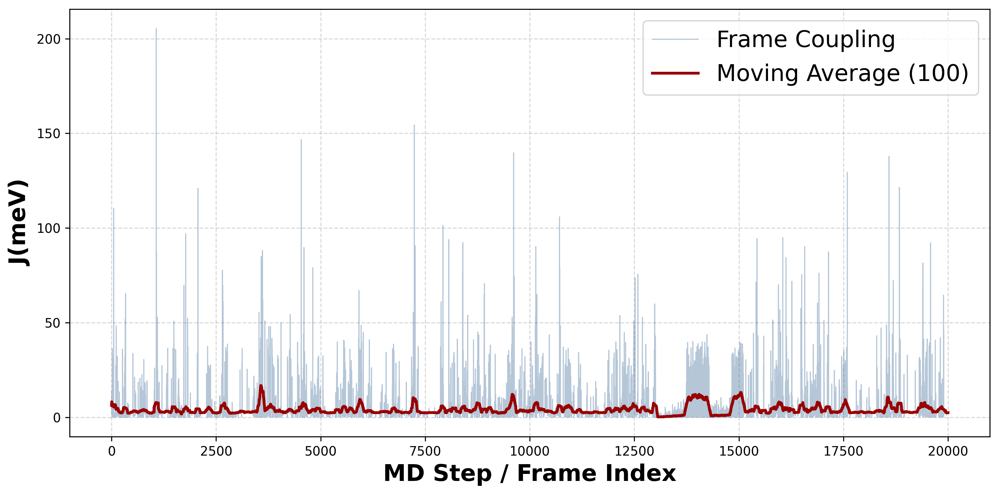

Saved full prediction CSV: ../four-model/MD-traj-result/planar_tanfunction_features/KRR_P1_planar_predicted_couplings.csv
Saved yes/no CSV:          ../four-model/MD-traj-result/planar_tanfunction_features/KRR_P1_planar_predicted_couplings_yesno.csv
Saved trajectory plot:     ../four-model/MD-traj-result/planar_tanfunction_features/KRR_P1_planar_coupling_vs_step-100.png
Significant frames: 19125/20002 (95.62%)

===== Running MD prediction for SVM =====


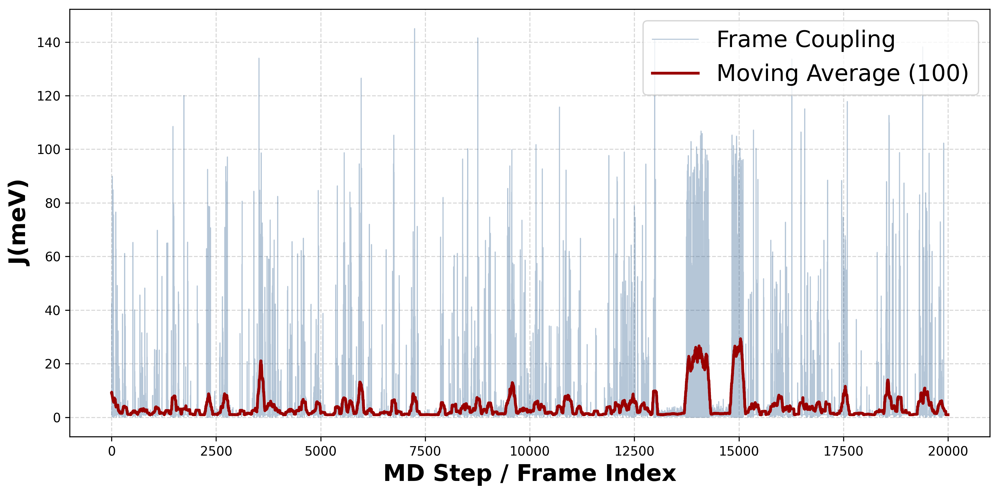

Saved full prediction CSV: ../four-model/MD-traj-result/planar_tanfunction_features/SVM_P1_planar_predicted_couplings.csv
Saved yes/no CSV:          ../four-model/MD-traj-result/planar_tanfunction_features/SVM_P1_planar_predicted_couplings_yesno.csv
Saved trajectory plot:     ../four-model/MD-traj-result/planar_tanfunction_features/SVM_P1_planar_coupling_vs_step-100.png
Significant frames: 19637/20002 (98.18%)

===== Running MD prediction for RF =====


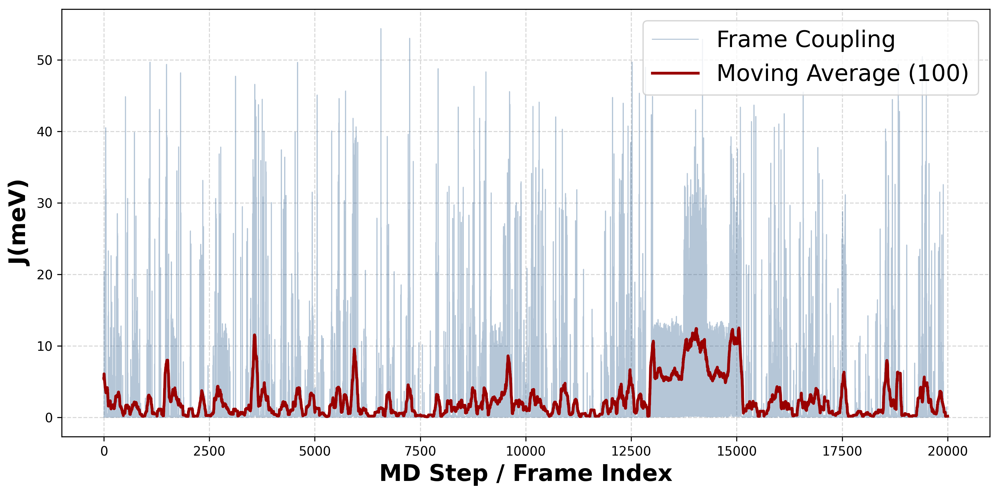

Saved full prediction CSV: ../four-model/MD-traj-result/planar_tanfunction_features/RF_P1_planar_predicted_couplings.csv
Saved yes/no CSV:          ../four-model/MD-traj-result/planar_tanfunction_features/RF_P1_planar_predicted_couplings_yesno.csv
Saved trajectory plot:     ../four-model/MD-traj-result/planar_tanfunction_features/RF_P1_planar_coupling_vs_step-100.png
Significant frames: 15672/20002 (78.35%)

===== Running MD prediction for XGB =====


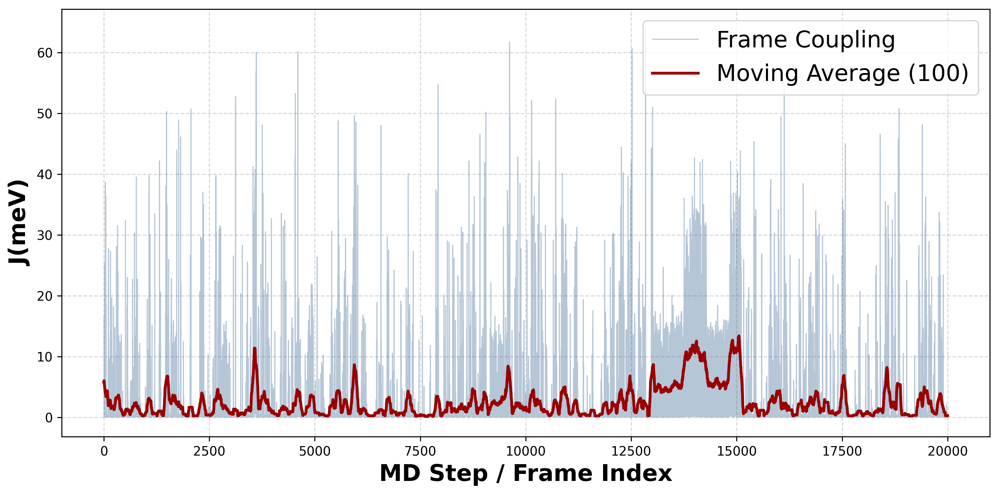

Saved full prediction CSV: ../four-model/MD-traj-result/planar_tanfunction_features/XGB_P1_planar_predicted_couplings.csv
Saved yes/no CSV:          ../four-model/MD-traj-result/planar_tanfunction_features/XGB_P1_planar_predicted_couplings_yesno.csv
Saved trajectory plot:     ../four-model/MD-traj-result/planar_tanfunction_features/XGB_P1_planar_coupling_vs_step-100.png
Significant frames: 17417/20002 (87.08%)

Saved overall MD prediction summary to: ../four-model/MD-traj-result/planar_tanfunction_features/ALL_MODELS_MD_prediction_summary.csv


In [3]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =====================================================================
# 7. Predict couplings for planar + distorted MD trajectories (4 models)
# =====================================================================

model_names = ["KRR", "SVM", "RF", "XGB"]
model_dir = "../four-model/full-dataset-with-floor-cap/redo-2.5-10-5-cutoff/model-results-fixed-split/model"

feature_sources = {
    "planar": "../Results/Bradly_MD_data/P1_planar_full_features.csv"
    #"distorted": "../Results/Bradly_MD_data/P1_dimer_full_features.csv",
}

md_output_dir = "../four-model/MD-traj-result/planar_tanfunction_features"
os.makedirs(md_output_dir, exist_ok=True)

# Fallbacks used only if older PKLs do not store metadata.
default_features = [
    "Min_HeavyDist_Ang",
    "cos_theta",
    "cos_4phi",
    "cos_4psi",
    "FeFe_Dist_Ang",

]
default_alpha_shift = 2.5e-5 # Coupling_eV + alpha_shift is the target for log10 regression, so alpha_shift must be in eV units.
significant_threshold_meV = 0.1
summary_rows = []

for model_name in model_names:
    pkl_path = os.path.join(model_dir, f"{model_name}_fixed_split_model.pkl")
    if not os.path.exists(pkl_path):
        print(f"Skipping {model_name}: model file not found at {pkl_path}")
        continue

    loaded_obj = joblib.load(pkl_path)

    if isinstance(loaded_obj, dict):
        model = loaded_obj.get("best_model", loaded_obj)
        model_features = loaded_obj.get("features", globals().get("features", default_features))
        model_alpha = float(loaded_obj.get("alpha_shift", globals().get("alpha_shift", default_alpha_shift)))
    else:
        model = loaded_obj
        model_features = globals().get("features", default_features)
        model_alpha = float(globals().get("alpha_shift", default_alpha_shift))

    print(f"\n===== Running MD prediction for {model_name} =====")

    for geometry_name, test_feature_path in feature_sources.items():
        if not os.path.exists(test_feature_path):
            print(f"Skipping {model_name}-{geometry_name}: feature file not found at {test_feature_path}")
            continue

        df_md = pd.read_csv(test_feature_path)

        if "Step" in df_md.columns:
            df_md["Frame_Index"] = pd.to_numeric(df_md["Step"], errors="coerce")
        elif "Filename" in df_md.columns and df_md["Filename"].astype(str).str.contains(r"\d+").any():
            df_md["Frame_Index"] = pd.to_numeric(
                df_md["Filename"].astype(str).str.extract(r"(\d+)")[0],
                errors="coerce",
            )
        else:
            df_md["Frame_Index"] = np.arange(len(df_md))

        df_md["Frame_Index"] = df_md["Frame_Index"].ffill().bfill().astype(int)
        df_md = df_md.sort_values("Frame_Index").reset_index(drop=True)

        missing_cols = [c for c in model_features if c not in df_md.columns]
        if missing_cols:
            raise ValueError(f"Missing required feature columns for {model_name}-{geometry_name}: {missing_cols}")

        before_drop = len(df_md)
        df_md = df_md.dropna(subset=model_features).copy()
        dropped = before_drop - len(df_md)
        if dropped > 0:
            print(f"{model_name}-{geometry_name}: dropped {dropped} rows with missing features")

        X_new = df_md[model_features].values
        pred_log10 = model.predict(X_new)
#this is the original code that was commented out, but it seems to be the correct way to compute the predicted coupling in eV and meV
        # pred_eV = np.maximum((10.0 ** pred_log10) - model_alpha, 0.0)
        # pred_meV = pred_eV * 1000.0
#I want to use unsubtracted values for the predicted coupling in eV and meV, so I will use the following lines instead
        pred_eV = 10.0 ** pred_log10
        pred_meV = pred_eV * 1000.0
        df_md["pred_log10_coupling"] = pred_log10
        df_md["pred_coupling_eV"] = pred_eV
        df_md["pred_coupling_meV"] = pred_meV
        df_md["significant_coupling_threshold_meV"] = significant_threshold_meV
        df_md["significant_coupling_yesno"] = np.where(
            df_md["pred_coupling_meV"] >= significant_threshold_meV,
            "Yes",
            "No",
        )

        output_csv_path = os.path.join(md_output_dir, f"{model_name}_P1_{geometry_name}_predicted_couplings.csv")
        output_yesno_csv_path = os.path.join(md_output_dir, f"{model_name}_P1_{geometry_name}_predicted_couplings_yesno.csv")
        output_plot_path = os.path.join(md_output_dir, f"{model_name}_P1_{geometry_name}_coupling_vs_step-100.png")

        df_md.to_csv(output_csv_path, index=False)

        yesno_columns = [
            c
            for c in ["Filename", "Step", "Frame_Index", "pred_coupling_meV", "significant_coupling_yesno"]
            if c in df_md.columns
        ]
        df_md[yesno_columns].to_csv(output_yesno_csv_path, index=False)

        plt.figure(figsize=(11, 5.5), dpi=300)
        plt.plot(
            df_md["Frame_Index"],
            df_md["pred_coupling_meV"],
            alpha=0.35,
            color="#2b5c8f",
            linewidth=0.8,
            label="Frame Coupling",
            #label="Frame Coupling (meV)",
        )

        window_size = 100
        rolling_mean = df_md["pred_coupling_meV"].rolling(window=window_size, center=True, min_periods=1).mean()
        plt.plot(
            df_md["Frame_Index"],
            rolling_mean,
            color="#990000",
            linewidth=2.2,
            label=f"Moving Average ({window_size})",
            #label=f"{window_size}-Frame Moving Avg",
        )
# remove singnificant coupling from figure
        # plt.axhline(
        #     y=significant_threshold_meV,
        #     color="#1f7a1f",
        #     linestyle="--",
        #     linewidth=1.3,
        #     label=f"Significant Threshold ({significant_threshold_meV:g} meV)",
        # )

        plt.xlabel("MD Step / Frame Index", fontsize=18, fontweight="bold")
        plt.ylabel("J(meV)", fontsize=18, fontweight="bold")
        # plt.title(
        #     f"{model_name} Predicted Coupling: {geometry_name.capitalize()} Trajectory",
        #     fontsize=14,
        #     fontweight="bold",
        #     pad=12,
        # )
        plt.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="#cccccc", fontsize=18)
        plt.grid(True, linestyle="--", alpha=0.5)
        plt.tight_layout()
        plt.savefig(output_plot_path, dpi=300)
        plt.show()

        n_total = len(df_md)
        n_sig = int((df_md["significant_coupling_yesno"] == "Yes").sum())
        pct_sig = (100.0 * n_sig / n_total) if n_total > 0 else 0.0

        summary_rows.append(
            {
                "Model": model_name,
                "Geometry": geometry_name,
                "N_Frames": n_total,
                "N_Significant": n_sig,
                "Pct_Significant": pct_sig,
                "Mean_meV": float(df_md["pred_coupling_meV"].mean()),
                "Median_meV": float(df_md["pred_coupling_meV"].median()),
                "P95_meV": float(df_md["pred_coupling_meV"].quantile(0.95)),
                "Max_meV": float(df_md["pred_coupling_meV"].max()),
                "Full_CSV": output_csv_path,
                "YesNo_CSV": output_yesno_csv_path,
                "Plot": output_plot_path,
            }
        )

        print(f"Saved full prediction CSV: {output_csv_path}")
        print(f"Saved yes/no CSV:          {output_yesno_csv_path}")
        print(f"Saved trajectory plot:     {output_plot_path}")
        print(f"Significant frames: {n_sig}/{n_total} ({pct_sig:.2f}%)")

if summary_rows:
    summary_df = pd.DataFrame(summary_rows)
    summary_csv_path = os.path.join(md_output_dir, "ALL_MODELS_MD_prediction_summary.csv")
    summary_df.to_csv(summary_csv_path, index=False)
    print(f"\nSaved overall MD prediction summary to: {summary_csv_path}")
    summary_df
else:
    print("No predictions were generated. Check model and feature file paths.")


In [3]:
#To extract only trajctories and RF pred_coupling_meV columns from "/four-model/MD-traj-result/planar_tanfunction_features/XGB_P1_planar_predicted_couplings.csv"
import pandas as pd

df = pd.read_csv("../four-model/MD-traj-result/planar_tanfunction_features/RF_P1_planar_predicted_couplings.csv")
filtered_df = df[["name", "pred_coupling_meV"]]
filtered_df.to_csv("../four-model/MD-traj-result/planar_tanfunction_features/RF_P1_planar_predicted_couplings_time_coup_series.csv", index=False)

# Replot Planar and Distorted with Shared Y-Range
Load both saved prediction CSV files, compute one common y-range from both datasets, and save comparable plots.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =====================================================================
# 8. Shared Y-range plots: planar vs distorted MD geometry for each model
# =====================================================================

model_names = ["KRR", "SVM", "RF", "XGB"]
# Use existing variable from previous cells if available; otherwise use default output folder.
md_output_dir = globals().get("md_output_dir", "../four-model/MD-traj-result/planar_tanfunction_features")
shared_plot_dir = os.path.join(md_output_dir, "shared-y-range-plots")
os.makedirs(shared_plot_dir, exist_ok=True)

window_size = 100

for model_name in model_names:
    planar_csv = os.path.join(md_output_dir, f"{model_name}_P1_planar_predicted_couplings.csv")
    distorted_csv = os.path.join(md_output_dir, f"{model_name}_P1_distorted_predicted_couplings.csv")

    if not os.path.exists(planar_csv) or not os.path.exists(distorted_csv):
        print(f"Skipping {model_name}: missing planar/distorted CSV in {md_output_dir}")
        continue

    df_planar = pd.read_csv(planar_csv)
    df_distorted = pd.read_csv(distorted_csv)

    required_col = "pred_coupling_meV"
    if required_col not in df_planar.columns or required_col not in df_distorted.columns:
        print(f"Skipping {model_name}: '{required_col}' not found in one or both CSVs")
        continue

    # Ensure a frame index exists.
    for df in (df_planar, df_distorted):
        if "Frame_Index" not in df.columns:
            if "Step" in df.columns:
                df["Frame_Index"] = pd.to_numeric(df["Step"], errors="coerce")
            elif "Filename" in df.columns and df["Filename"].astype(str).str.contains(r"\d+").any():
                df["Frame_Index"] = pd.to_numeric(
                    df["Filename"].astype(str).str.extract(r"(\d+)")[0],
                    errors="coerce",
                )
            else:
                df["Frame_Index"] = np.arange(len(df))

        df["Frame_Index"] = df["Frame_Index"].ffill().bfill().astype(int)
        df.sort_values("Frame_Index", inplace=True)

    # Shared Y-range computed from both geometries together.
    y_all = pd.concat([df_planar[required_col], df_distorted[required_col]], ignore_index=True)
    y_min = float(y_all.min())
    y_max = float(y_all.max())
    if y_min == y_max:
        pad = max(1e-6, abs(y_min) * 0.05)
    else:
        pad = 0.05 * (y_max - y_min)
    y_low = y_min - pad
    y_high = y_max + pad

    fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), dpi=300, sharey=True)

    plot_specs = [
        (axes[0], df_planar, "Planar", "#2b5c8f"),
        (axes[1], df_distorted, "Distorted", "#d95f02"),
    ]

    for ax, df, label, color in plot_specs:
        y = df[required_col]
        rolling_mean = y.rolling(window=window_size, center=True, min_periods=1).mean()

        ax.plot(df["Frame_Index"], y, color=color, alpha=0.28, linewidth=0.9, label=f"{label} frame values")
        ax.plot(df["Frame_Index"], rolling_mean, color=color, linewidth=2.0, label=f"{label} {window_size}-frame avg")
        ax.set_title(f"{label} geometry", fontsize=12, fontweight="bold")
        ax.set_xlabel("MD Step / Frame Index", fontsize=11, fontweight="bold")
        ax.grid(True, linestyle="--", alpha=0.45)
        ax.legend(loc="upper right", fontsize=8, frameon=True, facecolor="white", edgecolor="#cccccc")

    axes[0].set_ylabel("Predicted Electronic Coupling (meV)", fontsize=11, fontweight="bold")
    axes[0].set_ylim(y_low, y_high)

    fig.suptitle(
        f"{model_name}: Planar vs Distorted MD Coupling (Shared Y-range)",
        fontsize=13,
        fontweight="bold",
        y=1.02,
    )
    fig.tight_layout()

    out_png = os.path.join(shared_plot_dir, f"{model_name}_planar_vs_distorted_shared_y.png")
    fig.savefig(out_png, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Saved shared Y-range comparison plot: {out_png}")

Skipping KRR: missing planar/distorted CSV in ../four-model/MD-traj-result/planar_tanfunction_features
Skipping SVM: missing planar/distorted CSV in ../four-model/MD-traj-result/planar_tanfunction_features
Skipping RF: missing planar/distorted CSV in ../four-model/MD-traj-result/planar_tanfunction_features
Skipping XGB: missing planar/distorted CSV in ../four-model/MD-traj-result/planar_tanfunction_features


# Just select 20 dimers having the coupling_predicted_meV that covers all ranges of coupling 

In [ ]:
# # Select 20 planar dimers for validation: 2 dimers from each tenth of the 20,002 frames
import os
import numpy as np
import pandas as pd

planar_pred_csv = "../four-model/MD-traj-result/planar_tanfunction_features/RF_P1_planar_predicted_couplings.csv"
output_dir = "../four-model/MD-traj-result/planar_tanfunction_features/validation_selection"
os.makedirs(output_dir, exist_ok=True)

name_col = "name"
coupling_col = "pred_coupling_meV"
n_bins = 10
n_per_bin = 2
random_state = 42

df = pd.read_csv(planar_pred_csv)
if name_col not in df.columns or coupling_col not in df.columns:
    raise ValueError(f"Expected columns '{name_col}' and '{coupling_col}' in {planar_pred_csv}")

# Order by Frame_Index so each bin covers a contiguous tenth of the trajectory.
sort_col = "Frame_Index" if "Frame_Index" in df.columns else None
df_ordered = df.sort_values(sort_col).reset_index(drop=True) if sort_col else df.reset_index(drop=True)

rng = np.random.default_rng(random_state)
bin_edges = np.array_split(np.arange(len(df_ordered)), n_bins)

selected_rows = []
for bin_id, bin_indices in enumerate(bin_edges, start=1):
    n_pick = min(n_per_bin, len(bin_indices))
    picked_idx = rng.choice(bin_indices, size=n_pick, replace=False)
    picked_idx.sort()
    for idx in picked_idx:
        row = df_ordered.iloc[idx]
        selected_rows.append({
            "Bin": bin_id,
            "Row_Index": int(idx),
            "Frame_Index": int(row["Frame_Index"]) if "Frame_Index" in df_ordered.columns else int(idx),
            "Filename": row[name_col],
            "pred_coupling_meV": float(row[coupling_col]),
        })

validation_selection = pd.DataFrame(selected_rows)
output_csv = os.path.join(output_dir, "planar_tanfunction_validation_20_selection.csv")
validation_selection.to_csv(output_csv, index=False)

print(f"Selected {len(validation_selection)} dimers ({n_per_bin} from each of {n_bins} tenths)")
print(f"Total frames in source CSV: {len(df_ordered):,}")
display(validation_selection)
print(f"Saved selection to: {output_csv}")

# Select 20 planar dimers for validation: 2 dimers from each tenth of the coupling magnitude distribution
import os
import numpy as np
import pandas as pd

planar_pred_csv = "../four-model/MD-traj-result/planar_tanfunction_features/RF_P1_planar_predicted_couplings.csv"
output_dir = "../four-model/MD-traj-result/planar_tanfunction_features/validation_selection"
os.makedirs(output_dir, exist_ok=True)

name_col = "name"
coupling_col = "pred_coupling_meV"
n_bins = 10
n_per_bin = 2
random_state = 42

df = pd.read_csv(planar_pred_csv)
if name_col not in df.columns or coupling_col not in df.columns:
    raise ValueError(f"Expected columns '{name_col}' and '{coupling_col}' in {planar_pred_csv}")

# Order by predicted coupling in increasing (ascending) order
df_ordered = df.sort_values(coupling_col, ascending=True).reset_index(drop=True)

rng = np.random.default_rng(random_state)
bin_edges = np.array_split(np.arange(len(df_ordered)), n_bins)

selected_rows = []
for bin_id, bin_indices in enumerate(bin_edges, start=1):
    n_pick = min(n_per_bin, len(bin_indices))
    picked_idx = rng.choice(bin_indices, size=n_pick, replace=False)
    picked_idx.sort()
    for idx in picked_idx:
        row = df_ordered.iloc[idx]
        selected_rows.append({
            "Bin": bin_id,
            "Row_Index": int(idx),
            "Frame_Index": int(row["Frame_Index"]) if "Frame_Index" in df_ordered.columns else int(idx),
            "Filename": row[name_col],
            "pred_coupling_meV": float(row[coupling_col]),
        })

validation_selection = pd.DataFrame(selected_rows)
output_csv = os.path.join(output_dir, "planar_tanfunction_validation_20_increasing_coupling-bins.csv")
validation_selection.to_csv(output_csv, index=False)

print(f"Selected {len(validation_selection)} dimers ({n_per_bin} from each of {n_bins} coupling bins)")
print(f"Total frames in source CSV: {len(df_ordered):,}")
display(validation_selection)
print(f"Saved selection to: {output_csv}")

Selected 20 dimers (2 from each of 10 coupling bins)
Total frames in source CSV: 20,002


,Bin,Row_Index,Frame_Index,Filename,pred_coupling_meV
0,1,178,6662,geom_06662_planar,0.031496
1,1,1548,19978,geom_19978_planar,0.056267
2,2,2867,6259,geom_06259_planar,0.085596
3,2,2878,8007,geom_08007_planar,0.085762
4,3,4173,1841,geom_01841_planar,0.098393
5,3,5396,17047,geom_17047_planar,0.110565
6,4,6190,10553,geom_10553_planar,0.119999
7,4,7054,5475,geom_05475_planar,0.129447
8,5,9472,8998,geom_08998_planar,0.161152
9,5,9524,633,geom_00633_planar,0.162543


Saved selection to: ../four-model/MD-traj-result/planar_tanfunction_features/validation_selection/planar_tanfunction_validation_20_increasing_coupling-bins.csv


# Correlation plot of predicted and actual coupling 

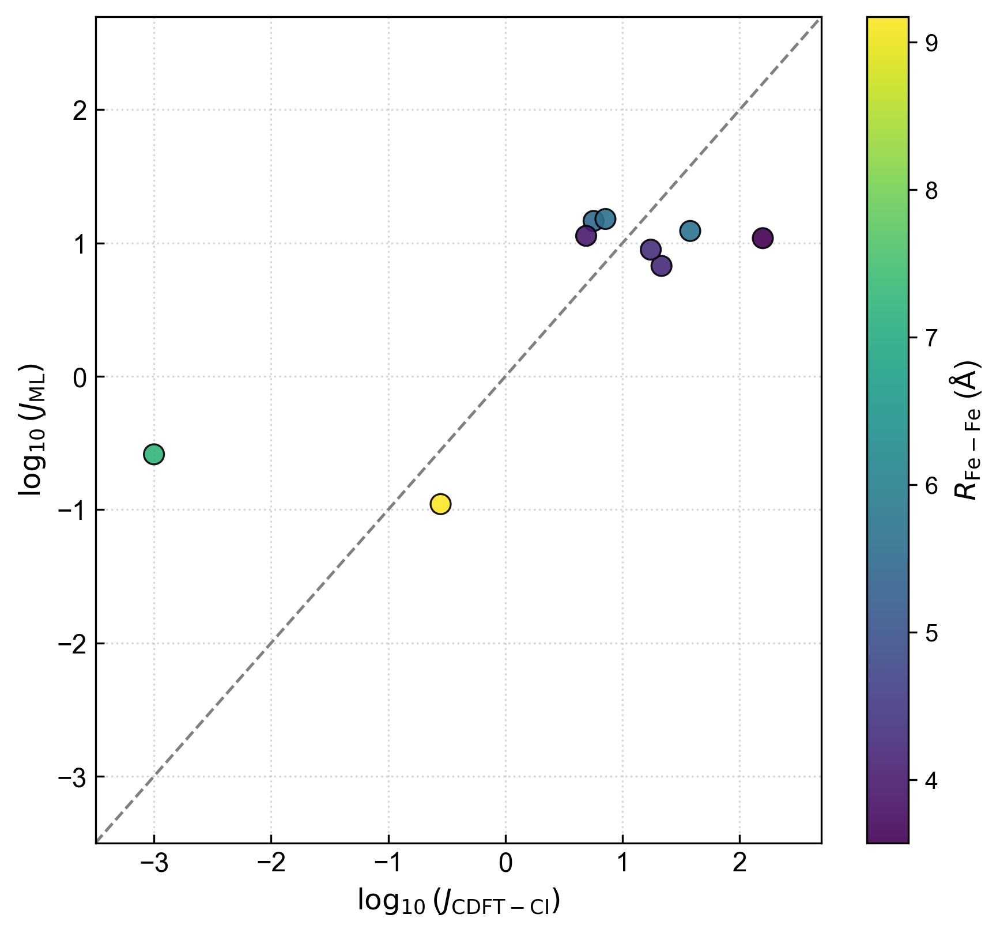

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import pearsonr
from sklearn.metrics import mean_absolute_error, mean_squared_error

# # 1. Parse Data from Table
# data = {
#     "Bin": ["2", "2", "3", "4", "5", "6", "9*", "9*", "10*", "10*"],
#     "J_ML": [10.87, 6.73, 14.63, 0.26, 0.11, 15.14, 8.91, 10.52, 11.31, 12.31],
#     "J_CDFT": [157.46, 21.50, 5.66, 0.00, 0.28, 7.14, 17.41, 3.31, 4.89, 37.79],
#     #"R_FeFe": [3.57, 4.24, 5.47, 7.23, 9.17, 5.61, 4.32, 3.09, 3.97, 5.70],
# }

# df = pd.DataFrame(data)

# # Extract predicted (x) and actual (y) values
# x = df["J_ML"].values
# y = df["J_CDFT"].values

# # Calculate Metrics
# # mae = mean_absolute_error(y, x)
# # rmse = np.sqrt(mean_squared_error(y, x))
# # r_val, _ = pearsonr(x, y)
# # r2 = r_val**2

# # 2. Plotting Setup
# plt.figure(figsize=(6, 5.5), dpi=300)
# ax = plt.gca()

# # Set publication-style aesthetics
# plt.rcParams["font.sans-serif"] = "Arial"
# plt.rcParams["font.family"] = "sans-serif"

# # Scatter plot of ML vs CDFT
# scatter = plt.scatter(
#     x,
#     y,
#     c=df["R_FeFe"],
#     cmap="viridis",
#     s=70,
#     edgecolor="k",
#     linewidth=0.8,
#     zorder=3,
#     alpha=0.9,
# )

# # Colorbar showing Fe-Fe distance
# cbar = plt.colorbar(scatter)
# cbar.set_label(r"$R_{\mathrm{Fe-Fe}}$ ($\mathrm{\AA}$)", fontsize=12)

# # Parity line (1:1 line)
# max_val = max(max(x), max(y)) * 1.2
# min_val = min(min(x), min(y))
# plt.plot(
#     [0, max_val],
#     [0, max_val],
#     color="gray",
#     linestyle="--",
#     linewidth=1.2,
#     label="1:1 Ideal",
#     zorder=2,
# )

# # Axis labels and limits
# plt.xlabel(r"$J_{\mathrm{ML}}$ (meV)", fontsize=12)
# plt.ylabel(r"$J_{\mathrm{CDFT-CI}}$ (meV)", fontsize=12)
# plt.xlim(0, 20)  # ML values range from ~0 to 16
# plt.ylim(-5, 170)  # CDFT values range up to ~157

# Statistical Annotation Box
# text_str = f"$R^2 = {r2:.2f}$\n$\mathrm{{MAE}} = {mae:.2f}\ \mathrm{{meV}}$\n$\mathrm{{RMSE}} = {rmse:.2f}\ \mathrm{{meV}}$"
# plt.gca().text(
#     0.05,
#     0.92,
#     text_str,
#     transform=ax.transAxes,
#     fontsize=10,
#     verticalalignment="top",
#     bbox=dict(
#         boxstyle="round,pad=0.5", facecolor="white", alpha=0.8, edgecolor="gray"
#     ),
# )

# Tick formatting
# plt.tick_params(axis="both", which="major", labelsize=11, direction="in")
# plt.grid(True, linestyle=":", alpha=0.5, zorder=1)

# plt.tight_layout()
# plt.savefig("../four-model/MD-traj-result/planar_tanfunction_features/validation_selection/coupling_correlation.png", dpi=300)
# plt.show()
# import matplotlib.pyplot as plt
# import numpy as np
# import pandas as pd
# from scipy.stats import pearsonr
# from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Parse Data from Table
# data = {
#     "Bin": ["2", "3", "4", "5", "6", "9*", "10*", "10*"],
#     "J_ML": [ 6.73, 14.63, 0.26, 0.11, 15.14, 8.91, 11.31, 12.31],
#     "J_CDFT": [ 21.50, 5.66, 0.00, 0.28, 7.14, 17.41, 4.89, 37.79],
#     "R_FeFe": [ 4.24, 5.47, 7.23, 9.17, 5.61, 4.32, 3.97, 5.70],
# }
data = {
    "Bin": ["2", "2", "3", "4", "5", "6", "9*", "9*", "10*", "10*"],
    "J_ML": [10.87, 6.73, 14.63, 0.26, 0.11, 15.14, 8.91, 10.52, 11.31, 12.31],
    "J_CDFT": [157.46, 21.50, 5.66, 0.00, 0.28, 7.14, 17.41, 3.31, 4.89, 37.79],
    "R_FeFe": [3.57, 4.24, 5.47, 7.23, 9.17, 5.61, 4.32, 3.09, 3.97, 5.70],
}
df = pd.DataFrame(data)

# Add epsilon threshold to handle log10(0) for CDFT-CI
epsilon = 1e-3

# Set Reference CDFT-CI on X-axis and ML Predictions on Y-axis
cdft_raw = df["J_CDFT"].values
ml_raw = df["J_ML"].values

x_log = np.log10(np.clip(cdft_raw, epsilon, None))  # Actual / Reference (X-axis)
y_log = np.log10(np.clip(ml_raw, epsilon, None))    # ML Prediction (Y-axis)

# 2. Plotting Setup
plt.figure(figsize=(6, 5.5), dpi=300)
ax = plt.gca()

# Set publication-style aesthetics
plt.rcParams["font.sans-serif"] = "Arial"
plt.rcParams["font.family"] = "sans-serif"

# Scatter plot: x_log = CDFT-CI, y_log = ML
scatter = plt.scatter(
    x_log,
    y_log,
    c=df["R_FeFe"],
    cmap="viridis",
    s=70,
    edgecolor="k",
    linewidth=0.8,
    zorder=3,
    alpha=0.9,
)
# Colorbar showing Fe-Fe distance
cbar = plt.colorbar(scatter)
cbar.set_label(r"$R_{\mathrm{Fe-Fe}}$ ($\mathrm{\AA}$)", fontsize=12)

# Parity line (1:1 line in log space)
min_limit = min(x_log.min(), y_log.min()) - 0.5
max_limit = max(x_log.max(), y_log.max()) + 0.5

plt.plot(
    [min_limit, max_limit],
    [min_limit, max_limit],
    color="gray",
    linestyle="--",
    linewidth=1.2,
    label="1:1 Ideal",
    zorder=2,
)
# Axis labels and limits
plt.xlabel(r"$\log_{10}(J_{\mathrm{CDFT-CI}})$", fontsize=12)
plt.ylabel(r"$\log_{10}(J_{\mathrm{ML}})$", fontsize=12)

plt.xlim(min_limit, max_limit)
plt.ylim(min_limit, max_limit)
# Tick formatting
plt.tick_params(axis="both", which="major", labelsize=11, direction="in")
plt.grid(True, linestyle=":", alpha=0.5, zorder=1)

plt.tight_layout()
plt.savefig(
    "../four-model/MD-traj-result/planar_tanfunction_features/validation_selection/coupling_correlation_log.png",
    dpi=300,
)
plt.show()

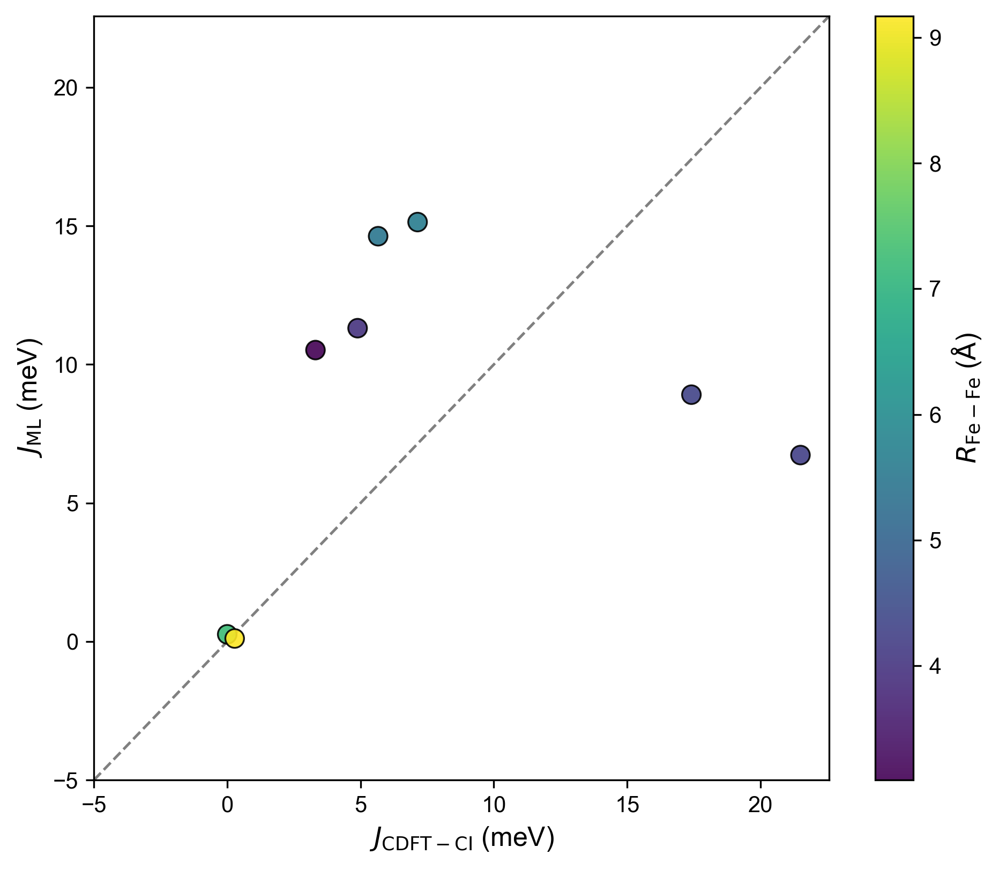

In [39]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Data Setup
data = {
    "Bin": [ "2", "3", "4", "5", "6", "9*", "9*", "10*"],
    "J_ML": [ 6.73, 14.63, 0.26, 0.11, 15.14, 8.91, 10.52, 11.31],
    "J_CDFT": [ 21.50, 5.66, 0.00, 0.28, 7.14, 17.41, 3.31, 4.89],
    "R_FeFe": [ 4.24, 5.47, 7.23, 9.17, 5.61, 4.32, 3.09, 3.97],
}
df = pd.DataFrame(data)

cdft_raw = df["J_CDFT"].values
ml_raw = df["J_ML"].values

# Calculate Error Metrics
mae = mean_absolute_error(cdft_raw, ml_raw)
rmse = np.sqrt(mean_squared_error(cdft_raw, ml_raw))
r2 = r2_score(cdft_raw, ml_raw)

# 2. Plotting Setup (Publication Style)
plt.rcParams["font.sans-serif"] = "Arial"
plt.rcParams["font.family"] = "sans-serif"

fig, ax = plt.subplots(figsize=(6.5, 5.5), dpi=300)

# Main Scatter Plot (Linear Scale)
scatter = ax.scatter(
    cdft_raw,
    ml_raw,
    c=df["R_FeFe"],
    cmap="viridis",
    s=70,
    edgecolor="k",
    linewidth=0.8,
    zorder=3,
    alpha=0.9,
)

# Colorbar showing Fe-Fe distance
cbar = fig.colorbar(scatter, ax=ax)
cbar.set_label(r"$R_{\mathrm{Fe-Fe}}$ ($\mathrm{\AA}$)", fontsize=12)

# Axis limits and Parity Line (1:1 line) for Main Plot
max_val = max(cdft_raw.max(), ml_raw.max()) * 1.05
min_val = -5  # Slight buffer below 0 to display zero points cleanly

ax.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="gray",
    linestyle="--",
    linewidth=1.2,
    label="1:1 Ideal",
    zorder=2,
)

ax.set_xlabel(r"$J_{\mathrm{CDFT-CI}}$ (meV)", fontsize=12)
ax.set_ylabel(r"$J_{\mathrm{ML}}$ (meV)", fontsize=12)
ax.set_xlim(min_val, max_val)
ax.set_ylim(min_val, max_val)

# Add Metrics Text Box in top-left corner
# metrics_text = (
#     f"$\mathrm{{MAE}} = {mae:.2f}\ \mathrm{{meV}}$\n"
#     f"$\mathrm{{RMSE}} = {rmse:.2f}\ \mathrm{{meV}}$\n"
#     f"$R^2 = {r2:.3f}$"
# )
# ax.text(
#     0.05,
#     0.95,
#     metrics_text,
#     transform=ax.transAxes,
#     fontsize=10,
#     verticalalignment="top",
#     bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.8, edgecolor="gray"),
# )

# 3. Create Inset Axes (Zoom for 0–20 meV Region)
# Position: [left, bottom, width, height] relative to main plot (0 to 1)
# ax_inset = ax.inset_axes([0.52, 0.12, 0.42, 0.42])

# ax_inset.scatter(
#     cdft_raw,
#     ml_raw,
#     c=df["R_FeFe"],
#     cmap="viridis",
#     s=45,
#     edgecolor="k",
#     linewidth=0.6,
#     zorder=3,
#     alpha=0.9,
# )

# # Parity line in inset
# inset_limit = 20
# ax_inset.plot(
#     [0, inset_limit],
#     [0, inset_limit],
#     color="gray",
#     linestyle="--",
#     linewidth=1.0,
#     zorder=2,
# )

# # Inset limits and ticks
# ax_inset.set_xlim(-0.5, inset_limit)
# ax_inset.set_ylim(-0.5, inset_limit)
# ax_inset.set_title(r"Zoom: 0–20 meV", fontsize=9, pad=3)
# ax_inset.tick_params(axis="both", which="major", labelsize=8)

# # Connect the zoomed area on the main axes to the inset box
# ax.indicate_inset_zoom(ax_inset, edgecolor="gray", alpha=0.5)

plt.tight_layout()
plt.show()

In [11]:
import os
import numpy as np
import pandas as pd

# -----------------------------------------------------------------------------
# File paths and configuration
# -----------------------------------------------------------------------------
planar_pred_csv = "../four-model/MD-traj-result/planar_tanfunction_features/RF_P1_planar_predicted_couplings.csv"
output_dir = "../four-model/MD-traj-result/planar_tanfunction_features/validation_selection"
os.makedirs(output_dir, exist_ok=True)

name_col = "name"
coupling_col = "pred_coupling_meV"
n_bins = 10
n_per_bin = 2
random_state = 42

# List of the 7 features to extract and preserve in output CSVs
feature_cols = [
    "cos_theta",
    "cos_4phi",
    "cos_4psi",
    "FeFe_Dist_Ang",
    "Min_HeavyDist_Ang",
    "dz",
    "d_lateral",
]

# -----------------------------------------------------------------------------
# Read input data and validate columns
# -----------------------------------------------------------------------------
df = pd.read_csv(planar_pred_csv)

required_cols = [name_col, coupling_col] + feature_cols
missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    raise ValueError(f"Missing required columns in {planar_pred_csv}: {missing_cols}")


def build_selected_row(bin_id, row, orig_row_idx):
    """Helper function to format selected output rows including all 7 features."""
    record = {
        "Bin": bin_id,
        "Row_Index": int(orig_row_idx),
        "Frame_Index": int(row["Frame_Index"]) if "Frame_Index" in row else int(orig_row_idx),
        "Filename": row[name_col],
        "pred_coupling_meV": float(row[coupling_col]),
    }
    # Append the 7 feature columns
    for feat in feature_cols:
        record[feat] = float(row[feat])
    return record


# =============================================================================
# Selection 1: 20 dimers sampled across contiguous trajectory tenths (time)
# =============================================================================
sort_col = "Frame_Index" if "Frame_Index" in df.columns else None
df_time_ordered = df.sort_values(sort_col).reset_index(drop=True) if sort_col else df.reset_index(drop=True)

rng = np.random.default_rng(random_state)
bin_edges_time = np.array_split(np.arange(len(df_time_ordered)), n_bins)

selected_time_rows = []
for bin_id, bin_indices in enumerate(bin_edges_time, start=1):
    n_pick = min(n_per_bin, len(bin_indices))
    picked_idx = rng.choice(bin_indices, size=n_pick, replace=False)
    picked_idx.sort()
    for idx in picked_idx:
        row = df_time_ordered.iloc[idx]
        selected_time_rows.append(build_selected_row(bin_id, row, idx))

val_time_df = pd.DataFrame(selected_time_rows)
csv_time_out = os.path.join(output_dir, "planar_tanfunction_validation_20_selection.csv")
val_time_df.to_csv(csv_time_out, index=False)

print("=" * 70)
print(f"Selection 1 Complete: Trajectory Tenths Sampling")
print(f"Selected {len(val_time_df)} dimers ({n_per_bin} from each of {n_bins} trajectory tenths)")
print(f"Saved to: {csv_time_out}")
print("=" * 70)


# =============================================================================
# Selection 2: 20 dimers sampled across coupling magnitude distribution
# =============================================================================
df_coupling_ordered = df.sort_values(coupling_col, ascending=True).reset_index(drop=True)

# Re-initialize RNG to keep sampling independent if needed
rng = np.random.default_rng(random_state)
bin_edges_coupling = np.array_split(np.arange(len(df_coupling_ordered)), n_bins)

selected_coupling_rows = []
for bin_id, bin_indices in enumerate(bin_edges_coupling, start=1):
    n_pick = min(n_per_bin, len(bin_indices))
    picked_idx = rng.choice(bin_indices, size=n_pick, replace=False)
    picked_idx.sort()
    for idx in picked_idx:
        row = df_coupling_ordered.iloc[idx]
        selected_coupling_rows.append(build_selected_row(bin_id, row, idx))

val_coupling_df = pd.DataFrame(selected_coupling_rows)
csv_coupling_out = os.path.join(
    output_dir, "planar_tanfunction_validation_20_increasing_coupling-bins.csv"
)
val_coupling_df.to_csv(csv_coupling_out, index=False)

print(f"\nSelection 2 Complete: Coupling Magnitude Sampling")
print(f"Selected {len(val_coupling_df)} dimers ({n_per_bin} from each of {n_bins} coupling magnitude bins)")
print(f"Saved to: {csv_coupling_out}")
print("=" * 70)

Selection 1 Complete: Trajectory Tenths Sampling
Selected 20 dimers (2 from each of 10 trajectory tenths)
Saved to: ../four-model/MD-traj-result/planar_tanfunction_features/validation_selection/planar_tanfunction_validation_20_selection.csv

Selection 2 Complete: Coupling Magnitude Sampling
Selected 20 dimers (2 from each of 10 coupling magnitude bins)
Saved to: ../four-model/MD-traj-result/planar_tanfunction_features/validation_selection/planar_tanfunction_validation_20_increasing_coupling-bins.csv


##  Quantitative Planar vs Distorted Comparison
Compute side-by-side summary metrics from saved prediction CSV files and export a comparison table.

In [16]:
import os
import numpy as np
import pandas as pd

md_output_dir = "../four-model/MD-traj-result/planar_tanfunction_features"
summary_csv = os.path.join(md_output_dir, "ALL_MODELS_planar_vs_distorted_summary.csv")
ratio_csv = os.path.join(md_output_dir, "ALL_MODELS_planar_vs_distorted_ratio_summary.csv")

# Keep this threshold synchronized with your classification cells
significant_threshold_mev = 0.1
model_names = ["KRR", "SVM", "RF", "XGB"]


def summarize(model_name, dataset_name, values_mev, threshold_mev):
    values = np.asarray(values_mev, dtype=float)
    total = len(values)
    n_sig = int(np.sum(values >= threshold_mev))
    frac_sig = (n_sig / total) * 100 if total > 0 else 0.0
    return {
        "Model": model_name,
        "Dataset": dataset_name,
        "N_Frames": total,
        "Mean_meV": float(np.mean(values)) if total > 0 else np.nan,
        "Median_meV": float(np.median(values)) if total > 0 else np.nan,
        "P95_meV": float(np.percentile(values, 95)) if total > 0 else np.nan,
        "P99_meV": float(np.percentile(values, 99)) if total > 0 else np.nan,
        "Max_meV": float(np.max(values)) if total > 0 else np.nan,
        f"N_Above_{threshold_mev:g}_meV": n_sig,
        f"Pct_Above_{threshold_mev:g}_meV": frac_sig,
    }


summary_rows = []
ratio_rows = []

for model_name in model_names:
    planar_csv = os.path.join(md_output_dir, f"{model_name}_P1_planar_predicted_couplings.csv")
    distorted_csv = os.path.join(md_output_dir, f"{model_name}_P1_distorted_predicted_couplings.csv")

    if not os.path.exists(planar_csv) or not os.path.exists(distorted_csv):
        print(f"Skipping {model_name}: missing planar/distorted CSV")
        continue

    planar_df = pd.read_csv(planar_csv)
    distorted_df = pd.read_csv(distorted_csv)

    for dataset_name, df_tmp in [("Planar", planar_df), ("Distorted", distorted_df)]:
        if "pred_coupling_meV" not in df_tmp.columns:
            raise ValueError(f"Missing 'pred_coupling_meV' in {model_name} {dataset_name} prediction CSV")

    planar_vals = planar_df["pred_coupling_meV"].to_numpy(dtype=float)
    distorted_vals = distorted_df["pred_coupling_meV"].to_numpy(dtype=float)

    summary_rows.append(summarize(model_name, "Planar", planar_vals, significant_threshold_mev))
    summary_rows.append(summarize(model_name, "Distorted", distorted_vals, significant_threshold_mev))

    planar_mean = float(np.mean(planar_vals)) if len(planar_vals) > 0 else np.nan
    dist_mean = float(np.mean(distorted_vals)) if len(distorted_vals) > 0 else np.nan
    planar_p95 = float(np.percentile(planar_vals, 95)) if len(planar_vals) > 0 else np.nan
    dist_p95 = float(np.percentile(distorted_vals, 95)) if len(distorted_vals) > 0 else np.nan

    ratio_rows.append(
        {
            "Model": model_name,
            "Distorted_to_Planar_Mean_Ratio": (dist_mean / planar_mean) if planar_mean and planar_mean > 0 else np.nan,
            "Distorted_to_Planar_P95_Ratio": (dist_p95 / planar_p95) if planar_p95 and planar_p95 > 0 else np.nan,
        }
    )

if summary_rows:
    summary_df = pd.DataFrame(summary_rows).sort_values(["Model", "Dataset"]).reset_index(drop=True)
    ratio_df = pd.DataFrame(ratio_rows).sort_values("Model").reset_index(drop=True)

    print("Planar vs Distorted quantitative summary for all models:")
    print(summary_df.round(4).to_string(index=False))
    print("\nDistorted/Planar ratio summary by model:")
    print(ratio_df.round(4).to_string(index=False))

    summary_df.to_csv(summary_csv, index=False)
    ratio_df.to_csv(ratio_csv, index=False)

    print(f"\nSaved all-model summary CSV to: {summary_csv}")
    print(f"Saved ratio summary CSV to: {ratio_csv}")
else:
    print("No model summaries were generated. Check MD prediction CSV files.")



Planar vs Distorted quantitative summary for all models:
Model   Dataset  N_Frames  Mean_meV  Median_meV  P95_meV  P99_meV  Max_meV  N_Above_0.1_meV  Pct_Above_0.1_meV
  KRR Distorted     20002    5.8439      2.4662  28.4119  69.3407 243.9287            18522            92.6007
  KRR    Planar     20002    4.0206      2.4662  16.3471  36.2170 205.3127            19125            95.6154
   RF Distorted     20002    2.6730      0.1538  13.3103  30.2095  50.8315            16700            83.4917
   RF    Planar     20002    2.4440      0.1739  13.8408  30.9657  54.3863            15672            78.3522
  SVM Distorted     20002    4.4124      0.9567  26.8439  62.9492 128.3927            19769            98.8351
  SVM    Planar     20002    3.9427      0.9567  19.2535  71.6118 145.0051            19637            98.1752
  XGB Distorted     20002    2.7366      0.2444  16.3142  28.2817  54.4934            18069            90.3360
  XGB    Planar     20002    2.4383      0.2713  14.757

# Quantitaive planar vs distorted for full and high-low 5%

In [17]:
import os
import numpy as np
import pandas as pd

md_output_dir = "../four-model/MD-traj-result"
summary_csv = os.path.join(md_output_dir, "ALL_MODELS_planar_vs_distorted_summary.csv")
ratio_csv = os.path.join(md_output_dir, "ALL_MODELS_planar_vs_distorted_ratio_summary.csv")

# Keep this threshold synchronized with your classification cells
significant_threshold_mev = 0.1
model_names = ["KRR", "SVM", "RF", "XGB"]


def summarize(model_name, dataset_name, values_mev, threshold_mev):
    values = np.asarray(values_mev, dtype=float)
    total = len(values)
    n_sig = int(np.sum(values >= threshold_mev))
    frac_sig = (n_sig / total) * 100 if total > 0 else 0.0
    mean_val = float(np.mean(values)) if total > 0 else np.nan
    
    return {
        "Model": model_name,
        "Dataset": dataset_name,
        "N_Frames": total,
        "Mean_meV": mean_val,
        "Sq_Mean_meV": (mean_val ** 2) if total > 0 else np.nan,  # <J>^2 (Square of mean)
        "Mean_Sq_meV": float(np.mean(values ** 2)) if total > 0 else np.nan,  # <J^2> (Mean of squares)
        "Median_meV": float(np.median(values)) if total > 0 else np.nan,
        "P95_meV": float(np.percentile(values, 95)) if total > 0 else np.nan,
        "P99_meV": float(np.percentile(values, 99)) if total > 0 else np.nan,
        "Max_meV": float(np.max(values)) if total > 0 else np.nan,
        f"N_Above_{threshold_mev:g}_meV": n_sig,
        f"Pct_Above_{threshold_mev:g}_meV": frac_sig,
    }


summary_rows = []
ratio_rows = []

for model_name in model_names:
    planar_csv = os.path.join(md_output_dir, f"{model_name}_P1_planar_predicted_couplings.csv")
    distorted_csv = os.path.join(md_output_dir, f"{model_name}_P1_distorted_predicted_couplings.csv")

    if not os.path.exists(planar_csv) or not os.path.exists(distorted_csv):
        print(f"Skipping {model_name}: missing planar/distorted CSV")
        continue

    planar_df = pd.read_csv(planar_csv)
    distorted_df = pd.read_csv(distorted_csv)

    for dataset_name, df_tmp in [("Planar", planar_df), ("Distorted", distorted_df)]:
        if "pred_coupling_meV" not in df_tmp.columns:
            raise ValueError(f"Missing 'pred_coupling_meV' in {model_name} {dataset_name} prediction CSV")

    # Process Planar (Full, Top 5%, Bottom 5%)
    p_sorted = planar_df.sort_values("pred_coupling_meV", ascending=False).reset_index(drop=True)
    n_top_p = int(np.ceil(0.05 * len(p_sorted)))
    p_high = p_sorted.iloc[:n_top_p]
    p_low = p_sorted.iloc[-n_top_p:]

    summary_rows.append(summarize(model_name, "Planar (Full)", planar_df["pred_coupling_meV"].to_numpy(dtype=float), significant_threshold_mev))
    summary_rows.append(summarize(model_name, "Planar (Top 5%)", p_high["pred_coupling_meV"].to_numpy(dtype=float), significant_threshold_mev))
    summary_rows.append(summarize(model_name, "Planar (Bottom 5%)", p_low["pred_coupling_meV"].to_numpy(dtype=float), significant_threshold_mev))

    # Process Distorted (Full, Top 5%, Bottom 5%)
    d_sorted = distorted_df.sort_values("pred_coupling_meV", ascending=False).reset_index(drop=True)
    n_top_d = int(np.ceil(0.05 * len(d_sorted)))
    d_high = d_sorted.iloc[:n_top_d]
    d_low = d_sorted.iloc[-n_top_d:]

    summary_rows.append(summarize(model_name, "Distorted (Full)", distorted_df["pred_coupling_meV"].to_numpy(dtype=float), significant_threshold_mev))
    summary_rows.append(summarize(model_name, "Distorted (Top 5%)", d_high["pred_coupling_meV"].to_numpy(dtype=float), significant_threshold_mev))
    summary_rows.append(summarize(model_name, "Distorted (Bottom 5%)", d_low["pred_coupling_meV"].to_numpy(dtype=float), significant_threshold_mev))

    # Ratios based on full datasets
    planar_vals = planar_df["pred_coupling_meV"].to_numpy(dtype=float)
    distorted_vals = distorted_df["pred_coupling_meV"].to_numpy(dtype=float)
    
    planar_mean = float(np.mean(planar_vals)) if len(planar_vals) > 0 else np.nan
    dist_mean = float(np.mean(distorted_vals)) if len(distorted_vals) > 0 else np.nan
    planar_p95 = float(np.percentile(planar_vals, 95)) if len(planar_vals) > 0 else np.nan
    dist_p95 = float(np.percentile(distorted_vals, 95)) if len(distorted_vals) > 0 else np.nan

    ratio_rows.append(
        {
            "Model": model_name,
            "Distorted_to_Planar_Mean_Ratio": (dist_mean / planar_mean) if planar_mean and planar_mean > 0 else np.nan,
            "Distorted_to_Planar_P95_Ratio": (dist_p95 / planar_p95) if planar_p95 and planar_p95 > 0 else np.nan,
        }
    )

if summary_rows:
    summary_df = pd.DataFrame(summary_rows).sort_values(["Model", "Dataset"]).reset_index(drop=True)
    ratio_df = pd.DataFrame(ratio_rows).sort_values("Model").reset_index(drop=True)

    print("Planar vs Distorted quantitative summary for all models (Full, Top 5%, Bottom 5%):")
    print(summary_df.round(4).to_string(index=False))
    print("\nDistorted/Planar ratio summary by model:")
    print(ratio_df.round(4).to_string(index=False))

    summary_df.to_csv(summary_csv, index=False)
    ratio_df.to_csv(ratio_csv, index=False)

    print(f"\nSaved all-model summary CSV to: {summary_csv}")
    print(f"Saved ratio summary CSV to: {ratio_csv}")
else:
    print("No model summaries were generated. Check MD prediction CSV files.")

Planar vs Distorted quantitative summary for all models (Full, Top 5%, Bottom 5%):
Model               Dataset  N_Frames  Mean_meV  Sq_Mean_meV  Mean_Sq_meV  Median_meV  P95_meV  P99_meV  Max_meV  N_Above_0.1_meV  Pct_Above_0.1_meV
  KRR Distorted (Bottom 5%)      1001    0.0023       0.0000       0.0000      0.0011   0.0088   0.0101   0.0107                0             0.0000
  KRR      Distorted (Full)     20002    5.8439      34.1513     211.6669      2.4662  28.4119  69.3407 243.9287            18522            92.6007
  KRR    Distorted (Top 5%)      1001   53.3476    2845.9658    3662.9692     42.3248 115.5150 161.4018 243.9287             1001           100.0000
  KRR    Planar (Bottom 5%)      1001    0.0314       0.0010       0.0016      0.0282   0.0717   0.0753   0.0762                0             0.0000
  KRR         Planar (Full)     20002    3.6106      13.0361      66.2639      2.4662  13.1469  33.5265 199.1639            18800            93.9906
  KRR       Planar (Top

# to quantify the structural signature of high and low coupling 

In [15]:
# Task 2: RF structural signatures across full, top 5%, and bottom 5% ensembles
import os
import numpy as np
import pandas as pd

md_output_dir = "../four-model/MD-traj-result/planar_tanfunction_features"
rf_files = {
    "Planar": os.path.join(md_output_dir, "RF_P1_planar_predicted_couplings.csv"),
    "Distorted": os.path.join(md_output_dir, "RF_P1_distorted_predicted_couplings.csv"),
}
coupling_col = "pred_coupling_meV"
short_distance_cutoff_ang = 5.0  # R_c; change this value if needed
required = [coupling_col, "Min_HeavyDist_Ang", "cos_4phi", "cos_theta", "cos_4psi"]

# Updated criteria list to include cos(4phi) <= -0.85
criteria = [
    "A_short_distance", 
    "B_orientation", 
    "A_or_B", 
    "A_and_B", 
    "cos_4phi_le_minus_0.85",  # Added criterion
    "cos_theta_ge_0.7", 
    "cos_4psi_ge_0.7", 
    "cos_4psi_le_minus_0.7"
]

def add_criteria(df):
    df = df.copy()
    df["A_short_distance"] = df["Min_HeavyDist_Ang"] < short_distance_cutoff_ang
    df["B_orientation"] = df["cos_4phi"] >= 0.85
    df["A_or_B"] = df["A_short_distance"] | df["B_orientation"]
    df["A_and_B"] = df["A_short_distance"] & df["B_orientation"]
    df["cos_4phi_le_minus_0.85"] = df["cos_4phi"] <= -0.85  # Added definition
    df["cos_theta_ge_0.7"] = df["cos_theta"] >= 0.7
    df["cos_4psi_ge_0.7"] = df["cos_4psi"] >= 0.7
    df["cos_4psi_le_minus_0.7"] = df["cos_4psi"] <= -0.7
    return df

rows = []
for geometry, csv_path in rf_files.items():
    if not os.path.exists(csv_path):
        raise FileNotFoundError(csv_path)
    df = pd.read_csv(csv_path)
    missing = [column for column in required if column not in df.columns]
    if missing:
        raise ValueError(f"{geometry} RF file is missing: {missing}")
    
    df = add_criteria(df.dropna(subset=required)).sort_values(coupling_col, ascending=False).reset_index(drop=True)
    n_extreme = max(1, int(np.ceil(0.05 * len(df))))
    ensembles = {"Full": df, "Top 5%": df.iloc[:n_extreme], "Bottom 5%": df.iloc[-n_extreme:]}
    baseline = {criterion: float(df[criterion].mean()) for criterion in criteria}
    
    for ensemble, subset in ensembles.items():
        for criterion in criteria:
            fraction = float(subset[criterion].mean())
            rows.append({
                "Geometry": geometry, 
                "Ensemble": ensemble, 
                "Criterion": criterion, 
                "N": len(subset), 
                "N_satisfying": int(subset[criterion].sum()), 
                "Fraction": fraction, 
                "Percent": 100 * fraction, 
                "Enrichment_vs_full": fraction / baseline[criterion] if baseline[criterion] else np.nan
            })
    print(f"{geometry}: {len(df):,} valid frames; {n_extreme:,} frames per 5% ensemble")

structural_signature_table = pd.DataFrame(rows).sort_values(["Geometry", "Criterion", "Ensemble"]).reset_index(drop=True)
output_csv = os.path.join(md_output_dir, "RF_structural_signature_fractions_configuration.csv")
structural_signature_table.to_csv(output_csv, index=False)

print(f"\nA: Min_HeavyDist_Ang < {short_distance_cutoff_ang:g} Angstrom; B: cos_4phi >= 0.85")
print("Fraction is the fraction satisfying a criterion; enrichment is relative to that geometry's full ensemble.")
display(structural_signature_table.round({"Fraction": 4, "Percent": 2, "Enrichment_vs_full": 3}))

# Focused table for cos_4phi <= -0.85 comparison
phi_neg_table = structural_signature_table[structural_signature_table["Criterion"] == "cos_4phi_le_minus_0.85"]
print("\nFocused cos(4phi) <= -0.85 ensemble distribution:")
display(phi_neg_table[["Geometry", "Ensemble", "N", "N_satisfying", "Percent", "Enrichment_vs_full"]].round({"Percent": 2, "Enrichment_vs_full": 3}))

print(f"Saved table to: {output_csv}")

# # Task 2: RF structural signatures across full, top 5%, and bottom 5% ensembles
# import os
# import numpy as np
# import pandas as pd

# md_output_dir = "../four-model/MD-traj-result/planar_tanfunction_features"
# rf_files = {
#     "Planar": os.path.join(md_output_dir, "RF_P1_planar_predicted_couplings.csv"),
#     "Distorted": os.path.join(md_output_dir, "RF_P1_distorted_predicted_couplings.csv"),
# }
# coupling_col = "pred_coupling_meV"
# short_distance_cutoff_ang = 5.0  # R_c; change this value if needed
# required = [coupling_col, "Min_HeavyDist_Ang", "cos_4phi", "cos_theta", "cos_4psi"]
# criteria = ["A_short_distance", "B_orientation", "A_or_B", "A_and_B", "cos_theta_ge_0.7", "cos_4psi_ge_0.7", "cos_4psi_le_minus_0.7"]

# def add_criteria(df):
#     df = df.copy()
#     df["A_short_distance"] = df["Min_HeavyDist_Ang"] < short_distance_cutoff_ang
#     df["B_orientation"] = df["cos_4phi"] >= 0.85
#     df["A_or_B"] = df["A_short_distance"] | df["B_orientation"]
#     df["A_and_B"] = df["A_short_distance"] & df["B_orientation"]
#     df["cos_theta_ge_0.7"] = df["cos_theta"] >= 0.7
#     df["cos_4psi_ge_0.7"] = df["cos_4psi"] >= 0.7
#     df["cos_4psi_le_minus_0.7"] = df["cos_4psi"] <= -0.7
#     return df

# rows = []
# for geometry, csv_path in rf_files.items():
#     if not os.path.exists(csv_path):
#         raise FileNotFoundError(csv_path)
#     df = pd.read_csv(csv_path)
#     missing = [column for column in required if column not in df.columns]
#     if missing:
#         raise ValueError(f"{geometry} RF file is missing: {missing}")
#     df = add_criteria(df.dropna(subset=required)).sort_values(coupling_col, ascending=False).reset_index(drop=True)
#     n_extreme = max(1, int(np.ceil(0.05 * len(df))))
#     ensembles = {"Full": df, "Top 5%": df.iloc[:n_extreme], "Bottom 5%": df.iloc[-n_extreme:]}
#     baseline = {criterion: float(df[criterion].mean()) for criterion in criteria}
#     for ensemble, subset in ensembles.items():
#         for criterion in criteria:
#             fraction = float(subset[criterion].mean())
#             rows.append({"Geometry": geometry, "Ensemble": ensemble, "Criterion": criterion, "N": len(subset), "N_satisfying": int(subset[criterion].sum()), "Fraction": fraction, "Percent": 100 * fraction, "Enrichment_vs_full": fraction / baseline[criterion] if baseline[criterion] else np.nan})
#     print(f"{geometry}: {len(df):,} valid frames; {n_extreme:,} frames per 5% ensemble")

# structural_signature_table = pd.DataFrame(rows).sort_values(["Geometry", "Criterion", "Ensemble"]).reset_index(drop=True)
# output_csv = os.path.join(md_output_dir, "RF_structural_signature_fractions_configuration.csv")
# structural_signature_table.to_csv(output_csv, index=False)
# print(f"\nA: Min_HeavyDist_Ang < {short_distance_cutoff_ang:g} Angstrom; B: cos_4phi >= 0.85")
# print("Fraction is the fraction satisfying a criterion; enrichment is relative to that geometry's full ensemble.")
# display(structural_signature_table.round({"Fraction": 4, "Percent": 2, "Enrichment_vs_full": 3}))
# ab_table = structural_signature_table[structural_signature_table["Criterion"] == "A_and_B"]
# print("\nFocused A AND B overlap: strong-coupling configurations satisfying both primary signatures")
# display(ab_table[["Geometry", "Ensemble", "N", "N_satisfying", "Percent", "Enrichment_vs_full"]].round({"Percent": 2, "Enrichment_vs_full": 3}))
# print(f"Saved table to: {output_csv}")

Planar: 20,002 valid frames; 1,001 frames per 5% ensemble
Distorted: 20,002 valid frames; 1,001 frames per 5% ensemble

A: Min_HeavyDist_Ang < 5 Angstrom; B: cos_4phi >= 0.85
Fraction is the fraction satisfying a criterion; enrichment is relative to that geometry's full ensemble.


,Geometry,Ensemble,Criterion,N,N_satisfying,Fraction,Percent,Enrichment_vs_full
0,Distorted,Bottom 5%,A_and_B,1001,0,0.0000,0.00,0.000
1,Distorted,Full,A_and_B,20002,2595,0.1297,12.97,1.000
2,Distorted,Top 5%,A_and_B,1001,679,0.6783,67.83,5.228
3,Distorted,Bottom 5%,A_or_B,1001,81,0.0809,8.09,0.136
4,Distorted,Full,A_or_B,20002,11903,0.5951,59.51,1.000
5,Distorted,Top 5%,A_or_B,1001,1001,1.0000,100.00,1.680
6,Distorted,Bottom 5%,A_short_distance,1001,81,0.0809,8.09,0.265
7,Distorted,Full,A_short_distance,20002,6110,0.3055,30.55,1.000
8,Distorted,Top 5%,A_short_distance,1001,1001,1.0000,100.00,3.274
9,Distorted,Bottom 5%,B_orientation,1001,0,0.0000,0.00,0.000



Focused cos(4phi) <= -0.85 ensemble distribution:


,Geometry,Ensemble,N,N_satisfying,Percent,Enrichment_vs_full
12,Distorted,Bottom 5%,1001,913,91.21,8.281
13,Distorted,Full,20002,2203,11.01,1.000
14,Distorted,Top 5%,1001,0,0.00,0.000
36,Planar,Bottom 5%,1001,1001,100.00,5.324
37,Planar,Full,20002,3757,18.78,1.000
38,Planar,Top 5%,1001,0,0.00,0.000


Saved table to: ../four-model/MD-traj-result/planar_tanfunction_features/RF_structural_signature_fractions_configuration.csv


In [22]:
# # Standalone Task 2 table generator
# # RF-predicted coupling with R_c = 5.0 Angstrom

# import os
# import numpy as np
# import pandas as pd

# md_output_dir = "../four-model/MD-traj-result"

# coupling_col = "pred_coupling_meV"
# short_distance_cutoff_ang = 5.0
# top_fraction = 0.05

# rf_files = {
#     "Planar": os.path.join(
#         md_output_dir,
#         "RF_P1_planar_predicted_couplings.csv",
#     ),
#     "Distorted": os.path.join(
#         md_output_dir,
#         "RF_P1_distorted_predicted_couplings.csv",
#     ),
# }

# criterion_labels = {
#     "A_short_distance": f"A: R < {short_distance_cutoff_ang:g} Angstrom",
#     "B_orientation": "B: cos(4phi) >= 0.85",
#     "A_or_B": "A or B",
#     "A_and_B": "A and B",
#     "cos_theta_ge_0.7": "cos(theta) >= 0.7",
#     "cos_4psi_ge_0.7": "cos(4psi) >= 0.7",
#     "cos_4psi_le_minus_0.7": "cos(4psi) <= -0.7",
# }

# required_columns = [
#     coupling_col,
#     "Min_HeavyDist_Ang",
#     "cos_4phi",
#     "cos_theta",
#     "cos_4psi",
# ]

# summary_rows = []

# for geometry, csv_path in rf_files.items():

#     if not os.path.exists(csv_path):
#         raise FileNotFoundError(
#             f"RF prediction file not found: {csv_path}"
#         )

#     df = pd.read_csv(csv_path)

#     missing_columns = [
#         column
#         for column in required_columns
#         if column not in df.columns
#     ]

#     if missing_columns:
#         raise ValueError(
#             f"{geometry} file is missing columns: {missing_columns}"
#         )

#     df = df.dropna(subset=required_columns).copy()

#     # Sort from highest to lowest predicted coupling.
#     df = df.sort_values(
#         coupling_col,
#         ascending=False,
#     ).reset_index(drop=True)

#     n_extreme = max(
#         1,
#         int(np.ceil(top_fraction * len(df))),
#     )

#     # Define structural criteria.
#     df["A_short_distance"] = (
#         df["Min_HeavyDist_Ang"] < short_distance_cutoff_ang
#     )

#     df["B_orientation"] = df["cos_4phi"] >= 0.85

#     df["A_or_B"] = (
#         df["A_short_distance"]
#         | df["B_orientation"]
#     )

#     df["A_and_B"] = (
#         df["A_short_distance"]
#         & df["B_orientation"]
#     )

#     df["cos_theta_ge_0.7"] = df["cos_theta"] >= 0.7

#     df["cos_4psi_ge_0.7"] = df["cos_4psi"] >= 0.7

#     df["cos_4psi_le_minus_0.7"] = (
#         df["cos_4psi"] <= -0.7
#     )

#     # Define complete, bottom 5%, and top 5% ensembles.
#     ensembles = {
#         "Full": df,
#         "Bottom 5%": df.iloc[-n_extreme:],
#         "Top 5%": df.iloc[:n_extreme],
#     }

#     for criterion, label in criterion_labels.items():

#         for ensemble_name, ensemble_df in ensembles.items():

#             fraction = float(
#                 ensemble_df[criterion].mean()
#             )

#             summary_rows.append(
#                 {
#                     "Structural Criterion": label,
#                     "Geometry": geometry,
#                     "Ensemble": ensemble_name,
#                     "N": len(ensemble_df),
#                     "N_satisfying": int(
#                         ensemble_df[criterion].sum()
#                     ),
#                     "Percent": 100.0 * fraction,
#                 }
#             )

# # Long-format table containing counts and percentages.
# structural_signature_table = pd.DataFrame(summary_rows)

# # Convert to publication-style wide table.
# structural_percent_table = (
#     structural_signature_table
#     .pivot(
#         index="Structural Criterion",
#         columns=["Geometry", "Ensemble"],
#         values="Percent",
#     )
#     .reset_index()
# )

# desired_columns = [
#     ("Planar", "Full"),
#     ("Planar", "Bottom 5%"),
#     ("Planar", "Top 5%"),
#     ("Distorted", "Full"),
#     ("Distorted", "Bottom 5%"),
#     ("Distorted", "Top 5%"),
# ]

# for column in desired_columns:
#     if column not in structural_percent_table.columns:
#         structural_percent_table[column] = np.nan

# structural_percent_table = structural_percent_table[
#     ["Structural Criterion"] + desired_columns
# ]

# structural_percent_table.columns = [
#     "Structural Criterion",
#     "Planar Full (%)",
#     "Planar Bottom 5% (%)",
#     "Planar Top 5% (%)",
#     "Distorted Full (%)",
#     "Distorted Bottom 5% (%)",
#     "Distorted Top 5% (%)",
# ]

# # Save both detailed and publication-style tables.
# detailed_output_csv = os.path.join(
#     md_output_dir,
#     "RF_min_5task2_structural_signature_detailed.csv",
# )

# publication_output_csv = os.path.join(
#     md_output_dir,
#     "RF_min_5task2_structural_signature_percentage_table.csv",
# )

# structural_signature_table.to_csv(
#     detailed_output_csv,
#     index=False,
# )

# structural_percent_table.to_csv(
#     publication_output_csv,
#     index=False,
# )

# print(f"R_c = {short_distance_cutoff_ang:g} Angstrom")
# print(f"Frames per extreme ensemble: {n_extreme:,}")
# print()
# print("Structural criterion percentages:")
# display(structural_percent_table.round(2))

# print()
# print(f"Saved detailed table to:")
# print(detailed_output_csv)

# print()
# print(f"Saved publication table to:")
# print(publication_output_csv)

# Feature Analysis for 20000 MD trajectories (Planar + Distorted)

In [ ]:
# Here I will work on feature analysis of planar and Distorted dimer
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =====================================================================
# Predict couplings features for planar + distorted MD trajectories 
# =====================================================================
feature_sources = {
    "planar": "../Results/Bradly_MD_data/P1_planar_full_features.csv",
    "distorted": "../Results/Bradly_MD_data/P1_dimer_full_features.csv",
}

md_output_dir = "../four-model/MD-traj-result/MD_features_analysis"
os.makedirs(md_output_dir, exist_ok=True)

default_features = [
    "Min_HeavyDist_Ang",
    "cos_theta",
    "cos_4phi",
    "cos_4psi",
    "FeFe_Dist_Ang",

]
# -----------------------------------------------------------------
# Load planar + distorted feature CSVs and attach a Frame_Index
# -----------------------------------------------------------------
feature_data = {}
for geometry_name, feature_path in feature_sources.items():
    if not os.path.exists(feature_path):
        print(f"Skipping {geometry_name}: feature file not found at {feature_path}")
        continue

    df_feat = pd.read_csv(feature_path)

    if "Step" in df_feat.columns:
        df_feat["Frame_Index"] = pd.to_numeric(df_feat["Step"], errors="coerce")
    elif "Filename" in df_feat.columns and df_feat["Filename"].astype(str).str.contains(r"\d+").any():
        df_feat["Frame_Index"] = pd.to_numeric(
            df_feat["Filename"].astype(str).str.extract(r"(\d+)")[0],
            errors="coerce",
        )
    else:
        df_feat["Frame_Index"] = np.arange(len(df_feat))

    df_feat["Frame_Index"] = df_feat["Frame_Index"].ffill().bfill().astype(int)
    df_feat = df_feat.sort_values("Frame_Index").reset_index(drop=True)
    feature_data[geometry_name] = df_feat

geometry_colors = {"planar": "#2b5c8f", "distorted": "#d95f02"}
window_size = 100

# -----------------------------------------------------------------
# 1) Per-feature trajectory plots (planar vs distorted, shared y-range)
# -----------------------------------------------------------------
for feature_name in default_features:
    available_geoms = [g for g, df in feature_data.items() if feature_name in df.columns]
    if not available_geoms:
        print(f"Skipping {feature_name}: not found in any feature file")
        continue

    y_all = pd.concat([feature_data[g][feature_name] for g in available_geoms], ignore_index=True)
    y_min, y_max = float(y_all.min()), float(y_all.max())
    pad = 0.05 * (y_max - y_min) if y_max != y_min else max(1e-6, abs(y_min) * 0.05)
    y_low, y_high = y_min - pad, y_max + pad

    fig, axes = plt.subplots(1, len(available_geoms), figsize=(6.5 * len(available_geoms), 5), dpi=300, sharey=True)
    axes = np.atleast_1d(axes)

    for ax, geometry_name in zip(axes, available_geoms):
        df_feat = feature_data[geometry_name]
        color = geometry_colors.get(geometry_name, "#333333")
        rolling_mean = df_feat[feature_name].rolling(window=window_size, center=True, min_periods=1).mean()

        ax.plot(df_feat["Frame_Index"], df_feat[feature_name], alpha=0.3, color=color, linewidth=0.8, label="Frame value")
        ax.plot(df_feat["Frame_Index"], rolling_mean, color="#990000", linewidth=2.0, label=f"{window_size}-frame avg")
        ax.set_title(f"{geometry_name.capitalize()} geometry", fontsize=12, fontweight="bold")
        ax.set_xlabel("MD Step / Frame Index", fontsize=11, fontweight="bold")
        ax.grid(True, linestyle="--", alpha=0.45)
        ax.legend(loc="upper right", fontsize=8, frameon=True, facecolor="white", edgecolor="#cccccc")

    axes[0].set_ylabel(feature_name, fontsize=11, fontweight="bold")
    axes[0].set_ylim(y_low, y_high)
    fig.suptitle(f"{feature_name}: MD Trajectory Comparison", fontsize=13, fontweight="bold", y=1.02)
    fig.tight_layout()

    out_png = os.path.join(md_output_dir, f"{feature_name}_trajectory_planar_vs_distorted.png")
    fig.savefig(out_png, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved feature trajectory plot: {out_png}")

# -----------------------------------------------------------------
# 2) Per-feature distribution plots (planar vs distorted overlaid)
# -----------------------------------------------------------------
for feature_name in default_features:
    available_geoms = [g for g, df in feature_data.items() if feature_name in df.columns]
    if not available_geoms:
        continue

    plt.figure(figsize=(7, 5), dpi=300)
    for geometry_name in available_geoms:
        df_feat = feature_data[geometry_name]
        color = geometry_colors.get(geometry_name, "#333333")
        plt.hist(
            df_feat[feature_name],
            bins=60,
            alpha=0.5,
            color=color,
            label=geometry_name.capitalize(),
            density=True,
        )

    plt.xlabel(feature_name, fontsize=12, fontweight="bold")
    plt.ylabel("Density", fontsize=12, fontweight="bold")
    #plt.title(f"{feature_name}: Distribution Comparison", fontsize=13, fontweight="bold", pad=10)
    plt.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="#cccccc")
    plt.grid(True, linestyle="--", alpha=0.45)
    plt.tight_layout()

    out_png = os.path.join(md_output_dir, f"{feature_name}_distribution_planar_vs_distorted.png")
    plt.savefig(out_png, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved feature distribution plot: {out_png}")

# I want to plot one side with high coupling and other side with low coupling for full MD data set
Include insert that shows the effect of the coordinate— clearly in one side the cos feature(all five features) is that of a low coupling  and then on the opposite of high.  
Understanding their role in finding  high coupling what  is their weight in the full sample of planar versus distorted.  Or even better of both feature being satisfied for the high coupling criterion.

RF-planar: 20002 frames, top/bottom 20002 frames selected
RF-distorted: 20002 frames, top/bottom 20002 frames selected
KRR-planar: 20002 frames, top/bottom 20002 frames selected
KRR-distorted: 20002 frames, top/bottom 20002 frames selected


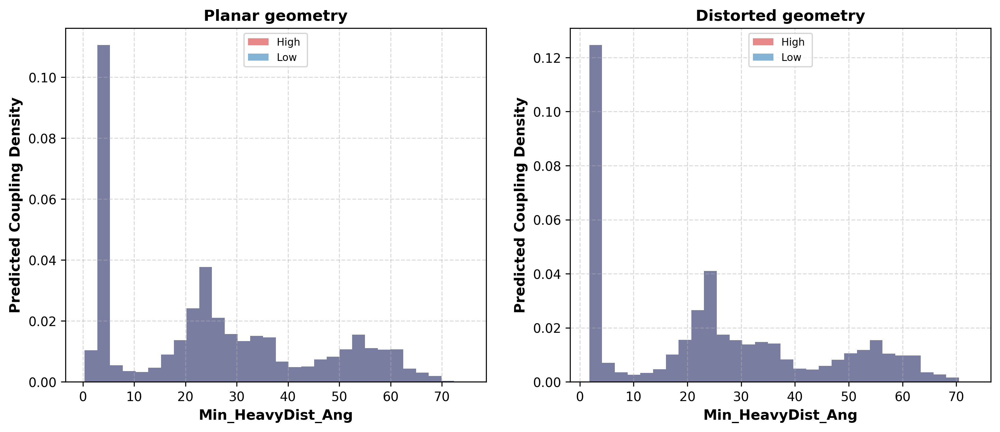

Saved high/low feature plot: ../four-model/MD-traj-result/first-last-5percent-coupling-features/full-coupling-features/RF_Min_HeavyDist_Ang_high_vs_low.png


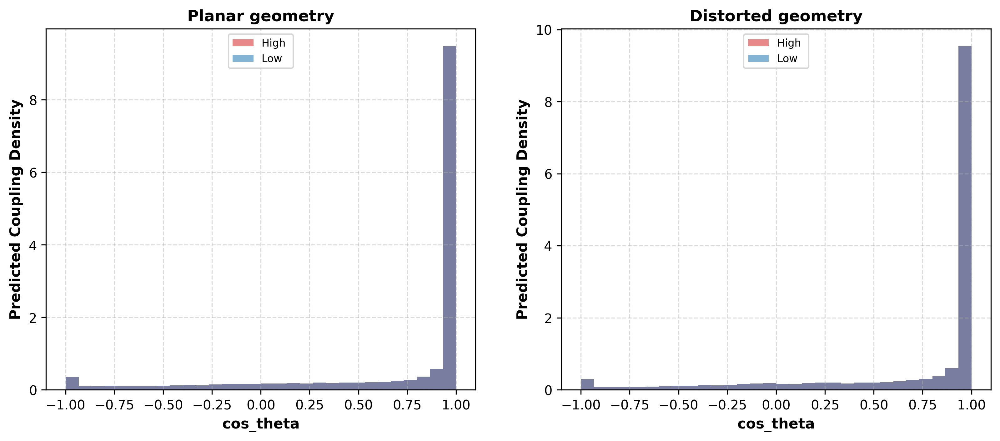

Saved high/low feature plot: ../four-model/MD-traj-result/first-last-5percent-coupling-features/full-coupling-features/RF_cos_theta_high_vs_low.png


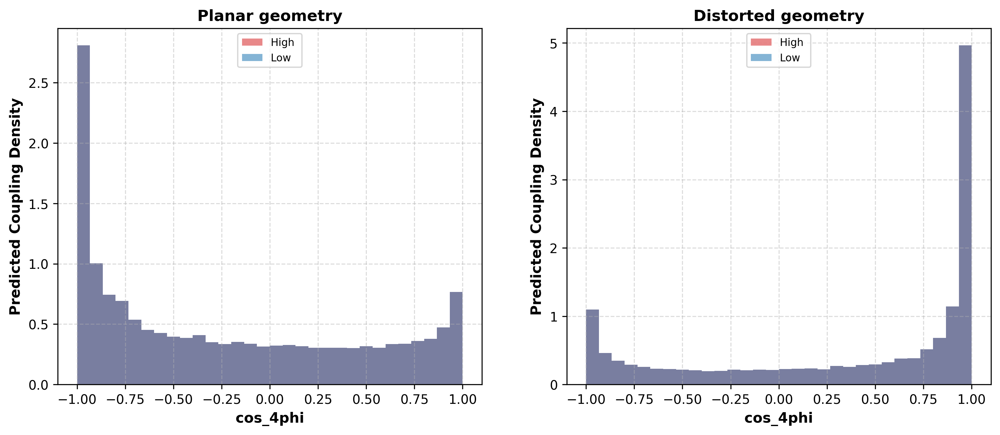

Saved high/low feature plot: ../four-model/MD-traj-result/first-last-5percent-coupling-features/full-coupling-features/RF_cos_4phi_high_vs_low.png


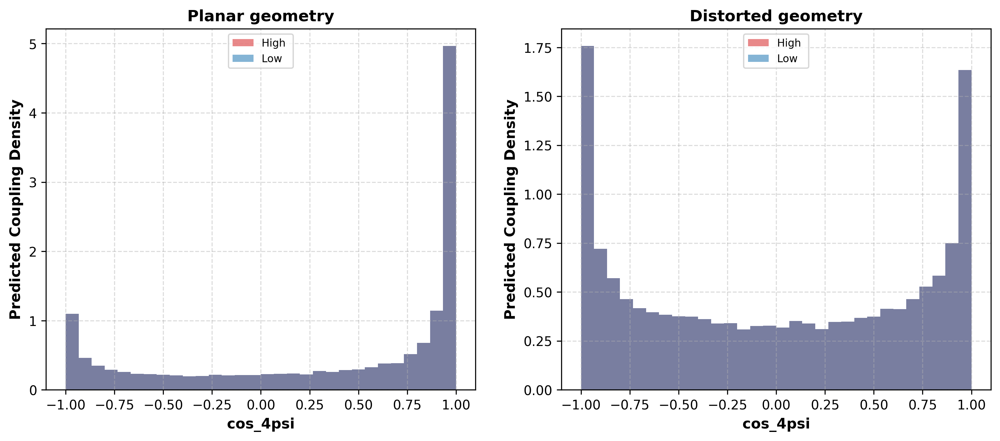

Saved high/low feature plot: ../four-model/MD-traj-result/first-last-5percent-coupling-features/full-coupling-features/RF_cos_4psi_high_vs_low.png


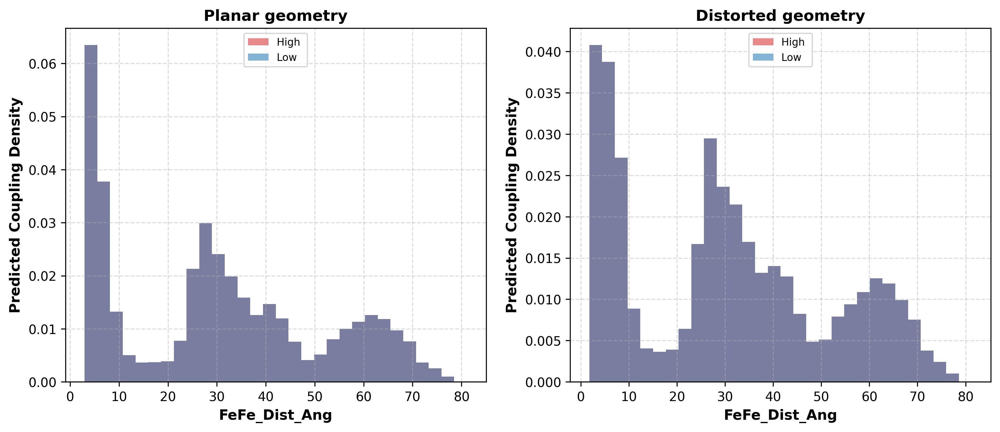

Saved high/low feature plot: ../four-model/MD-traj-result/first-last-5percent-coupling-features/full-coupling-features/RF_FeFe_Dist_Ang_high_vs_low.png


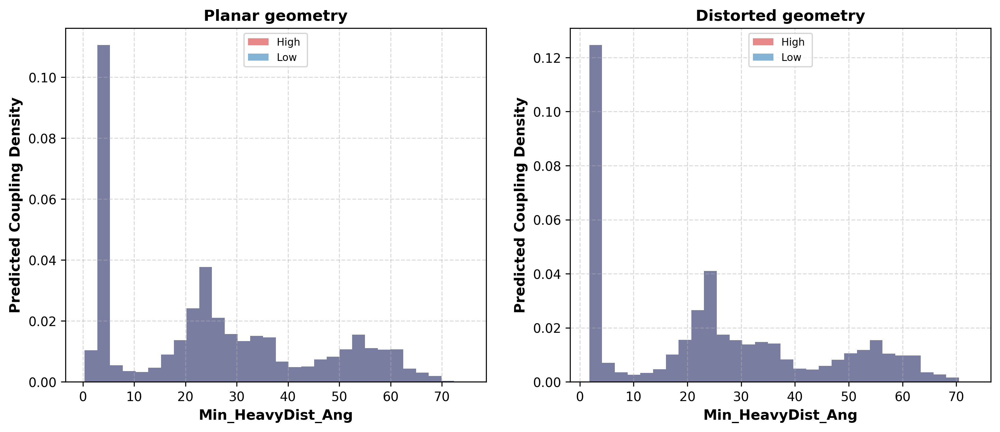

Saved high/low feature plot: ../four-model/MD-traj-result/first-last-5percent-coupling-features/full-coupling-features/KRR_Min_HeavyDist_Ang_high_vs_low.png


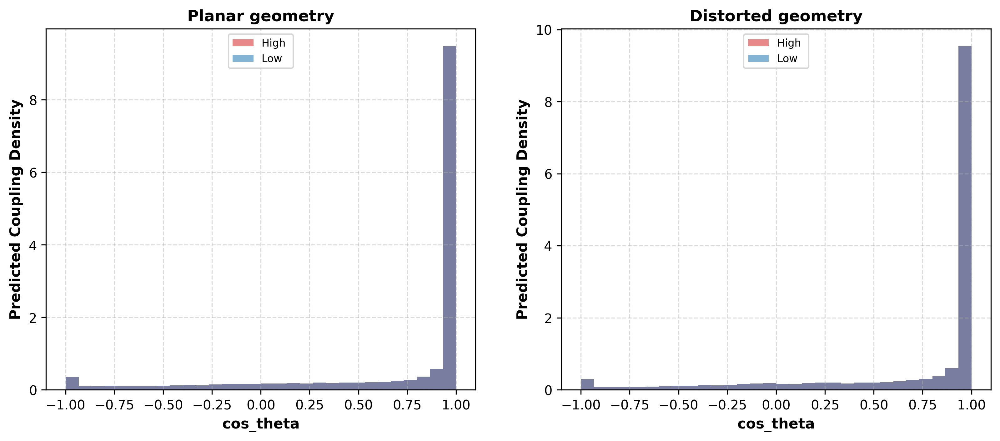

Saved high/low feature plot: ../four-model/MD-traj-result/first-last-5percent-coupling-features/full-coupling-features/KRR_cos_theta_high_vs_low.png


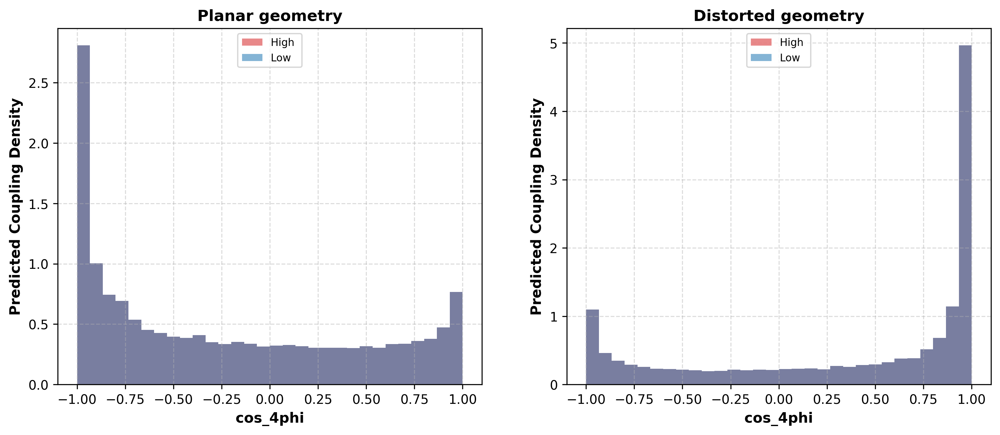

Saved high/low feature plot: ../four-model/MD-traj-result/first-last-5percent-coupling-features/full-coupling-features/KRR_cos_4phi_high_vs_low.png


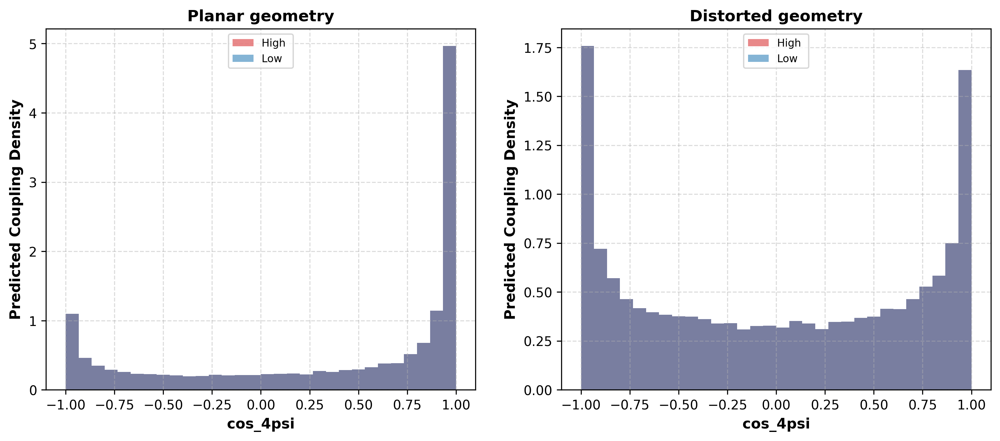

Saved high/low feature plot: ../four-model/MD-traj-result/first-last-5percent-coupling-features/full-coupling-features/KRR_cos_4psi_high_vs_low.png


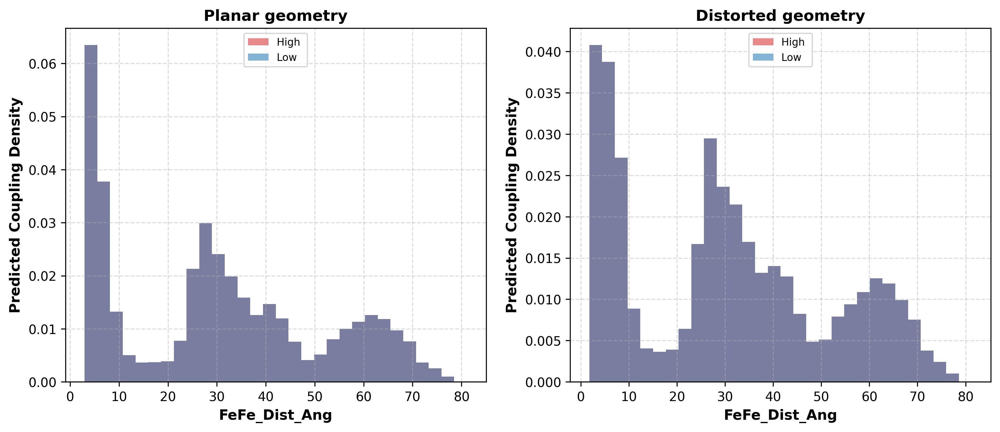

Saved high/low feature plot: ../four-model/MD-traj-result/first-last-5percent-coupling-features/full-coupling-features/KRR_FeFe_Dist_Ang_high_vs_low.png

Saved high/low feature summary: ../four-model/MD-traj-result/first-last-5percent-coupling-features/full-coupling-features/high_low_all_feature_summary.csv


In [14]:
# use random forest /KRR Coupling prediction for the MD trajectories and plot feature analysis for high coupling 5% and low coupling 5% MD trajectory frames features for planar and distorted geometries
# the path for RF coupling prediction results for planar and distorted geometries
rf_coupling_results = {
    "planar": "../four-model/MD-traj-result/RF_P1_planar_predicted_couplings.csv",
    "distorted": "../four-model/MD-traj-result/RF_P1_distorted_predicted_couplings.csv",
}
# the path for KRR coupling prediction results for planar and distorted geometries
krr_coupling_results = {
    "planar": "../four-model/MD-traj-result/KRR_P1_planar_predicted_couplings.csv",
    "distorted": "../four-model/MD-traj-result/KRR_P1_distorted_predicted_couplings.csv",
}
output_dir = "../four-model/MD-traj-result/first-last-5percent-coupling-features/full-coupling-features"
os.makedirs(output_dir, exist_ok=True)

coupling_col = "pred_coupling_meV"
top_frac = 1
group_colors = {"High ": "#d62728", "Low ": "#1f77b4"}

model_coupling_sources = {
    "RF": rf_coupling_results,
    "KRR": krr_coupling_results,
}
# RF coupling prediciton with all five features (low and high coupling)
# -----------------------------------------------------------------
grouped_data = {}
for model_name, geom_sources in model_coupling_sources.items():
    for geometry_name, csv_path in geom_sources.items():
        if not os.path.exists(csv_path):
            print(f"Skipping {model_name}-{geometry_name}: file not found at {csv_path}")
            continue

        df_pred = pd.read_csv(csv_path)
        if coupling_col not in df_pred.columns:
            print(f"Skipping {model_name}-{geometry_name}: '{coupling_col}' not found in {csv_path}")
            continue

        n_rows = len(df_pred)
        n_top = max(1, int(np.ceil(n_rows * top_frac)))

        df_sorted = df_pred.sort_values(coupling_col, ascending=False).reset_index(drop=True)
        high_df = df_sorted.iloc[:n_top].copy()
        low_df = df_sorted.iloc[-n_top:].copy()

        grouped_data[(model_name, geometry_name)] = {"High ": high_df, "Low ": low_df}
        print(f"{model_name}-{geometry_name}: {n_rows} frames, top/bottom {n_top} frames selected")

# -----------------------------------------------------------------
# Per-feature distribution plots: High vs Low coupling, split by geometry
# -----------------------------------------------------------------
for model_name in model_coupling_sources:
    for feature_name in default_features:
        available_geoms = [
            geometry_name
            for (m, geometry_name) in grouped_data
            if m == model_name and feature_name in grouped_data[(m, geometry_name)]["High "].columns
        ]
        if not available_geoms:
            continue

        fig, axes = plt.subplots(1, len(available_geoms), figsize=(6.5 * len(available_geoms), 5), dpi=300)
        axes = np.atleast_1d(axes)

        for ax, geometry_name in zip(axes, available_geoms):
            groups = grouped_data[(model_name, geometry_name)]
            for group_label, df_group in groups.items():
                ax.hist(
                    df_group[feature_name],
                    bins=30,
                    alpha=0.55,
                    color=group_colors[group_label],
                    label=group_label,
                    density=True,
                )
            ax.set_title(f"{geometry_name.capitalize()} geometry", fontsize=12, fontweight="bold")
            ax.set_xlabel(feature_name, fontsize=11, fontweight="bold")
            ax.set_ylabel("Predicted Coupling Density", fontsize=11, fontweight="bold")
            ax.grid(True, linestyle="--", alpha=0.45)
            ax.legend(loc="upper center", fontsize=8, frameon=True, facecolor="white", edgecolor="#cccccc")

        # axes[0].set_ylabel("Density", fontsize=11, fontweight="bold")
        # fig.suptitle(f"{model_name}: {feature_name} (High 5% vs Low 5% Coupling)", fontsize=13, fontweight="bold", y=1.02)
        # fig.tight_layout()

        out_png = os.path.join(output_dir, f"{model_name}_{feature_name}_high_vs_low.png")
        fig.savefig(out_png, dpi=300, bbox_inches="tight")
        plt.show()
        print(f"Saved high/low feature plot: {out_png}")

# -----------------------------------------------------------------
# Summary table: mean/median feature values for each group
# -----------------------------------------------------------------
summary_rows = []
for (model_name, geometry_name), groups in grouped_data.items():
    for group_label, df_group in groups.items():
        row = {"Model": model_name, "Geometry": geometry_name, "Group": group_label, "N_Frames": len(df_group)}
        for feature_name in default_features:
            if feature_name in df_group.columns:
                row[f"{feature_name}_mean"] = float(df_group[feature_name].mean())
                row[f"{feature_name}_median"] = float(df_group[feature_name].median())
        summary_rows.append(row)

if summary_rows:
    summary_df = pd.DataFrame(summary_rows).sort_values(["Model", "Geometry", "Group"]).reset_index(drop=True)
    summary_csv_path = os.path.join(output_dir, "high_low_all_feature_summary.csv")
    summary_df.to_csv(summary_csv_path, index=False)
    print(f"\nSaved high/low feature summary: {summary_csv_path}")
    summary_df
else:
    print("No groups were generated. Check RF/KRR coupling prediction CSV paths.")

# first and last 5% Coupling of total MD trajectories features

RF-planar: 20002 frames, top/bottom 1001 frames selected
RF-distorted: 20002 frames, top/bottom 1001 frames selected
KRR-planar: 20002 frames, top/bottom 1001 frames selected
KRR-distorted: 20002 frames, top/bottom 1001 frames selected


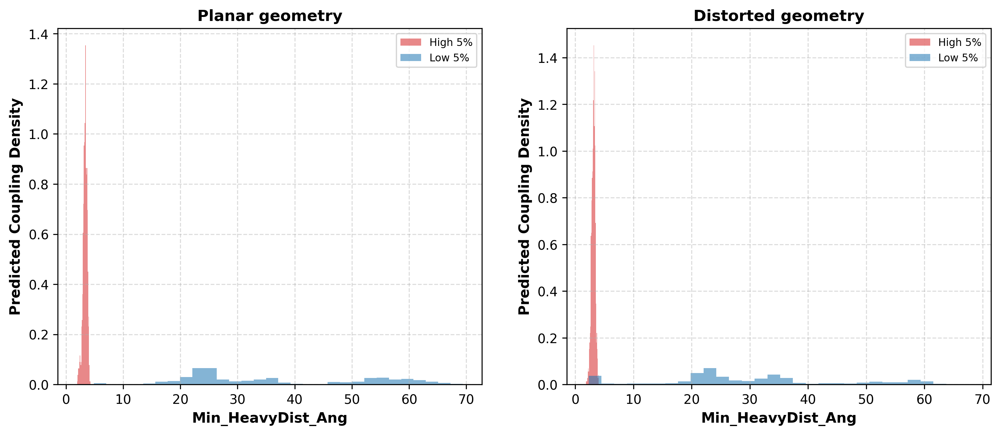

Saved high/low 5% feature plot: ../four-model/MD-traj-result/first-last-5percent-coupling-features/RF_Min_HeavyDist_Ang_high_vs_low_5pct.png


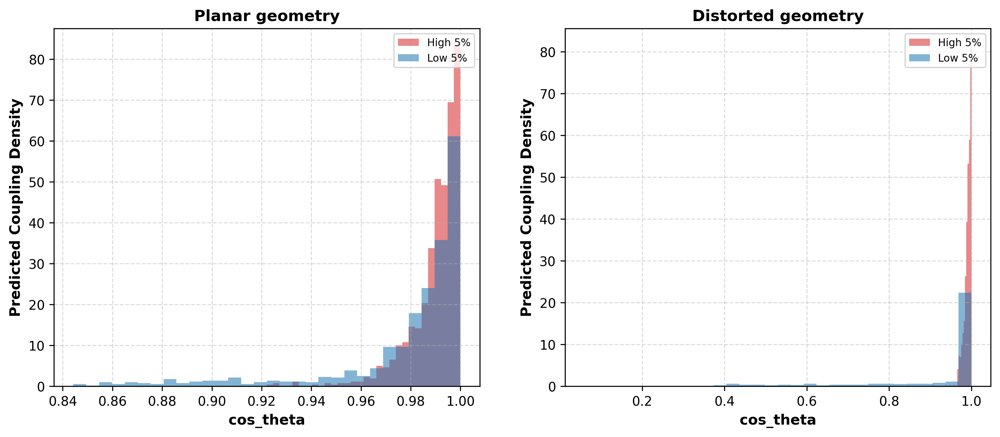

Saved high/low 5% feature plot: ../four-model/MD-traj-result/first-last-5percent-coupling-features/RF_cos_theta_high_vs_low_5pct.png


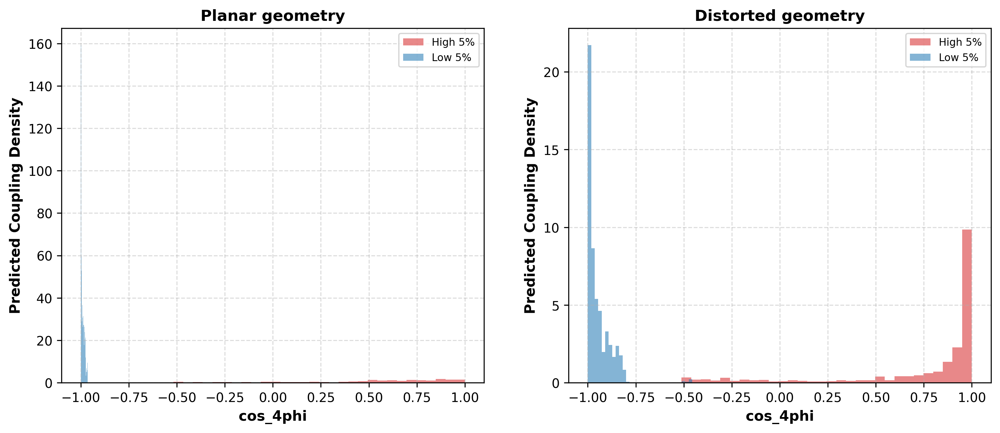

Saved high/low 5% feature plot: ../four-model/MD-traj-result/first-last-5percent-coupling-features/RF_cos_4phi_high_vs_low_5pct.png


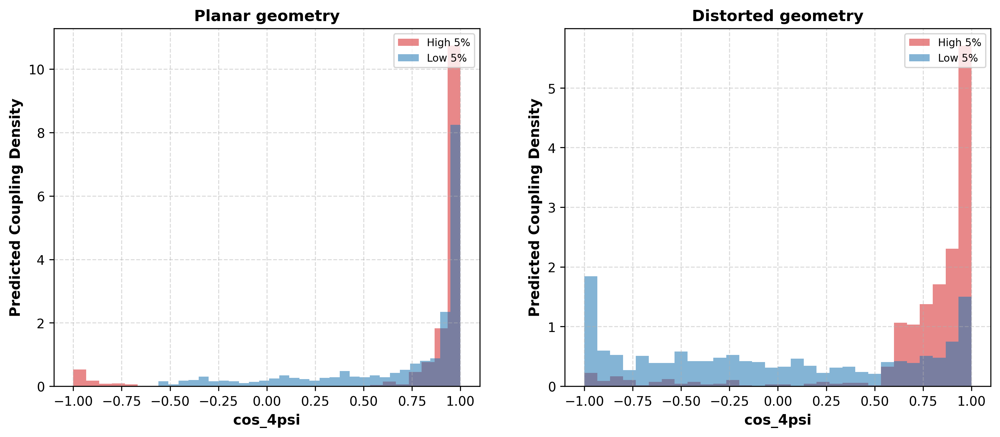

Saved high/low 5% feature plot: ../four-model/MD-traj-result/first-last-5percent-coupling-features/RF_cos_4psi_high_vs_low_5pct.png


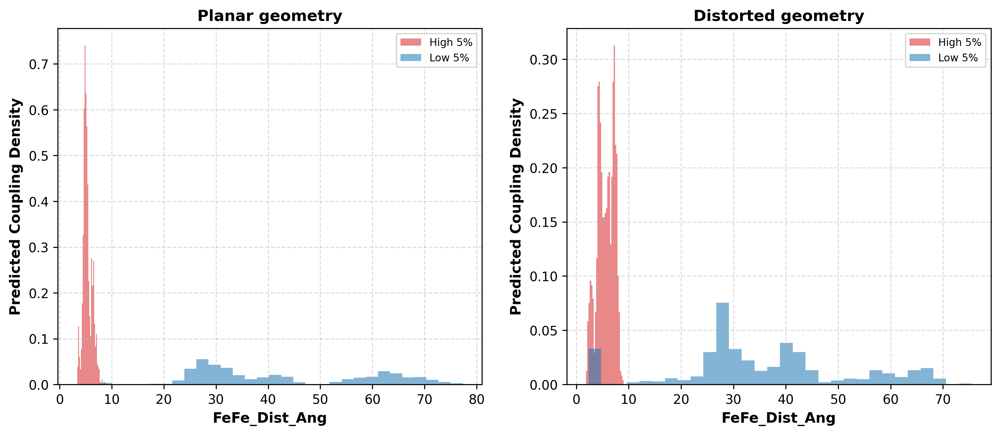

Saved high/low 5% feature plot: ../four-model/MD-traj-result/first-last-5percent-coupling-features/RF_FeFe_Dist_Ang_high_vs_low_5pct.png


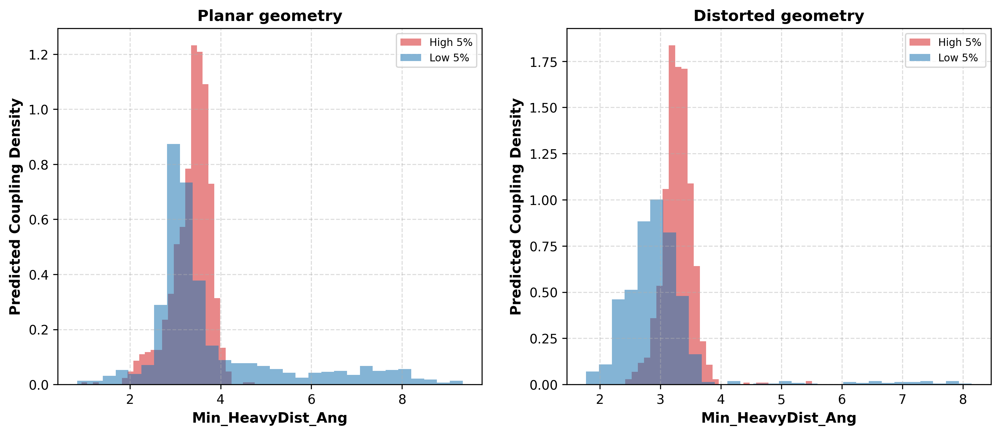

Saved high/low 5% feature plot: ../four-model/MD-traj-result/first-last-5percent-coupling-features/KRR_Min_HeavyDist_Ang_high_vs_low_5pct.png


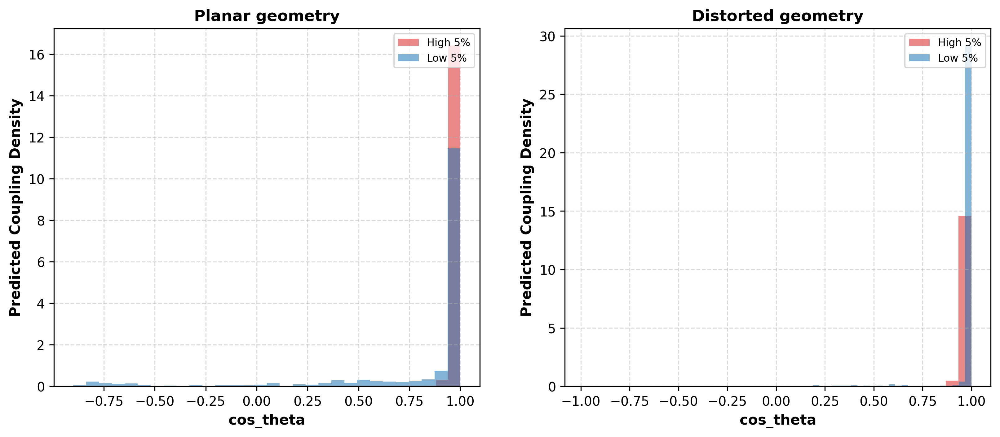

Saved high/low 5% feature plot: ../four-model/MD-traj-result/first-last-5percent-coupling-features/KRR_cos_theta_high_vs_low_5pct.png


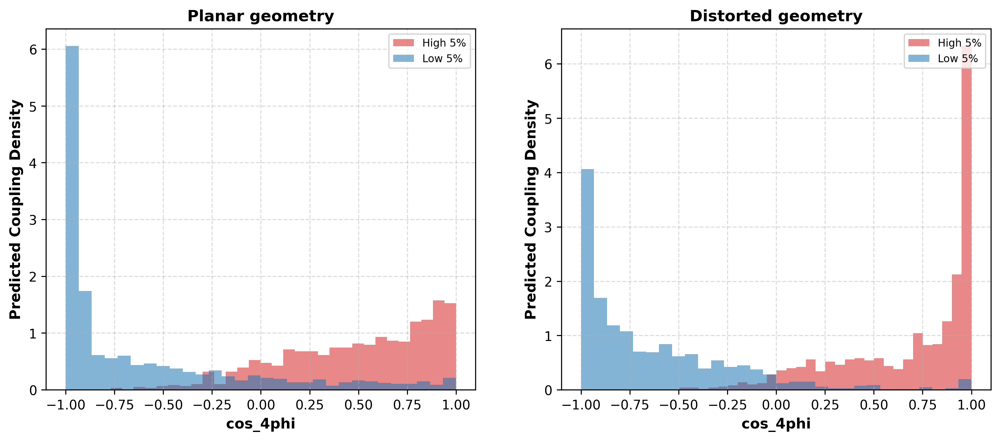

Saved high/low 5% feature plot: ../four-model/MD-traj-result/first-last-5percent-coupling-features/KRR_cos_4phi_high_vs_low_5pct.png


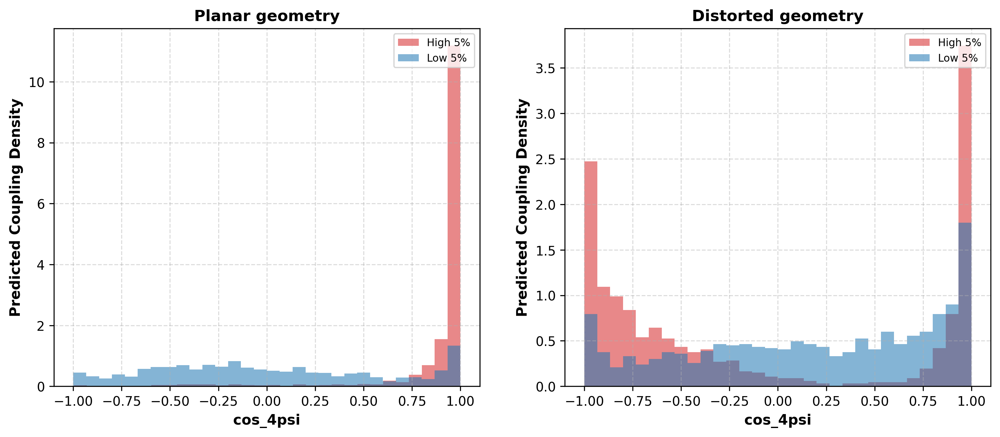

Saved high/low 5% feature plot: ../four-model/MD-traj-result/first-last-5percent-coupling-features/KRR_cos_4psi_high_vs_low_5pct.png


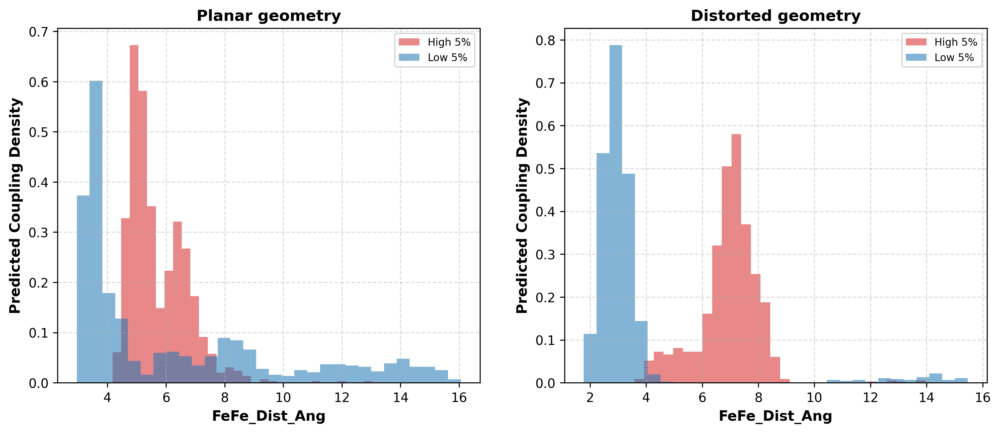

Saved high/low 5% feature plot: ../four-model/MD-traj-result/first-last-5percent-coupling-features/KRR_FeFe_Dist_Ang_high_vs_low_5pct.png

Saved high/low 5% feature summary: ../four-model/MD-traj-result/first-last-5percent-coupling-features/high_low_5pct_feature_summary.csv


In [ ]:
# use random forest /KRR Coupling prediction for the MD trajectories and plot feature analysis for high coupling 5% and low coupling 5% MD trajectory frames features for planar and distorted geometries
# the path for RF coupling prediction results for planar and distorted geometries
rf_coupling_results = {
    "planar": "../four-model/MD-traj-result/RF_P1_planar_predicted_couplings.csv",
    "distorted": "../four-model/MD-traj-result/RF_P1_distorted_predicted_couplings.csv",
}
# the path for KRR coupling prediction results for planar and distorted geometries
krr_coupling_results = {
    "planar": "../four-model/MD-traj-result/KRR_P1_planar_predicted_couplings.csv",
    "distorted": "../four-model/MD-traj-result/KRR_P1_distorted_predicted_couplings.csv",
}
# the path for XGB coupling prediction results for planar and distorted geometries
xgb_coupling_results = {
    "planar": "../four-model/MD-traj-result/XGB_P1_planar_predicted_couplings.csv",
    "distorted": "../four-model/MD-traj-result/XGB_P1_distorted_predicted_couplings.csv",
}
# the path for SVM coupling prediction results for planar and distorted geometries
svm_coupling_results = {
    "planar": "../four-model/MD-traj-result/SVM_P1_planar_predicted_couplings.csv",
    "distorted": "../four-model/MD-traj-result/SVM_P1_distorted_predicted_couplings.csv",
}
output_dir = "../four-model/MD-traj-result/first-last-5percent-coupling-features/RF-coup-features-only"
os.makedirs(output_dir, exist_ok=True)

coupling_col = "pred_coupling_meV"
top_frac = 0.05
group_colors = {"High 5%": "#d62728", "Low 5%": "#1f77b4"}

model_coupling_sources = {
    "RF": rf_coupling_results
    # "KRR": krr_coupling_results,
    # "SVM": svm_coupling_results,
    # "XGB": xgb_coupling_results,
}

# -----------------------------------------------------------------
# Load each model/geometry CSV and split into high-5% / low-5% coupling groups
#df_sorted = df_pred.sort_values(coupling_col, ascending=False).reset_index(drop=True)
#high_df = df_sorted.iloc[:n_top]   # first n_top rows = largest coupling values
#low_df  = df_sorted.iloc[-n_top:]  # last n_top rows  = smallest coupling values
# -----------------------------------------------------------------
grouped_data = {}
for model_name, geom_sources in model_coupling_sources.items():
    for geometry_name, csv_path in geom_sources.items():
        if not os.path.exists(csv_path):
            print(f"Skipping {model_name}-{geometry_name}: file not found at {csv_path}")
            continue

        df_pred = pd.read_csv(csv_path)
        if coupling_col not in df_pred.columns:
            print(f"Skipping {model_name}-{geometry_name}: '{coupling_col}' not found in {csv_path}")
            continue

        n_rows = len(df_pred)
        n_top = max(1, int(np.ceil(n_rows * top_frac)))

        df_sorted = df_pred.sort_values(coupling_col, ascending=False).reset_index(drop=True)
        high_df = df_sorted.iloc[:n_top].copy()
        low_df = df_sorted.iloc[-n_top:].copy()

        grouped_data[(model_name, geometry_name)] = {"High 5%": high_df, "Low 5%": low_df}
        print(f"{model_name}-{geometry_name}: {n_rows} frames, top/bottom {n_top} frames selected")

# -----------------------------------------------------------------
# Per-feature distribution plots: High 5% vs Low 5% coupling, split by geometry
# -----------------------------------------------------------------
for model_name in model_coupling_sources:
    for feature_name in default_features:
        available_geoms = [
            geometry_name
            for (m, geometry_name) in grouped_data
            if m == model_name and feature_name in grouped_data[(m, geometry_name)]["High 5%"].columns
        ]
        if not available_geoms:
            continue

        fig, axes = plt.subplots(1, len(available_geoms), figsize=(6.5 * len(available_geoms), 5), dpi=300)
        axes = np.atleast_1d(axes)

        for ax, geometry_name in zip(axes, available_geoms):
            groups = grouped_data[(model_name, geometry_name)]
            for group_label, df_group in groups.items():
                ax.hist(
                    df_group[feature_name],
                    bins=30,
                    alpha=0.55,
                    color=group_colors[group_label],
                    label=group_label,
                    density=True,
                )
            ax.set_title(f"{geometry_name.capitalize()} geometry", fontsize=12, fontweight="bold")
            ax.set_xlabel(feature_name, fontsize=11, fontweight="bold")
            ax.set_ylabel("Predicted Coupling Density", fontsize=11, fontweight="bold")
            ax.grid(True, linestyle="--", alpha=0.45)
            ax.legend(loc="upper center", fontsize=8, frameon=True, facecolor="white", edgecolor="#cccccc")

        # axes[0].set_ylabel("Density", fontsize=11, fontweight="bold")
        # fig.suptitle(f"{model_name}: {feature_name} (High 5% vs Low 5% Coupling)", fontsize=13, fontweight="bold", y=1.02)
        # fig.tight_layout()

        out_png = os.path.join(output_dir, f"{model_name}_{feature_name}_high_vs_low_5pct.png")
        fig.savefig(out_png, dpi=300, bbox_inches="tight")
        plt.show()
        print(f"Saved high/low 5% feature plot: {out_png}")

# -----------------------------------------------------------------
# Summary table: mean/median feature values for each group
# -----------------------------------------------------------------
summary_rows = []
for (model_name, geometry_name), groups in grouped_data.items():
    for group_label, df_group in groups.items():
        row = {"Model": model_name, "Geometry": geometry_name, "Group": group_label, "N_Frames": len(df_group)}
        for feature_name in default_features:
            if feature_name in df_group.columns:
                row[f"{feature_name}_mean"] = float(df_group[feature_name].mean())
                row[f"{feature_name}_median"] = float(df_group[feature_name].median())
        summary_rows.append(row)

if summary_rows:
    summary_df = pd.DataFrame(summary_rows).sort_values(["Model", "Geometry", "Group"]).reset_index(drop=True)
    summary_csv_path = os.path.join(output_dir, "high_low_5pct_feature_summary.csv")
    summary_df.to_csv(summary_csv_path, index=False)
    print(f"\nSaved high/low 5% feature summary: {summary_csv_path}")
    summary_df
else:
    print("No groups were generated. Check RF/KRR coupling prediction CSV paths.")

# feature of top and bottom 5% only for planar

RF planar: 20,002 frames total; top/bottom 1,001 frames selected (5%)


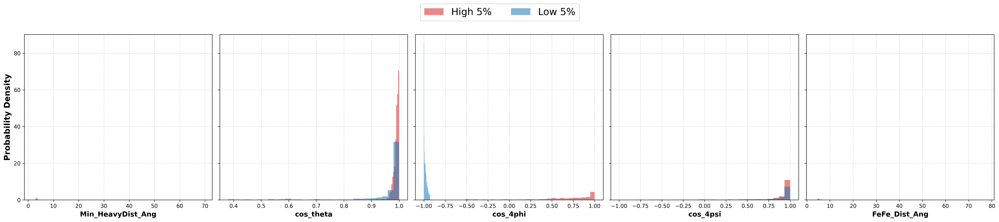

Saved combined feature distribution plot: ../four-model/MD-traj-result/planar_tanfunction_features/first-last-5percent-coupling-features/RF-coup-features-only/RF_planar_top_bottom_5pct_feature_distributions.png
Saved high/low 5% feature summary: ../four-model/MD-traj-result/planar_tanfunction_features/first-last-5percent-coupling-features/RF-coup-features-only/high_low_5pct_feature_summary.csv


,Model,Geometry,Group,N_Frames,Min_HeavyDist_Ang_mean,Min_HeavyDist_Ang_median,cos_theta_mean,cos_theta_median,cos_4phi_mean,cos_4phi_median,cos_4psi_mean,cos_4psi_median,FeFe_Dist_Ang_mean,FeFe_Dist_Ang_median
0,RF,planar,High 5%,1001,3.318930,3.369475,0.989314,0.992118,0.604166,0.733559,0.931375,0.974524,5.440274,5.204518
1,RF,planar,Low 5%,1001,36.327998,30.179469,0.937746,0.987473,-0.980894,-0.986327,0.658771,0.922566,42.407691,35.990486


In [21]:
# RF-only planar feature analysis: normalized probability density (PDF) of top vs bottom 5% coupling
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rf_planar_csv = "../four-model/MD-traj-result/planar_tanfunction_features/RF_P1_planar_predicted_couplings.csv"
output_dir = "../four-model/MD-traj-result/planar_tanfunction_features/first-last-5percent-coupling-features/RF-coup-features-only"
os.makedirs(output_dir, exist_ok=True)

coupling_col = "pred_coupling_meV"
top_frac = 0.05
default_features = ["Min_HeavyDist_Ang", "cos_theta", "cos_4phi", "cos_4psi", "FeFe_Dist_Ang"]
group_colors = {"High 5%": "#d62728", "Low 5%": "#1f77b4"}

if not os.path.exists(rf_planar_csv):
    raise FileNotFoundError(f"RF planar prediction file not found: {rf_planar_csv}")

df_pred = pd.read_csv(rf_planar_csv)
missing_cols = [c for c in default_features + [coupling_col] if c not in df_pred.columns]
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

n_rows = len(df_pred)
n_top = max(1, int(np.ceil(n_rows * top_frac)))

df_sorted = df_pred.sort_values(coupling_col, ascending=False).reset_index(drop=True)
high_df = df_sorted.iloc[:n_top].copy()
low_df = df_sorted.iloc[-n_top:].copy()
groups = {"High 5%": high_df, "Low 5%": low_df}

print(f"RF planar: {n_rows:,} frames total; top/bottom {n_top:,} frames selected ({top_frac:.0%})")

# Combined figure: one normalized PDF panel per geometric descriptor, sharing one y-axis and one legend.
n_features = len(default_features)
fig, axes = plt.subplots(1, n_features, figsize=(5.2 * n_features, 5.5), dpi=300, sharey=True)
axes = np.atleast_1d(axes)

for ax, feature_name in zip(axes, default_features):
    for group_label, df_group in groups.items():
        ax.hist(
            df_group[feature_name],
            bins=30,
            alpha=0.55,
            color=group_colors[group_label],
            label=group_label,
            density=True,  # normalize each histogram to a probability density function (PDF)
        )
    ax.set_xlabel(feature_name, fontsize=13, fontweight="bold")
    ax.grid(True, linestyle="--", alpha=0.45)

# Only the shared, left-most axis carries the y-axis label.
axes[0].set_ylabel("Probability Density", fontsize=15, fontweight="bold")

# One large, shared legend for the whole figure instead of per-panel legends.
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.06),
    ncol=len(groups),
    fontsize=18,
    frameon=True,
    facecolor="white",
    edgecolor="#cccccc",
    markerscale=2.0,
)

fig.tight_layout(rect=[0, 0, 1, 0.92])

out_png = os.path.join(output_dir, "RF_planar_top_bottom_5pct_feature_distributions.png")
fig.savefig(out_png, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved combined feature distribution plot: {out_png}")

# Summary table: mean/median feature values for each group.
summary_rows = []
for group_label, df_group in groups.items():
    row = {"Model": "RF", "Geometry": "planar", "Group": group_label, "N_Frames": len(df_group)}
    for feature_name in default_features:
        row[f"{feature_name}_mean"] = float(df_group[feature_name].mean())
        row[f"{feature_name}_median"] = float(df_group[feature_name].median())
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)
summary_csv_path = os.path.join(output_dir, "high_low_5pct_feature_summary.csv")
summary_df.to_csv(summary_csv_path, index=False)
print(f"Saved high/low 5% feature summary: {summary_csv_path}")
display(summary_df)

RF planar: 20,002 frames total; top/bottom 1,001 frames selected (5%)


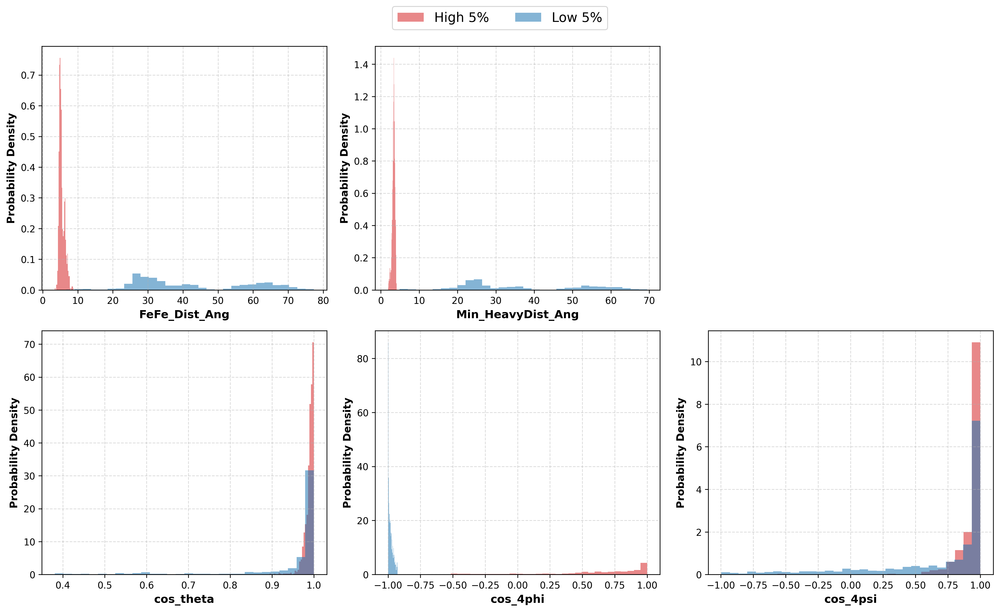

Saved combined feature distribution plot: ../four-model/MD-traj-result/planar_tanfunction_features/first-last-5percent-coupling-features/RF-coup-features-only/RF_planar_top_bottom_5pct_feature_distributions_redo.png


In [23]:
# RF-only planar feature analysis: normalized probability density (PDF) of top vs bottom 5% coupling
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rf_planar_csv = "../four-model/MD-traj-result/planar_tanfunction_features/RF_P1_planar_predicted_couplings.csv"
output_dir = "../four-model/MD-traj-result/planar_tanfunction_features/first-last-5percent-coupling-features/RF-coup-features-only"
os.makedirs(output_dir, exist_ok=True)

coupling_col = "pred_coupling_meV"
top_frac = 0.05
group_colors = {"High 5%": "#d62728", "Low 5%": "#1f77b4"}

# Categorize features into Distance (Row 1) and Angle (Row 2)
dist_features = ["FeFe_Dist_Ang", "Min_HeavyDist_Ang"]
angle_features = ["cos_theta", "cos_4phi", "cos_4psi"]

if not os.path.exists(rf_planar_csv):
    raise FileNotFoundError(f"RF planar prediction file not found: {rf_planar_csv}")

df_pred = pd.read_csv(rf_planar_csv)
all_features = dist_features + angle_features
missing_cols = [c for c in all_features + [coupling_col] if c not in df_pred.columns]
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

n_rows = len(df_pred)
n_top = max(1, int(np.ceil(n_rows * top_frac)))

df_sorted = df_pred.sort_values(coupling_col, ascending=False).reset_index(drop=True)
high_df = df_sorted.iloc[:n_top].copy()
low_df = df_sorted.iloc[-n_top:].copy()
groups = {"High 5%": high_df, "Low 5%": low_df}

print(f"RF planar: {n_rows:,} frames total; top/bottom {n_top:,} frames selected ({top_frac:.0%})")

# Create a 2x3 grid: NO sharey=True so distances and angles can auto-scale their y-axes
fig, axes = plt.subplots(2, 3, figsize=(15, 9), dpi=300)

# =====================================================================
# Row 1: Distance Features (2 plots + 1 empty panel)
# =====================================================================
for idx, feature_name in enumerate(dist_features):
    ax = axes[0, idx]
    for group_label, df_group in groups.items():
        ax.hist(
            df_group[feature_name],
            bins=30,
            alpha=0.55,
            color=group_colors[group_label],
            label=group_label,
            density=True,  # Normalized PDF
        )
    ax.set_xlabel(feature_name, fontsize=12, fontweight="bold")
    ax.set_ylabel("Probability Density", fontsize=11, fontweight="bold")
    ax.grid(True, linestyle="--", alpha=0.45)

# Turn off the empty top-right subplot (axes[0, 2])
axes[0, 2].axis("off")

# =====================================================================
# Row 2: Angle Features (3 plots)
# =====================================================================
for idx, feature_name in enumerate(angle_features):
    ax = axes[1, idx]
    for group_label, df_group in groups.items():
        ax.hist(
            df_group[feature_name],
            bins=30,
            alpha=0.55,
            color=group_colors[group_label],
            label=group_label,
            density=True,  # Normalized PDF
        )
    ax.set_xlabel(feature_name, fontsize=12, fontweight="bold")
    ax.set_ylabel("Probability Density", fontsize=11, fontweight="bold")
    ax.grid(True, linestyle="--", alpha=0.45)

# Shared Top Legend
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=len(groups),
    fontsize=14,
    frameon=True,
    facecolor="white",
    edgecolor="#cccccc",
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

out_png = os.path.join(output_dir, "RF_planar_top_bottom_5pct_feature_distributions_redo.png")
fig.savefig(out_png, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved combined feature distribution plot: {out_png}")

RF planar: 20,002 frames total; top/bottom 1,001 frames selected (5%)


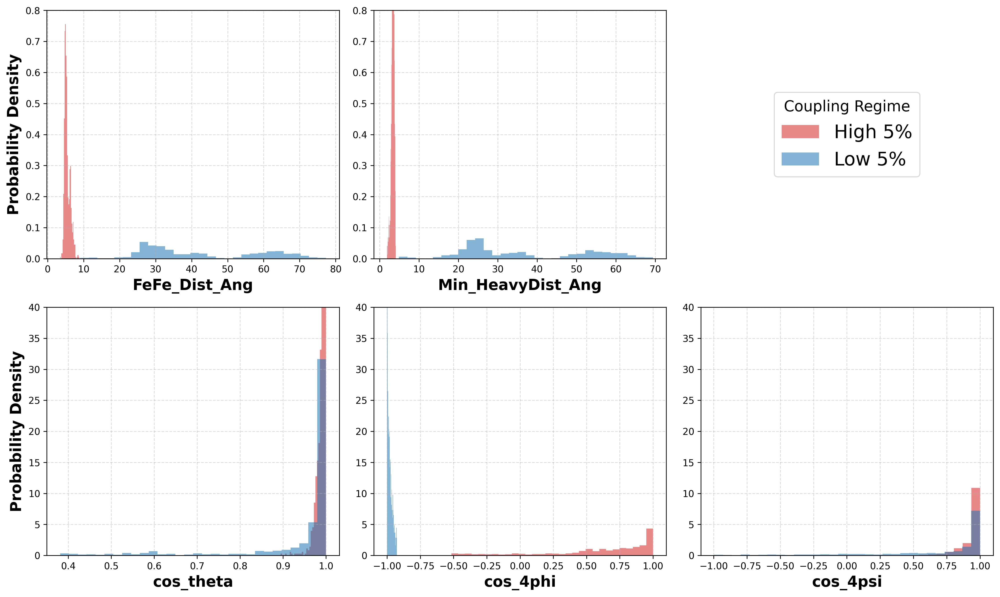

Saved combined feature distribution plot: ../four-model/MD-traj-result/planar_tanfunction_features/first-last-5percent-coupling-features/RF-coup-features-only/RF_planar_top_bottom_5pct_feature_distributions_1.png


In [6]:
# RF-only planar feature analysis: normalized probability density (PDF) of top vs bottom 5% coupling
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rf_planar_csv = "../four-model/MD-traj-result/planar_tanfunction_features/RF_P1_planar_predicted_couplings.csv"
output_dir = "../four-model/MD-traj-result/planar_tanfunction_features/first-last-5percent-coupling-features/RF-coup-features-only"
os.makedirs(output_dir, exist_ok=True)

coupling_col = "pred_coupling_meV"
top_frac = 0.05
group_colors = {"High 5%": "#d62728", "Low 5%": "#1f77b4"}

# Categorize features into Distance (Row 1) and Angle (Row 2)
dist_features = ["FeFe_Dist_Ang", "Min_HeavyDist_Ang"]
angle_features = ["cos_theta", "cos_4phi", "cos_4psi"]

if not os.path.exists(rf_planar_csv):
    raise FileNotFoundError(f"RF planar prediction file not found: {rf_planar_csv}")

df_pred = pd.read_csv(rf_planar_csv)
all_features = dist_features + angle_features
missing_cols = [c for c in all_features + [coupling_col] if c not in df_pred.columns]
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

n_rows = len(df_pred)
n_top = max(1, int(np.ceil(n_rows * top_frac)))

df_sorted = df_pred.sort_values(coupling_col, ascending=False).reset_index(drop=True)
high_df = df_sorted.iloc[:n_top].copy()
low_df = df_sorted.iloc[-n_top:].copy()
groups = {"High 5%": high_df, "Low 5%": low_df}

print(f"RF planar: {n_rows:,} frames total; top/bottom {n_top:,} frames selected ({top_frac:.0%})")

fig, axes = plt.subplots(2, 3, figsize=(15, 9), dpi=300)

# =====================================================================
# Row 1: Distance Features (Max Y = 0.7)
# =====================================================================
for idx, feature_name in enumerate(dist_features):
    ax = axes[0, idx]
    for group_label, df_group in groups.items():
        ax.hist(
            df_group[feature_name],
            bins=30,
            alpha=0.55,
            color=group_colors[group_label],
            label=group_label,
            density=True,  # Normalized PDF
        )
    ax.set_xlabel(feature_name, fontsize=16, fontweight="bold")
    ax.set_ylim(0, 0.8)
    
    # Show Y-axis label only on the first (leftmost) figure
    if idx == 0:
        ax.set_ylabel("Probability Density", fontsize=16, fontweight="bold")
    else:
        ax.set_ylabel("")
        
    ax.grid(True, linestyle="--", alpha=0.45)

# Place the large legend in the vacant top-right subplot space (axes[0, 2])
ax_vacant = axes[0, 2]
ax_vacant.axis("off")  # Hide axes borders and ticks

handles, labels = axes[0, 0].get_legend_handles_labels()
ax_vacant.legend(
    handles,
    labels,
    loc="center",
    fontsize=20,
    title="Coupling Regime",
    title_fontsize=16,
    frameon=True,
    facecolor="white",
    edgecolor="#cccccc",
)

# =====================================================================
# Row 2: Angle Features (Max Y = 40)
# =====================================================================
for idx, feature_name in enumerate(angle_features):
    ax = axes[1, idx]
    for group_label, df_group in groups.items():
        ax.hist(
            df_group[feature_name],
            bins=30,
            alpha=0.55,
            color=group_colors[group_label],
            label=group_label,
            density=True,  # Normalized PDF
        )
    ax.set_xlabel(feature_name, fontsize=16, fontweight="bold")
    ax.set_ylim(0, 40)
    
    # Show Y-axis label only on the first (leftmost) figure
    if idx == 0:
        ax.set_ylabel("Probability Density", fontsize=16, fontweight="bold")
    else:
        ax.set_ylabel("")
        
    ax.grid(True, linestyle="--", alpha=0.45)

plt.tight_layout()

out_png = os.path.join(output_dir, "RF_planar_top_bottom_5pct_feature_distributions_1.png")
fig.savefig(out_png, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved combined feature distribution plot: {out_png}")

# Same shared y-axis for distorted and planar coupling

RF-planar: 20002 frames, top/bottom 1001 frames selected
RF-distorted: 20002 frames, top/bottom 1001 frames selected


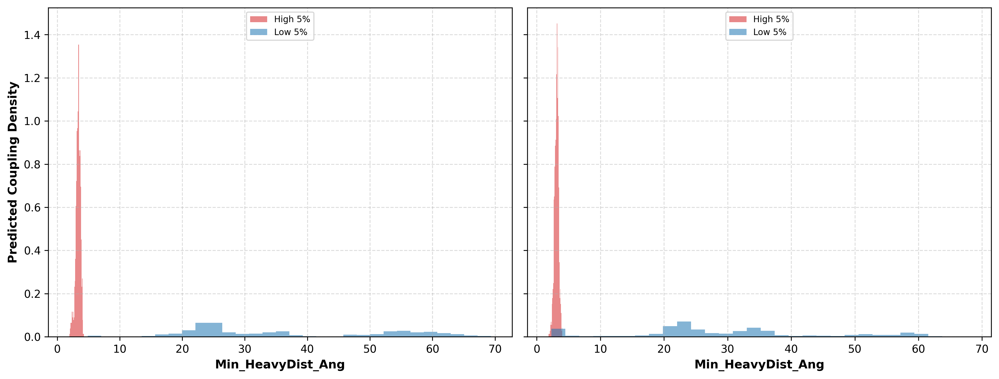

Saved high/low 5% feature plot: ../four-model/MD-traj-result/first-last-5percent-coupling-features/test-5percent-plot/RF_Min_HeavyDist_Ang_high_vs_low_5pct.png


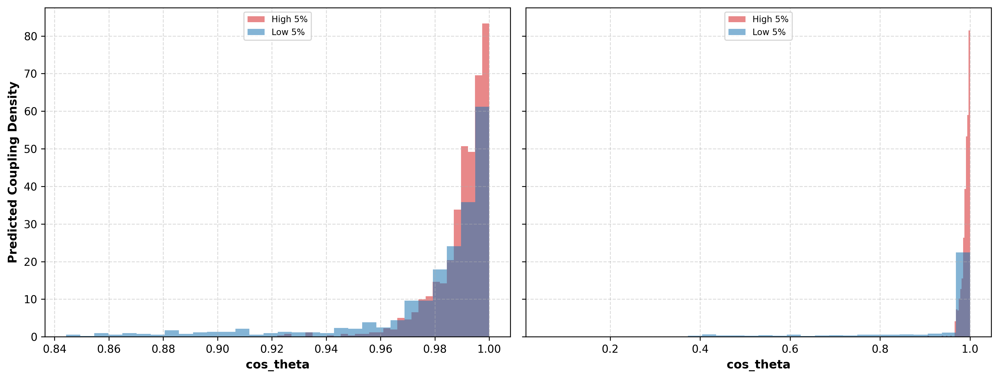

Saved high/low 5% feature plot: ../four-model/MD-traj-result/first-last-5percent-coupling-features/test-5percent-plot/RF_cos_theta_high_vs_low_5pct.png


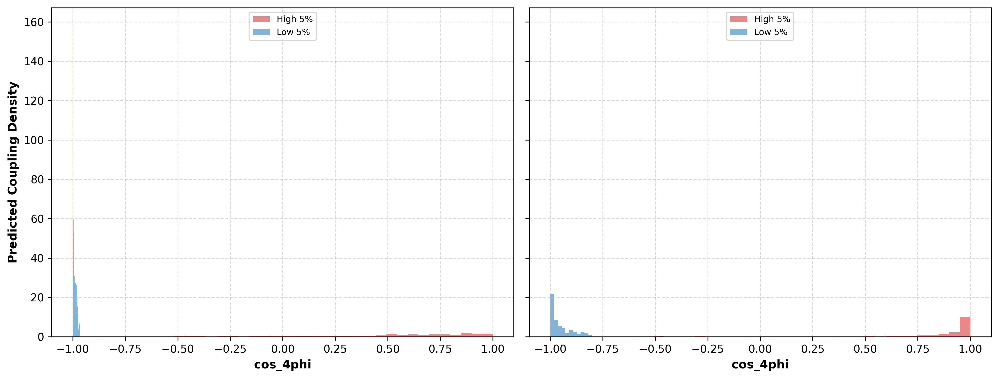

Saved high/low 5% feature plot: ../four-model/MD-traj-result/first-last-5percent-coupling-features/test-5percent-plot/RF_cos_4phi_high_vs_low_5pct.png


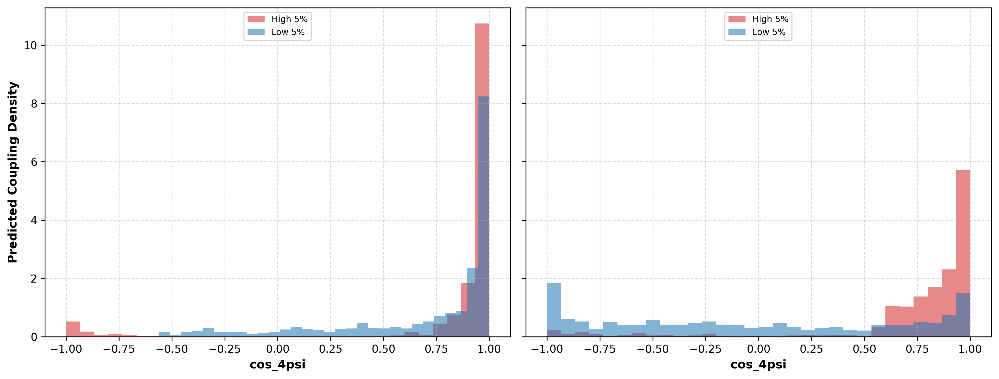

Saved high/low 5% feature plot: ../four-model/MD-traj-result/first-last-5percent-coupling-features/test-5percent-plot/RF_cos_4psi_high_vs_low_5pct.png


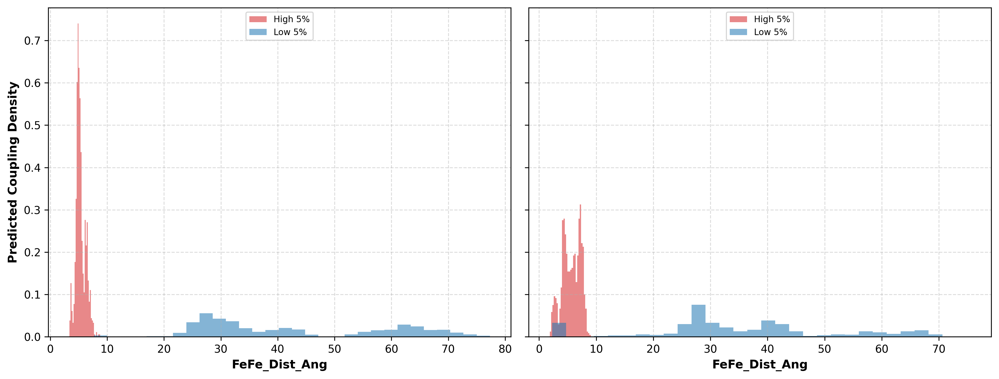

Saved high/low 5% feature plot: ../four-model/MD-traj-result/first-last-5percent-coupling-features/test-5percent-plot/RF_FeFe_Dist_Ang_high_vs_low_5pct.png

Saved high/low 5% feature summary: ../four-model/MD-traj-result/first-last-5percent-coupling-features/test-5percent-plot/high_low_5pct_feature_summary.csv


In [ ]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# use random forest /KRR Coupling prediction for the MD trajectories and plot feature analysis for high coupling 5% and low coupling 5% MD trajectory frames features for planar and distorted geometries
# the path for RF coupling prediction results for planar and distorted geometries
rf_coupling_results = {
    "planar": "../four-model/MD-traj-result/RF_P1_planar_predicted_couplings.csv",
    "distorted": "../four-model/MD-traj-result/RF_P1_distorted_predicted_couplings.csv",
}
default_features = [
    "FeFe_Dist_Ang",
    "Min_HeavyDist_Ang",
    "cos_theta",
    "cos_4phi",
    "cos_4psi"
    ]
# the path for KRR coupling prediction results for planar and distorted geometries
# krr_coupling_results = {
#     "planar": "../four-model/MD-traj-result/KRR_P1_planar_predicted_couplings.csv",
#     "distorted": "../four-model/MD-traj-result/KRR_P1_distorted_predicted_couplings.csv",
# }
# # the path for XGB coupling prediction results for planar and distorted geometries
# xgb_coupling_results = {
#     "planar": "../four-model/MD-traj-result/XGB_P1_planar_predicted_couplings.csv",
#     "distorted": "../four-model/MD-traj-result/XGB_P1_distorted_predicted_couplings.csv",
# }
# # the path for SVM coupling prediction results for planar and distorted geometries
# svm_coupling_results = {
#     "planar": "../four-model/MD-traj-result/SVM_P1_planar_predicted_couplings.csv",
#     "distorted": "../four-model/MD-traj-result/SVM_P1_distorted_predicted_couplings.csv",
# }
output_dir = "../four-model/MD-traj-result/first-last-5percent-coupling-features/test-5percent-plot"
os.makedirs(output_dir, exist_ok=True)

coupling_col = "pred_coupling_meV"
top_frac = 0.05
group_colors = {"High 5%": "#d62728", "Low 5%": "#1f77b4"}

model_coupling_sources = {
    "RF": rf_coupling_results
    # "KRR": krr_coupling_results,
    # "SVM": svm_coupling_results,
    # "XGB": xgb_coupling_results,
}

# -----------------------------------------------------------------
# Load each model/geometry CSV and split into high-5% / low-5% coupling groups
#df_sorted = df_pred.sort_values(coupling_col, ascending=False).reset_index(drop=True)
#high_df = df_sorted.iloc[:n_top]   # first n_top rows = largest coupling values
#low_df  = df_sorted.iloc[-n_top:]  # last n_top rows  = smallest coupling values
# -----------------------------------------------------------------
grouped_data = {}
for model_name, geom_sources in model_coupling_sources.items():
    for geometry_name, csv_path in geom_sources.items():
        if not os.path.exists(csv_path):
            print(f"Skipping {model_name}-{geometry_name}: file not found at {csv_path}")
            continue

        df_pred = pd.read_csv(csv_path)
        if coupling_col not in df_pred.columns:
            print(f"Skipping {model_name}-{geometry_name}: '{coupling_col}' not found in {csv_path}")
            continue

        n_rows = len(df_pred)
        n_top = max(1, int(np.ceil(n_rows * top_frac)))

        df_sorted = df_pred.sort_values(coupling_col, ascending=False).reset_index(drop=True)
        high_df = df_sorted.iloc[:n_top].copy()
        low_df = df_sorted.iloc[-n_top:].copy()

        grouped_data[(model_name, geometry_name)] = {"High 5%": high_df, "Low 5%": low_df}
        print(f"{model_name}-{geometry_name}: {n_rows} frames, top/bottom {n_top} frames selected")

# -----------------------------------------------------------------
# Per-feature distribution plots: High 5% vs Low 5% coupling, split by geometry
# -----------------------------------------------------------------
for model_name in model_coupling_sources:
    for feature_name in default_features:
        available_geoms = [
            geometry_name
            for (m, geometry_name) in grouped_data
            if m == model_name and feature_name in grouped_data[(m, geometry_name)]["High 5%"].columns
        ]
        if not available_geoms:
            continue

        # fig, axes = plt.subplots(1, len(available_geoms), figsize=(6.5 * len(available_geoms), 5), dpi=300)
        # axes = np.atleast_1d(axes)

        # Add sharey=True here to synchronize the y-axis for planar and distorted subplots
        fig, axes = plt.subplots(1, len(available_geoms), figsize=(6.5 * len(available_geoms), 5), dpi=300, sharey=True)
        axes = np.atleast_1d(axes)

        for ax, geometry_name in zip(axes, available_geoms):
            groups = grouped_data[(model_name, geometry_name)]
            for group_label, df_group in groups.items():
                ax.hist(
                    df_group[feature_name],
                    bins=30,
                    alpha=0.55,
                    color=group_colors[group_label],
                    label=group_label,
                    density=True,
                )
            #ax.set_title(f"{geometry_name.capitalize()} geometry", fontsize=12, fontweight="bold")
            ax.set_xlabel(feature_name, fontsize=11, fontweight="bold")
            #ax.set_ylabel("Predicted Coupling Density", fontsize=11, fontweight="bold")
            ax.grid(True, linestyle="--", alpha=0.45)
            ax.legend(loc="upper center", fontsize=8, frameon=True, facecolor="white", edgecolor="#cccccc")

        # axes[0].set_ylabel("Density", fontsize=11, fontweight="bold")
        # fig.suptitle(f"{model_name}: {feature_name} (High 5% vs Low 5% Coupling)", fontsize=13, fontweight="bold", y=1.02)
        # fig.tight_layout()

        # Set the y-axis label uniformly on the shared axis
        axes[0].set_ylabel("Predicted Coupling Density", fontsize=11, fontweight="bold")
        fig.tight_layout()

        out_png = os.path.join(output_dir, f"{model_name}_{feature_name}_high_vs_low_5pct.png")
        fig.savefig(out_png, dpi=300, bbox_inches="tight")
        plt.show()
        print(f"Saved high/low 5% feature plot: {out_png}")

# -----------------------------------------------------------------
# Summary table: mean/median feature values for each group
# -----------------------------------------------------------------
summary_rows = []
for (model_name, geometry_name), groups in grouped_data.items():
    for group_label, df_group in groups.items():
        row = {"Model": model_name, "Geometry": geometry_name, "Group": group_label, "N_Frames": len(df_group)}
        for feature_name in default_features:
            if feature_name in df_group.columns:
                row[f"{feature_name}_mean"] = float(df_group[feature_name].mean())
                row[f"{feature_name}_median"] = float(df_group[feature_name].median())
        summary_rows.append(row)

if summary_rows:
    summary_df = pd.DataFrame(summary_rows).sort_values(["Model", "Geometry", "Group"]).reset_index(drop=True)
    summary_csv_path = os.path.join(output_dir, "high_low_5pct_feature_summary.csv")
    summary_df.to_csv(summary_csv_path, index=False)
    print(f"\nSaved high/low 5% feature summary: {summary_csv_path}")
    summary_df
else:
    print("No groups were generated. Check RF/KRR coupling prediction CSV paths.")

Saved far-distance diagnostic summary: ../four-model/MD-traj-result/planar_tanfunction_features/model_Rfefe_coup_plot/far_distance_coupling_diagnostic.csv
  Model Geometry  N_Total_Frames  N_Frames_FeFe_Dist_Ang_gt_12A  \
0   KRR   planar           20002                          13894   
1   SVM   planar           20002                          13894   
2    RF   planar           20002                          13894   
3   XGB   planar           20002                          13894   

   Far_Coupling_Mean_meV  Far_Coupling_Median_meV  Far_Coupling_Min_meV  \
0               2.444397                 2.466199              0.001777   
1               0.956247                 0.956688              0.494509   
2               0.150465                 0.134254              0.029859   
3               0.228526                 0.228002              0.028030   

   Far_Coupling_Max_meV  All_Coupling_Median_meV  
0            154.385380                 2.466199  
1              1.153879        

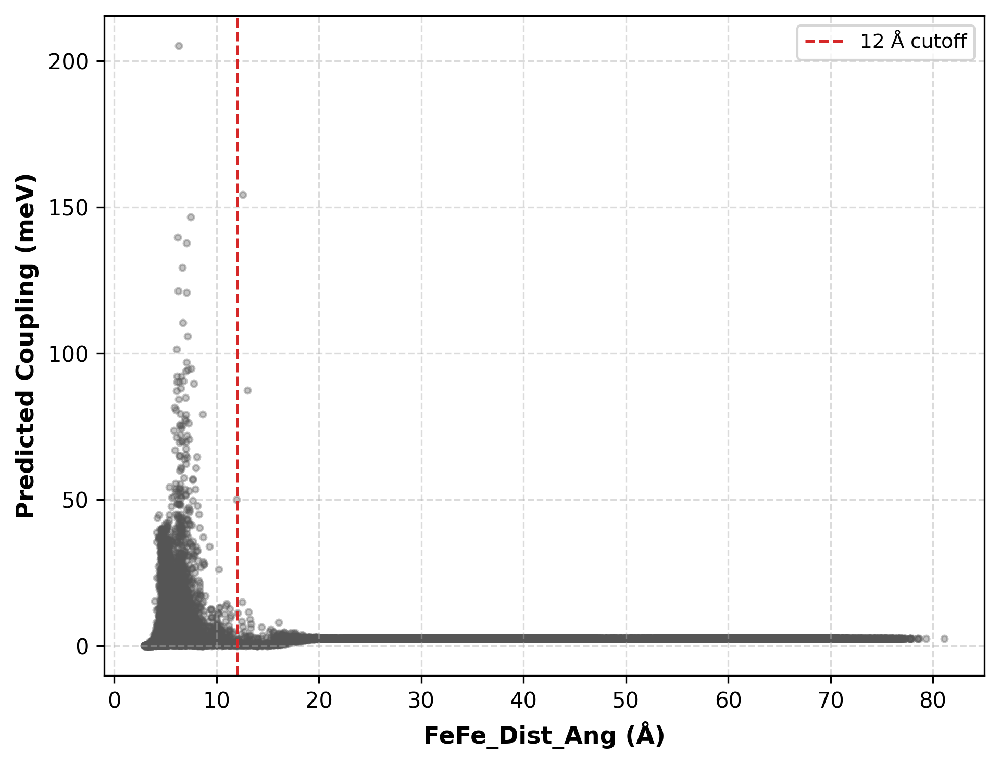

Saved diagnostic scatter plot: ../four-model/MD-traj-result/planar_tanfunction_features/model_Rfefe_coup_plot/KRR_coupling_vs_FeFe_Dist_Ang_diagnostic.png


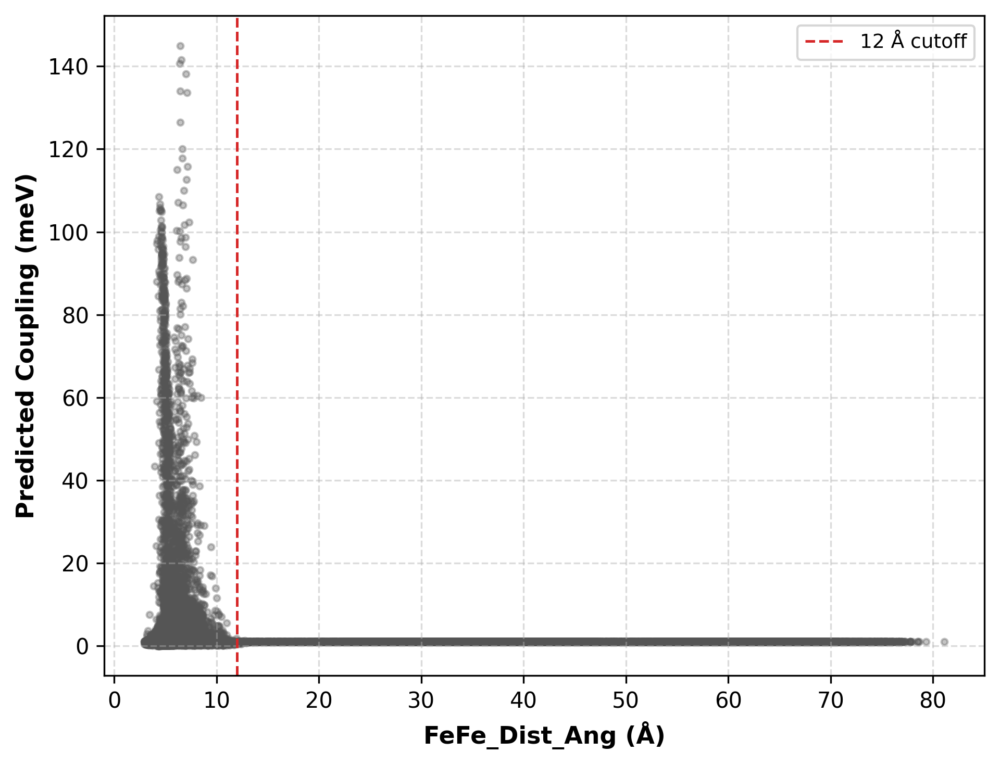

Saved diagnostic scatter plot: ../four-model/MD-traj-result/planar_tanfunction_features/model_Rfefe_coup_plot/SVM_coupling_vs_FeFe_Dist_Ang_diagnostic.png


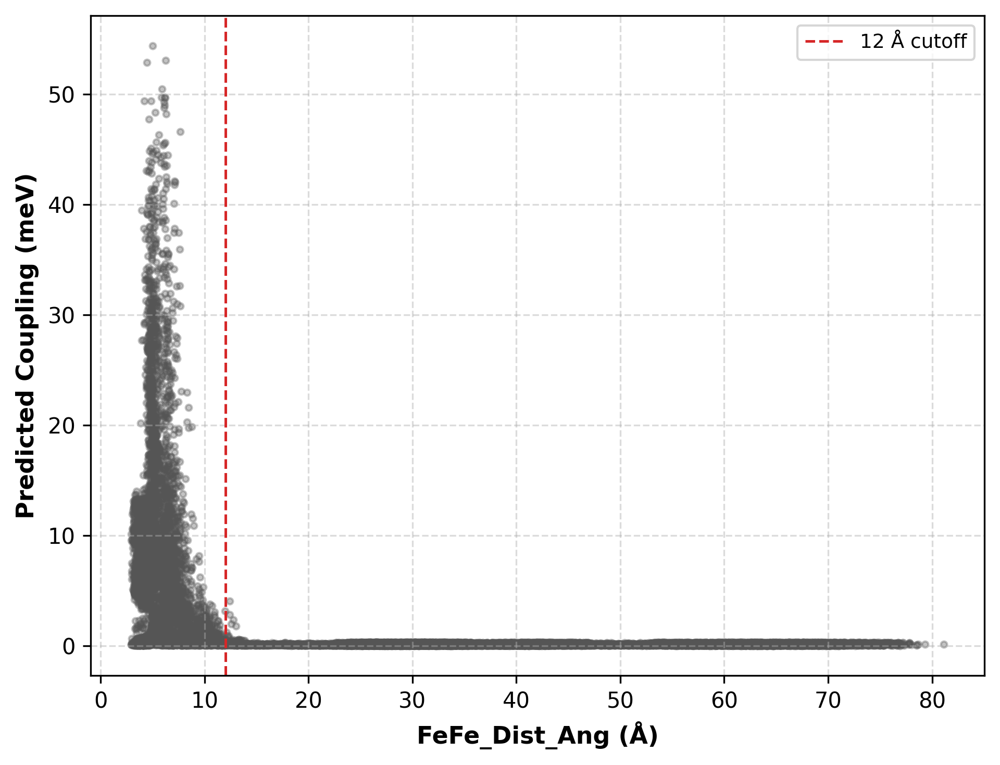

Saved diagnostic scatter plot: ../four-model/MD-traj-result/planar_tanfunction_features/model_Rfefe_coup_plot/RF_coupling_vs_FeFe_Dist_Ang_diagnostic.png


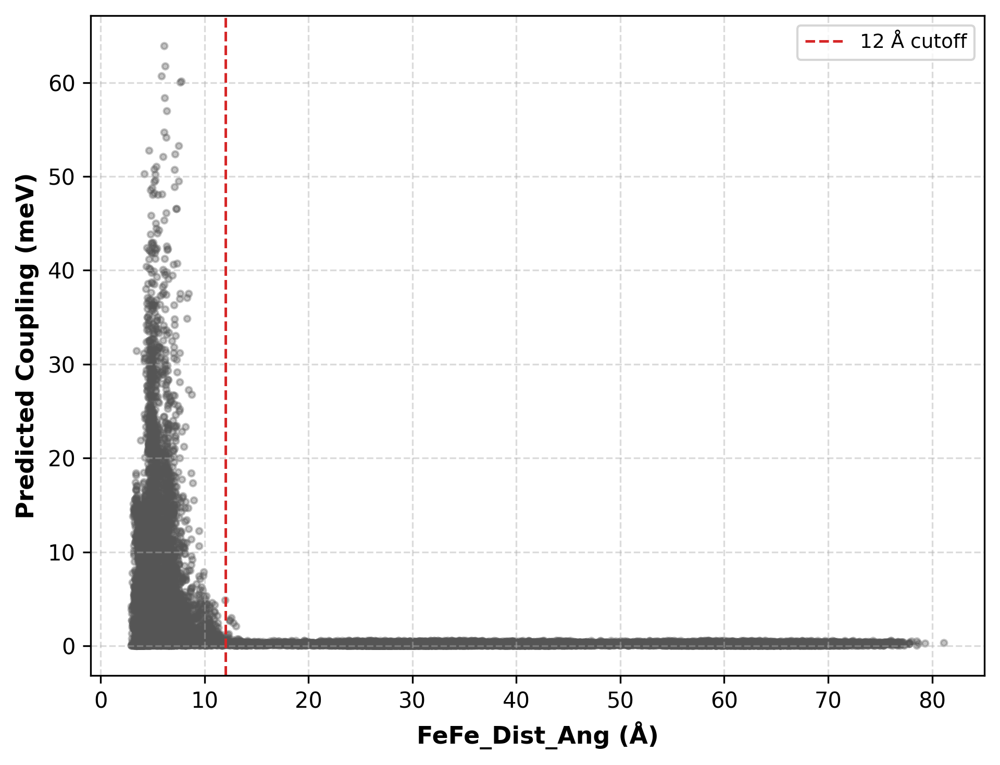

Saved diagnostic scatter plot: ../four-model/MD-traj-result/planar_tanfunction_features/model_Rfefe_coup_plot/XGB_coupling_vs_FeFe_Dist_Ang_diagnostic.png


In [21]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------------------------------------------
# Configuration & Inputs
# -----------------------------------------------------------------
coup_files = {
    "KRR": "../four-model/MD-traj-result/planar_tanfunction_features/KRR_P1_planar_predicted_couplings.csv",
    "SVM": "../four-model/MD-traj-result/planar_tanfunction_features/SVM_P1_planar_predicted_couplings.csv",
    "RF": "../four-model/MD-traj-result/planar_tanfunction_features/RF_P1_planar_predicted_couplings.csv",
    "XGB": "../four-model/MD-traj-result/planar_tanfunction_features/XGB_P1_planar_predicted_couplings.csv",
    
}

distance_col = "FeFe_Dist_Ang"
coupling_col = "pred_coupling_meV"  # Adjust this to match your CSV column name (e.g. 'predicted_coupling', 'V_ab_meV', etc.)
far_distance_threshold_ang = 12.0
output_dir = "../four-model/MD-traj-result/planar_tanfunction_features/model_Rfefe_coup_plot"

os.makedirs(output_dir, exist_ok=True)

# -----------------------------------------------------------------
# Diagnostic Summary Table
# -----------------------------------------------------------------
diagnostic_rows = []

for model_name, csv_path in coup_files.items():
    geometry_name = "planar"
    
    if not os.path.exists(csv_path):
        print(f"File not found: {csv_path}")
        continue

    df_pred = pd.read_csv(csv_path)
    if distance_col not in df_pred.columns or coupling_col not in df_pred.columns:
        print(f"Skipping {model_name}-{geometry_name}: missing '{distance_col}' or '{coupling_col}' in {csv_path}")
        continue

    far_mask = df_pred[distance_col] > far_distance_threshold_ang
    n_far = int(far_mask.sum())
    n_total = int(len(df_pred))

    far_coupling = df_pred.loc[far_mask, coupling_col] if n_far > 0 else pd.Series(dtype=float)
    
    diagnostic_rows.append({
        "Model": model_name,
        "Geometry": geometry_name,
        "N_Total_Frames": n_total,
        f"N_Frames_{distance_col}_gt_{far_distance_threshold_ang:g}A": n_far,
        "Far_Coupling_Mean_meV": float(far_coupling.mean()) if n_far > 0 else np.nan,
        "Far_Coupling_Median_meV": float(far_coupling.median()) if n_far > 0 else np.nan,
        "Far_Coupling_Min_meV": float(far_coupling.min()) if n_far > 0 else np.nan,
        "Far_Coupling_Max_meV": float(far_coupling.max()) if n_far > 0 else np.nan,
        "All_Coupling_Median_meV": float(df_pred[coupling_col].median()),
    })

diagnostic_df = pd.DataFrame(diagnostic_rows)
diagnostic_csv_path = os.path.join(output_dir, "far_distance_coupling_diagnostic.csv")
diagnostic_df.to_csv(diagnostic_csv_path, index=False)
print(f"Saved far-distance diagnostic summary: {diagnostic_csv_path}")
print(diagnostic_df)

# -----------------------------------------------------------------
# Scatter Plots: pred_coupling vs R_FeFe for each model
# -----------------------------------------------------------------
for model_name, csv_path in coup_files.items():
    if not os.path.exists(csv_path):
        continue

    df_pred = pd.read_csv(csv_path)
    if distance_col not in df_pred.columns or coupling_col not in df_pred.columns:
        continue

    fig, ax = plt.subplots(figsize=(6.5, 5), dpi=300)

    ax.scatter(df_pred[distance_col], df_pred[coupling_col], s=8, alpha=0.35, color="#555555")
    ax.axvline(far_distance_threshold_ang, color="#d62728", linestyle="--", linewidth=1.2, 
               label=f"{far_distance_threshold_ang:g} Å cutoff")
    
    #ax.set_title(f"{model_name}: Predicted Coupling vs {distance_col} (Planar)", fontsize=12, fontweight="bold")
    ax.set_xlabel(f"{distance_col} (Å)", fontsize=11, fontweight="bold")
    ax.set_ylabel("Predicted Coupling (meV)", fontsize=11, fontweight="bold")
    ax.grid(True, linestyle="--", alpha=0.45)
    ax.legend(loc="upper right", fontsize=9, frameon=True, facecolor="white", edgecolor="#cccccc")

    fig.tight_layout()

    out_png = os.path.join(output_dir, f"{model_name}_coupling_vs_{distance_col}_diagnostic.png")
    fig.savefig(out_png, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved diagnostic scatter plot: {out_png}")